In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02
# SECTION 1: SOURCE MANIFEST & MASK SEMANTICS
# Version: 1.0
# READ-ONLY INPUTS | NO TRAINING | NO METRIC LABELS
# ============================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from PIL import Image
import csv
import hashlib
import json

# ------------------------------------------------------------
# 1. CONNECT DRIVE AND DEFINE PATHS
# ------------------------------------------------------------

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive")

PROJECT = (
    DRIVE / "crdl_experiments"
    / "component3_fresh_v1"
)

DATA = DRIVE / "manushi_research_data"

FAN = (
    DATA / "fan_stereo_pothole"
    / "stereo_pothole_datasets-master"
)

GATE_DIR = (
    PROJECT / "02_dataset_audits"
    / "C3-01_section12_20261020T061406_040129Z"
)

OUTPUT_ROOT = PROJECT / "03_splits_manifests"

assert FAN.is_dir()
assert OUTPUT_ROOT.is_dir()

# ------------------------------------------------------------
# 2. VERIFY THE PREVIOUS RESEARCH GATE
# ------------------------------------------------------------

def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

gate_path = GATE_DIR / "C3-01_calibration_gate.json"
checksum_path = GATE_DIR / "checksums.sha256"

assert gate_path.is_file()
assert checksum_path.is_file()

hash_records = {}

for line in checksum_path.read_text(
    encoding="utf-8"
).splitlines():

    if not line.strip():
        continue

    digest, filename = line.split(None, 1)
    filename = filename.strip()

    if Path(filename).name != filename:
        raise ValueError("Unsafe checksum entry")

    hash_records[filename] = digest

assert gate_path.name in hash_records

if file_sha256(gate_path) != hash_records[gate_path.name]:
    raise RuntimeError("C3-01 gate checksum mismatch")

gate = json.loads(
    gate_path.read_text(encoding="utf-8")
)

assert gate["milestone"] == "C3-01"

assert gate["scientific_gates"][
    "relative_geometry_development_permitted"
] is True

assert gate["scientific_gates"][
    "metric_CRDL_training_authorized"
] is False

print("C3-01 research handoff: PASS")

# ------------------------------------------------------------
# 3. DEFINE EXPLICIT DEVELOPMENT SOURCES
# ------------------------------------------------------------

# These frame counts were verified from the source folders.
# Never enumerate or open historical dataset2.

SOURCES = {
    "dataset1": [f"{i:02d}" for i in range(1, 23)],
    "dataset3": [f"{i:02d}" for i in range(1, 6)],
}

POLICY = {
    "dataset1": "DEVELOPMENT_CANDIDATE_UNGROUPED",
    "dataset3": "QUARANTINED_AUXILIARY_DEVELOPMENT",
}

# ------------------------------------------------------------
# 4. INSPECT MASK PALETTES WITHOUT INTERPRETING CLASSES
# ------------------------------------------------------------

def inspect_mask(path):

    with Image.open(path) as im:

        original_mode = im.mode
        width, height = im.size

        # Keep the original indexed-label encoding
        # information separately if it exists.
        native_colors = im.getcolors(maxcolors=4096)

        converted = im.convert("RGB")
        colors = converted.getcolors(maxcolors=4096)

        if colors is None:
            return {
                "mode": original_mode,
                "width": width,
                "height": height,
                "palette_status": "MORE_THAN_4096_COLORS",
                "color_count": None,
                "top_colors": [],
                "nonblack_fraction": None,
                "native_value_count": (
                    len(native_colors)
                    if native_colors is not None
                    else None
                ),
            }

        colors = sorted(
            colors,
            key=lambda item: item[0],
            reverse=True
        )

        total_pixels = width * height

        nonblack = sum(
            count
            for count, color in colors
            if tuple(color) != (0, 0, 0)
        )

        return {
            "mode": original_mode,
            "width": width,
            "height": height,
            "palette_status": "ENUMERATED",
            "color_count": len(colors),
            "top_colors": [
                {
                    "rgb": list(color),
                    "fraction": count / total_pixels
                }
                for count, color in colors[:8]
            ],
            "nonblack_fraction": (
                nonblack / total_pixels
            ),
            "native_value_count": (
                len(native_colors)
                if native_colors is not None
                else None
            ),
        }

# ------------------------------------------------------------
# 5. CREATE SOURCE-PAIR MANIFEST
# ------------------------------------------------------------

records = []
palettes = []
mask_hashes = defaultdict(list)

print("\n" + "=" * 65)
print("C3-02 SECTION 1 — FAN DATASET AUDIT")
print("=" * 65)

for dataset, frames in SOURCES.items():

    base = FAN / dataset

    if not base.is_dir():
        raise FileNotFoundError(base)

    for frame in frames:

        paths = {
            "rgb": base / "rgb" / f"{frame}.png",
            "label": base / "label" / f"{frame}.png",
            "disp": base / "disp" / f"{frame}.mat",
            "ptcloud": base / "ptcloud" / f"{frame}.mat",
        }

        present = {
            key: path.is_file() and not path.is_symlink()
            for key, path in paths.items()
        }

        complete = all(present.values())

        record = {
            "dataset": dataset,
            "frame_id": frame,
            "source_role": POLICY[dataset],
            "physical_defect_group": "UNKNOWN",
            "rgb_path": str(
                paths["rgb"].relative_to(DATA)
            ),
            "label_path": str(
                paths["label"].relative_to(DATA)
            ),
            "disp_path": str(
                paths["disp"].relative_to(DATA)
            ),
            "ptcloud_path": str(
                paths["ptcloud"].relative_to(DATA)
            ),
            "all_files_present": complete,
            "rgb_mask_dimensions_match": False,
            "mask_semantics_verified": False,
            "coordinate_units_verified": False,
            "training_split_assigned": False,
        }

        if complete:

            with Image.open(paths["rgb"]) as im:
                rgb_size = im.size

            palette = inspect_mask(
                paths["label"]
            )

            label_size = (
                palette["width"],
                palette["height"]
            )

            dimensions_match = (
                rgb_size == label_size
            )

            record[
                "rgb_mask_dimensions_match"
            ] = dimensions_match

            label_sha = file_sha256(
                paths["label"]
            )

            record["label_sha256"] = label_sha

            mask_hashes[label_sha].append(
                f"{dataset}/{frame}"
            )

            palettes.append({
                "dataset": dataset,
                "frame": frame,
                "label_sha256": label_sha,
                "rgb_dimensions": list(rgb_size),
                "label_dimensions": list(label_size),
                **palette
            })

        records.append(record)

    print(
        dataset,
        "| frames:",
        len(frames),
        "| source role:",
        POLICY[dataset]
    )

# ------------------------------------------------------------
# 6. IDENTIFY EXACT DUPLICATE ANNOTATIONS
# ------------------------------------------------------------

duplicates = {
    sha: files
    for sha, files in mask_hashes.items()
    if len(files) > 1
}

# Matching label bytes do not prove matching scenes.
# Different label bytes do not prove scene independence.

complete_count = sum(
    x["all_files_present"] for x in records
)

matching_count = sum(
    x["rgb_mask_dimensions_match"] for x in records
)

palette_counts = Counter(
    p["color_count"]
    for p in palettes
    if p["color_count"] is not None
)

print("\nSOURCE QUALITY")
print("Candidate frame records:", len(records))
print("Complete file sets:", complete_count)
print("RGB/mask shape matches:", matching_count)
print("Mask color-count distribution:", dict(palette_counts))
print("Exact duplicate label groups:", len(duplicates))

# Display a small palette summary.
for dataset in SOURCES:

    examples = [
        p for p in palettes
        if p["dataset"] == dataset
    ]

    if examples:
        p = examples[0]

        print(f"\n{dataset} / {p['frame']}")
        print("Mask mode:", p["mode"])
        print("Unique colors:", p["color_count"])
        print("Top RGB colors:", p["top_colors"][:4])

# ------------------------------------------------------------
# 7. SAVE VERSIONED ARTIFACTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTPUT_ROOT / f"C3-02_section01_{stamp}"
OUT.mkdir(exist_ok=False)

manifest_path = OUT / "fan_source_manifest.csv"

with manifest_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0].keys())
    )

    writer.writeheader()
    writer.writerows(records)

report = {
    "milestone": "C3-02",
    "section": 1,
    "version": "1.0",
    "created_utc": stamp,
    "source_c301_gate": GATE_DIR.name,
    "sources": SOURCES,
    "source_roles": POLICY,
    "manifest_records": len(records),
    "complete_file_sets": complete_count,
    "rgb_mask_shape_matches": matching_count,
    "mask_palettes": palettes,
    "exact_duplicate_label_groups": duplicates,
    "physical_scene_grouping_verified": False,
    "final_training_splits_frozen": False,
    "protected_dataset2_accessed": False,
    "historical_benchmark_accessed": False,
    "metric_targets_exported": False,
    "training_targets_exported": False,
    "metric_training_authorized": False,
    "next_requirement": (
        "Verify segmentation class semantics, "
        "scene identity and valid 3D coverage "
        "before creating geometry targets."
    ),
}

report_path = OUT / "mask_semantics_audit.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. SAVE CHECKSUMS
# ------------------------------------------------------------

hash_lines = []

for path in [manifest_path, report_path]:

    hash_lines.append(
        f"{file_sha256(path)}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-02 SECTION 1 — COMPLETE")
print("=" * 65)

print("Source records:", len(records))
print("Complete records:", complete_count)
print("Exact mask duplicates:", len(duplicates))
print("Physical grouping verified: NO")
print("Training splits frozen: NO")
print("Metric training authorized: NO")
print("Saved reports:", OUT)

print("=" * 65)


Mounted at /content/drive
C3-01 research handoff: PASS

C3-02 SECTION 1 — FAN DATASET AUDIT
dataset1 | frames: 22 | source role: DEVELOPMENT_CANDIDATE_UNGROUPED
dataset3 | frames: 5 | source role: QUARANTINED_AUXILIARY_DEVELOPMENT

SOURCE QUALITY
Candidate frame records: 27
Complete file sets: 27
RGB/mask shape matches: 27
Mask color-count distribution: {2: 27}
Exact duplicate label groups: 0

dataset1 / 01
Mask mode: RGB
Unique colors: 2
Top RGB colors: [{'rgb': [0, 0, 0], 'fraction': 0.9843087200017994}, {'rgb': [153, 0, 0], 'fraction': 0.01569127999820067}]

dataset3 / 01
Mask mode: RGB
Unique colors: 2
Top RGB colors: [{'rgb': [0, 0, 0], 'fraction': 0.9880111270393883}, {'rgb': [153, 0, 0], 'fraction': 0.011988872960611645}]

C3-02 SECTION 1 — COMPLETE
Source records: 27
Complete records: 27
Exact mask duplicates: 0
Physical grouping verified: NO
Training splits frozen: NO
Metric training authorized: NO
Saved reports: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/03_s

C3-02 Section 1 integrity: PASS

Masks passing exact palette check: 27
Mask area range (%): 1.113 to 2.141


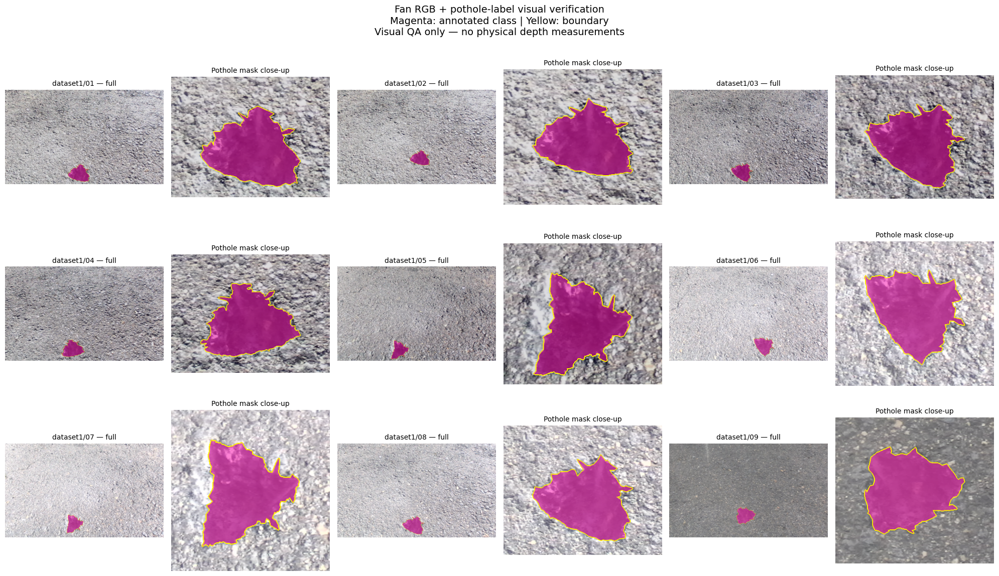

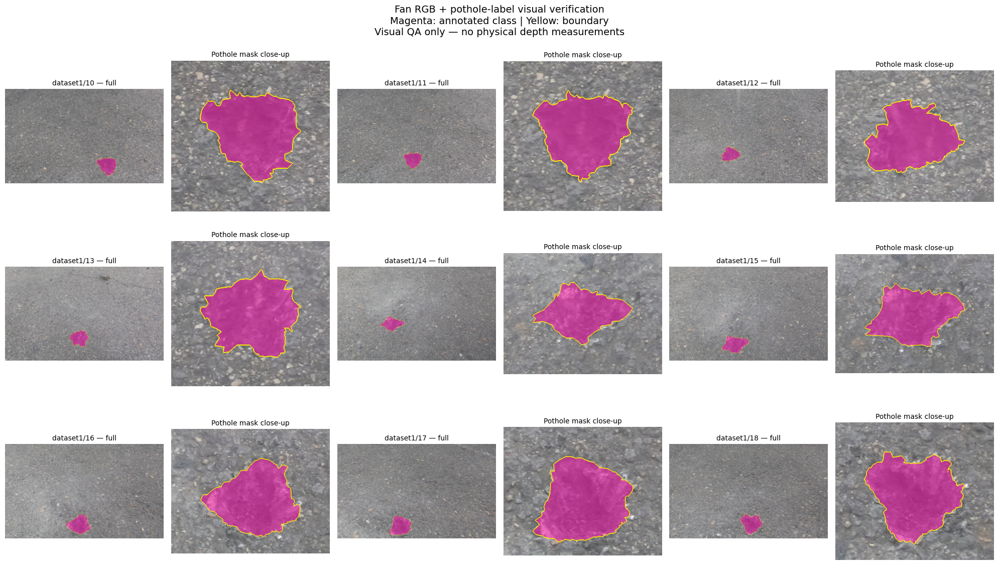

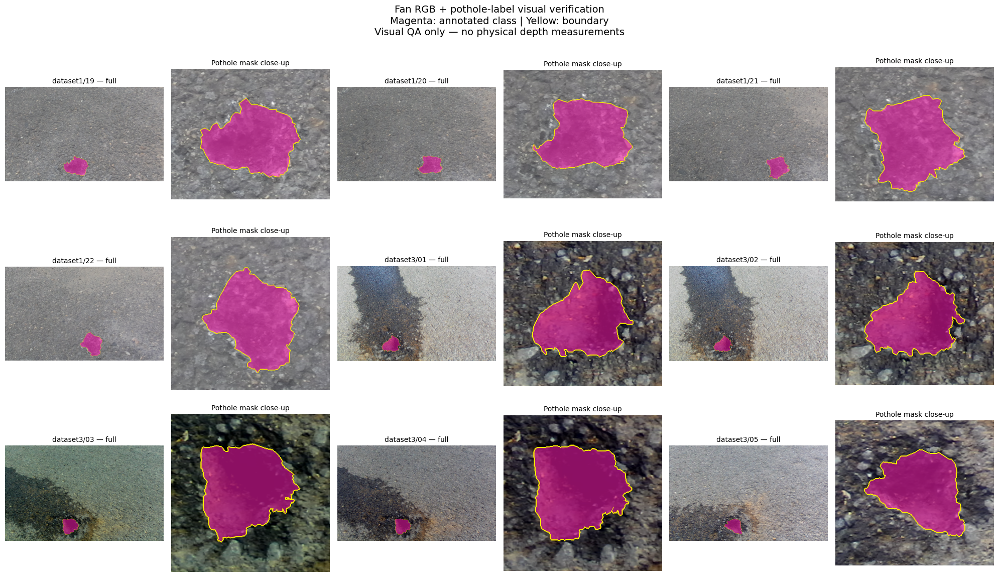


CLOSEST PERCEPTUAL IMAGE PAIRS
----------------------------------------------------------
dataset3/01 <-> dataset3/02 | distance: 0
dataset3/03 <-> dataset3/04 | distance: 0
dataset1/01 <-> dataset1/08 | distance: 6
dataset1/03 <-> dataset1/08 | distance: 6
dataset1/01 <-> dataset1/03 | distance: 8
dataset1/04 <-> dataset1/07 | distance: 8
dataset1/03 <-> dataset1/04 | distance: 10
dataset1/03 <-> dataset1/07 | distance: 10
dataset1/06 <-> dataset1/20 | distance: 12
dataset1/07 <-> dataset1/08 | distance: 12
dataset1/01 <-> dataset1/04 | distance: 14
dataset1/04 <-> dataset1/08 | distance: 14

Perceptual near-duplicate candidates: 8
IMPORTANT: pHash is only a screening heuristic.
High similarity does not prove scene identity;
low similarity does not prove independence.

C3-02 SECTION 2 — COMPLETE
Source frames checked: 27
Exact-color masks verified: 27
Masks touching image border: 0
Masks with multiple components: 0
Visual scene grouping: PENDING
Training/validation split: NOT FROZEN


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02
# SECTION 2: MASK VALIDATION & SCENE-LEAKAGE SCREENING
# Version 1.0
# 27 APPROVED FAN FRAMES ONLY
# NO TRAINING | NO METRIC LABELS | NO SPLIT ASSIGNMENT
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
from scipy import ndimage
from scipy.fft import dctn
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json
import csv
import re

DRIVE = Path("/content/drive/MyDrive")

PROJECT = (
    DRIVE / "crdl_experiments"
    / "component3_fresh_v1"
)

DATA = DRIVE / "manushi_research_data"

PREVIOUS = (
    PROJECT / "03_splits_manifests"
    / "C3-02_section01_20261020T062044_192309Z"
)

OUTPUT_ROOT = PROJECT / "03_splits_manifests"

# ------------------------------------------------------------
# 1. VERIFY THE PREVIOUS MANIFEST
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()

checksums = {}

for line in (
    PREVIOUS / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, name = line.split(None, 1)
        checksums[name.strip()] = digest

manifest_path = PREVIOUS / "fan_source_manifest.csv"
report_path = PREVIOUS / "mask_semantics_audit.json"

for path in [manifest_path, report_path]:

    assert path.is_file()
    assert sha256(path) == checksums[path.name]

with manifest_path.open(
    newline="", encoding="utf-8"
) as f:
    manifest = list(csv.DictReader(f))

previous_report = json.loads(
    report_path.read_text(encoding="utf-8")
)

assert previous_report["milestone"] == "C3-02"
assert len(manifest) == 27
assert previous_report["final_training_splits_frozen"] is False

print("C3-02 Section 1 integrity: PASS")

# ------------------------------------------------------------
# 2. EXPLICITLY PROTECT DATASET2 AND TEST DATA
# ------------------------------------------------------------

allowed = {
    "dataset1": set(f"{i:02d}" for i in range(1, 23)),
    "dataset3": set(f"{i:02d}" for i in range(1, 6)),
}

def safe_source_path(relative, dataset, frame, kind):

    expected = (
        "fan_stereo_pothole/"
        "stereo_pothole_datasets-master/"
        f"{dataset}/{kind}/{frame}.png"
    )

    if relative != expected:
        raise ValueError(
            f"Unexpected source path: {relative}"
        )

    path = DATA / relative

    if not path.is_file() or path.is_symlink():
        raise FileNotFoundError(path)

    return path

for row in manifest:

    dataset = row["dataset"]
    frame = row["frame_id"]

    if dataset not in allowed:
        raise ValueError("Unapproved dataset")

    if frame not in allowed[dataset]:
        raise ValueError("Unapproved frame")

    if row["all_files_present"] != "True":
        raise RuntimeError("Incomplete source record")

    if row["rgb_mask_dimensions_match"] != "True":
        raise RuntimeError("Unaligned annotation dimensions")

# ------------------------------------------------------------
# 3. DEFINE EXACT MASK PALETTE
# ------------------------------------------------------------

BACKGROUND = np.array(
    [0, 0, 0], dtype=np.uint8
)

POTHOLE = np.array(
    [153, 0, 0], dtype=np.uint8
)

def exact_pothole_mask(label):

    if label.ndim != 3 or label.shape[2] != 3:
        raise ValueError("Unexpected label dimensions")

    background = np.all(
        label == BACKGROUND, axis=2
    )

    pothole = np.all(
        label == POTHOLE, axis=2
    )

    unknown = ~(background | pothole)

    if unknown.any():
        raise ValueError(
            f"Unexpected label colors: "
            f"{int(unknown.sum())} pixels"
        )

    return pothole

# ------------------------------------------------------------
# 4. IMAGE SIMILARITY FOR LEAKAGE SCREENING
# ------------------------------------------------------------

def perceptual_hash(rgb):

    gray = Image.fromarray(
        rgb
    ).convert("L").resize(
        (64, 64),
        Image.Resampling.LANCZOS
    )

    x = np.asarray(
        gray, dtype=np.float32
    )

    frequencies = dctn(
        x, norm="ortho"
    )[:8, :8]

    coefficients = frequencies.flatten()[1:]

    return (
        coefficients >
        np.median(coefficients)
    )

# ------------------------------------------------------------
# 5. VISUAL ANNOTATION INSPECTION
# ------------------------------------------------------------

records = []
visuals = []
hashes = {}

for row in manifest:

    dataset = row["dataset"]
    frame = row["frame_id"]

    uid = f"{dataset}/{frame}"

    rgb_path = safe_source_path(
        row["rgb_path"],
        dataset, frame, "rgb"
    )

    label_path = safe_source_path(
        row["label_path"],
        dataset, frame, "label"
    )

    if sha256(label_path) != row["label_sha256"]:
        raise RuntimeError(
            f"Mask checksum changed: {uid}"
        )

    with Image.open(rgb_path) as im:
        rgb = np.asarray(
            im.convert("RGB")
        )

    with Image.open(label_path) as im:
        label = np.asarray(
            im.convert("RGB")
        )

    if rgb.shape != label.shape:
        raise RuntimeError(
            f"RGB/label mismatch: {uid}"
        )

    mask = exact_pothole_mask(label)

    if not mask.any():
        raise RuntimeError(
            f"Empty pothole mask: {uid}"
        )

    height, width = mask.shape

    ys, xs = np.where(mask)

    x1, x2 = int(xs.min()), int(xs.max()) + 1
    y1, y2 = int(ys.min()), int(ys.max()) + 1

    # 8-connected components for diagnostics.
    components, count = ndimage.label(
        mask,
        structure=np.ones(
            (3, 3), dtype=np.uint8
        )
    )

    sizes = np.bincount(
        components[mask],
        minlength=count + 1
    )[1:]

    largest_fraction = (
        float(sizes.max() / mask.sum())
        if len(sizes) else 0.0
    )

    touches_border = bool(
        mask[0, :].any()
        or mask[-1, :].any()
        or mask[:, 0].any()
        or mask[:, -1].any()
    )

    # RGB + colored annotation overlay.
    # This modifies a visualization, NOT a label.
    overlay = rgb.copy()

    overlay[mask] = (
        0.45 * rgb[mask].astype(np.float32)
        + 0.55 * np.array(
            [255, 30, 180]
        )
    ).astype(np.uint8)

    boundary = (
        ndimage.binary_dilation(
            mask, iterations=2
        ) & ~mask
    )

    overlay[boundary] = [255, 240, 0]

    # Close-up centered on the label bounding box.
    padding = max(
        55,
        int(0.30 * max(x2-x1, y2-y1))
    )

    xa = max(0, x1-padding)
    xb = min(width, x2+padding)
    ya = max(0, y1-padding)
    yb = min(height, y2+padding)

    closeup = overlay[ya:yb, xa:xb]

    hashes[uid] = perceptual_hash(rgb)

    records.append({
        "sample_id": uid,
        "dataset": dataset,
        "frame_id": frame,
        "mask_pixels": int(mask.sum()),
        "mask_fraction": float(mask.mean()),
        "connected_components": int(count),
        "largest_component_fraction": largest_fraction,
        "touches_image_border": touches_border,
        "bbox_xyxy": [x1, y1, x2, y2],
        "rgb_sha256": sha256(rgb_path),
        "label_sha256": row["label_sha256"],
        "mask_exact_palette_verified": True,
        "author_pothole_label_semantics": "SUPPORTED",
        "visual_semantics_reviewed_by_researcher": False,
        "physical_scene_id": None,
        "training_split": None,
        "metric_scale_verified": False,
    })

    visuals.append({
        "id": uid,
        "overlay": overlay,
        "closeup": closeup,
    })

print("\nMasks passing exact palette check:", len(records))
print(
    "Mask area range (%):",
    round(min(r["mask_fraction"] for r in records)*100, 3),
    "to",
    round(max(r["mask_fraction"] for r in records)*100, 3)
)

# ------------------------------------------------------------
# 6. MAKE HUMAN-REVIEW CONTACT SHEETS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = (
    OUTPUT_ROOT / f"C3-02_section02_{stamp}"
)

OUT.mkdir(exist_ok=False)

# 9 scenes per sheet, each with full view + close-up.
for sheet_start in range(0, len(visuals), 9):

    subset = visuals[
        sheet_start:sheet_start + 9
    ]

    fig, axes = plt.subplots(
        3, 6, figsize=(20, 12)
    )

    for ax in axes.flat:
        ax.axis("off")

    for index, item in enumerate(subset):

        r = index // 3
        c = (index % 3) * 2

        axes[r, c].imshow(item["overlay"])
        axes[r, c].set_title(
            f"{item['id']} — full",
            fontsize=10
        )

        axes[r, c+1].imshow(item["closeup"])
        axes[r, c+1].set_title(
            "Pothole mask close-up",
            fontsize=10
        )

    fig.suptitle(
        "Fan RGB + pothole-label visual verification\n"
        "Magenta: annotated class | Yellow: boundary\n"
        "Visual QA only — no physical depth measurements",
        fontsize=14
    )

    fig.tight_layout()

    sheet_number = sheet_start // 9 + 1

    fig.savefig(
        OUT / f"mask_contact_sheet_{sheet_number:02d}.png",
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 7. SCREEN FOR POSSIBLY REPEATED SCENES
# ------------------------------------------------------------

sample_ids = sorted(hashes)

similarities = []

for i in range(len(sample_ids)):
    for j in range(i+1, len(sample_ids)):

        a = sample_ids[i]
        b = sample_ids[j]

        distance = int(
            np.count_nonzero(
                hashes[a] != hashes[b]
            )
        )

        similarities.append({
            "sample_a": a,
            "sample_b": b,
            "phash_hamming_distance": distance,
            "candidate_near_duplicate": distance <= 10,
        })

similarities.sort(
    key=lambda x: x["phash_hamming_distance"]
)

print("\nCLOSEST PERCEPTUAL IMAGE PAIRS")
print("-" * 58)

for item in similarities[:12]:
    print(
        item["sample_a"],
        "<->",
        item["sample_b"],
        "| distance:",
        item["phash_hamming_distance"]
    )

print(
    "\nPerceptual near-duplicate candidates:",
    sum(
        x["candidate_near_duplicate"]
        for x in similarities
    )
)

print(
    "IMPORTANT: pHash is only a screening heuristic."
)
print(
    "High similarity does not prove scene identity;"
)
print(
    "low similarity does not prove independence."
)

# ------------------------------------------------------------
# 8. WRITE VERSIONED RESEARCH EVIDENCE
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": 2,
    "version": "1.0",
    "source_section01": PREVIOUS.name,
    "source_manifest_sha256": sha256(manifest_path),
    "sample_count": len(records),
    "dataset_counts": dict(
        Counter(r["dataset"] for r in records)
    ),
    "mask_background_rgb": BACKGROUND.tolist(),
    "pothole_candidate_rgb": POTHOLE.tolist(),
    "mask_records": records,
    "scene_similarity_pairs": similarities,
    "source_label_documentation": (
        "https://github.com/ruirangerfan/"
        "stereo_pothole_datasets"
    ),
    "visual_mask_qa_pending_researcher_review": True,
    "physical_scene_grouping_verified": False,
    "split_frozen": False,
    "dataset3_quarantined": True,
    "protected_dataset2_accessed": False,
    "historical_benchmark_accessed": False,
    "physical_scale_verified": False,
    "metric_training_authorized": False,
    "training_targets_exported": False,
}

json_path = OUT / "fan_mask_scene_audit.json"

json_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

summary_path = OUT / "mask_quality_summary.csv"

pd.DataFrame(records).to_csv(
    summary_path, index=False
)

similarity_path = OUT / "scene_similarity_screen.csv"

pd.DataFrame(similarities).to_csv(
    similarity_path, index=False
)

# ------------------------------------------------------------
# 9. EXPORT ARTIFACT CHECKSUMS
# ------------------------------------------------------------

checksum_lines = []

for file in sorted(OUT.iterdir()):

    if file.is_file():
        checksum_lines.append(
            f"{sha256(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 2 — COMPLETE")
print("=" * 65)

print("Source frames checked:", len(records))

print(
    "Exact-color masks verified:",
    sum(
        r["mask_exact_palette_verified"]
        for r in records
    )
)

print(
    "Masks touching image border:",
    sum(
        r["touches_image_border"]
        for r in records
    )
)

print(
    "Masks with multiple components:",
    sum(
        r["connected_components"] > 1
        for r in records
    )
)

print("Visual scene grouping: PENDING")
print("Training/validation split: NOT FROZEN")
print("Dataset3: QUARANTINED")
print("Metric training authorized: NO")
print("Saved:", OUT)

print("=" * 65)


Section 2 evidence integrity: PASS

CONSERVATIVE GROUPING
Dataset1: 22 linked development frames
Dataset3: 5 quarantined frames
Independent pothole count: UNKNOWN
Train/validation/test split: NOT ASSIGNED

FRAME dataset1/01
Mask pixels: 27906
Usable geometry: 60.83 %
Missing geometry: 39.17 %

REFERENCE-SURFACE DIAGNOSTICS
Road-support samples: 16000
Final robust inliers: 15748
Healthy-road absolute P95: 1.105 raw units
Signed inward median: 17.37 raw units
Positive inward fraction: 96.19 %

Prototype NPZ load test: PASS


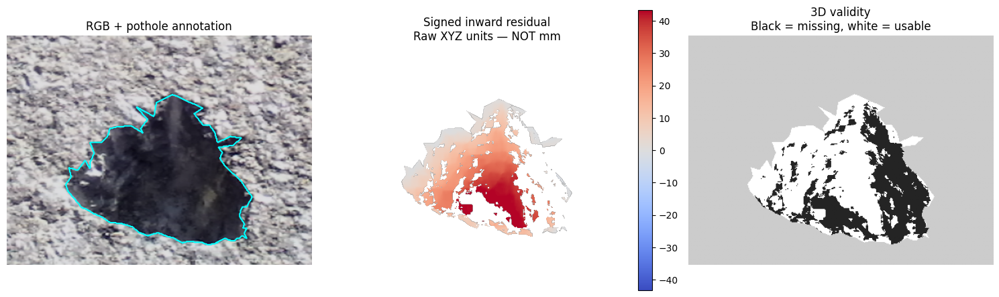


C3-02 SECTION 3 — NONMETRIC GEOMETRY PROTOTYPE
Source: Fan dataset1/01
Source-group safeguard: ACTIVE
Training/validation split: NONE
Valid pothole XYZ: 60.83 %
Healthy-road P95: 1.105 raw units
Inward median: 17.37 raw units
Prototype NPZ smoke test: PASS
Metric training labels approved: NO
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section03_PROTOTYPE_20261020T063328_275847Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 3
# CONSERVATIVE SCENE GROUPING + GEOMETRY PROTOTYPE
# Version 1.0
#
# One previously inspected development frame only.
# NO metric labels | NO model training | NO data splitting
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
from scipy.io import loadmat
from scipy.ndimage import distance_transform_edt
from matplotlib.colors import ListedColormap
import numpy as np
import matplotlib.pyplot as plt
import csv
import json
import hashlib

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

FAN = (
    DATA / "fan_stereo_pothole"
    / "stereo_pothole_datasets-master"
)

PREVIOUS = (
    PROJECT / "03_splits_manifests"
    / "C3-02_section02_20261020T062450_562688Z"
)

OUTPUT_ROOT = PROJECT / "04_geometry_targets"

assert PREVIOUS.is_dir()
assert OUTPUT_ROOT.is_dir()

# ------------------------------------------------------------
# 1. VERIFY SECTION 2 RESEARCH EVIDENCE
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()

checksums = {}

for line in (
    PREVIOUS / "checksums.sha256"
).read_text().splitlines():

    if not line.strip():
        continue

    digest, name = line.split(None, 1)
    name = name.strip()

    if Path(name).name != name:
        raise ValueError("Unsafe checksum entry")

    checksums[name] = digest

previous_path = (
    PREVIOUS / "fan_mask_scene_audit.json"
)

assert previous_path.is_file()

assert (
    sha256(previous_path)
    == checksums[previous_path.name]
)

previous = json.loads(
    previous_path.read_text(encoding="utf-8")
)

assert previous["milestone"] == "C3-02"
assert previous["section"] == 2
assert previous["sample_count"] == 27
assert previous["split_frozen"] is False

records = previous["mask_records"]

assert len(records) == 27
assert len({
    r["sample_id"] for r in records
}) == 27

assert sum(
    r["dataset"] == "dataset1"
    for r in records
) == 22

assert sum(
    r["dataset"] == "dataset3"
    for r in records
) == 5

assert all(
    r["mask_exact_palette_verified"]
    for r in records
)

print("Section 2 evidence integrity: PASS")

# ------------------------------------------------------------
# 2. CONSERVATIVE CAPTURE-SOURCE GROUP POLICY
# ------------------------------------------------------------

group_rows = []

for r in sorted(
    records,
    key=lambda x: (x["dataset"], x["frame_id"])
):

    dataset = r["dataset"]

    if dataset not in {"dataset1", "dataset3"}:
        raise ValueError("Unapproved source")

    if dataset == "dataset1":
        capture_group = "FAN_D1_ALL_FRAMES"
        development_role = "PROTOTYPE_SOURCE_ONLY"

    else:
        capture_group = "FAN_D3_ALL_FRAMES"
        development_role = "QUARANTINED"

    group_rows.append({
        "sample_id": r["sample_id"],
        "capture_source_group": capture_group,
        "physical_pothole_identity": "UNVERIFIED",
        "development_role": development_role,
        "train_split": "UNASSIGNED",
        "validation_split": "UNASSIGNED",
        "test_split": "UNASSIGNED",
        "metric_scale_verified": False,
    })

print("\nCONSERVATIVE GROUPING")
print("Dataset1: 22 linked development frames")
print("Dataset3: 5 quarantined frames")
print("Independent pothole count: UNKNOWN")
print("Train/validation/test split: NOT ASSIGNED")

# ------------------------------------------------------------
# 3. LOAD ONE APPROVED DEVELOPMENT FRAME
# ------------------------------------------------------------

record = next(
    r for r in records
    if r["sample_id"] == "dataset1/01"
)

rgb_path = FAN / "dataset1/rgb/01.png"
label_path = FAN / "dataset1/label/01.png"
cloud_path = FAN / "dataset1/ptcloud/01.mat"

for path in [rgb_path, label_path, cloud_path]:

    assert path.is_file()
    assert not path.is_symlink()

assert (
    sha256(label_path)
    == record["label_sha256"]
)

with Image.open(rgb_path) as im:
    rgb = np.asarray(
        im.convert("RGB")
    )

with Image.open(label_path) as im:
    label = np.asarray(
        im.convert("RGB")
    )

pothole_color = np.array(
    [153, 0, 0],
    dtype=np.uint8
)

mask = np.all(
    label == pothole_color,
    axis=2
)

background = np.all(
    label == 0,
    axis=2
)

assert np.all(mask | background)
assert np.any(mask)

cloud = loadmat(
    cloud_path,
    variable_names=["xyzPoints"]
)

xyz = cloud["xyzPoints"]

assert xyz.shape == (*mask.shape, 3)
assert rgb.shape == xyz.shape

# ------------------------------------------------------------
# 4. IDENTIFY USABLE 3D MEASUREMENTS
# ------------------------------------------------------------

# No physical scale is assumed.
# Positive Z is required for this source's
# provisional camera-coordinate interpretation.

valid_xyz = (
    np.isfinite(xyz).all(axis=2)
    & (xyz[:, :, 2] > 0)
)

valid_target = mask & valid_xyz

coverage = (
    valid_target.sum() / mask.sum()
)

assert coverage > 0.05, (
    "Insufficient 3D coverage for prototype"
)

print("\nFRAME dataset1/01")
print("Mask pixels:", int(mask.sum()))
print(
    "Usable geometry:",
    round(100 * coverage, 2), "%"
)
print(
    "Missing geometry:",
    round(100 * (1 - coverage), 2), "%"
)

# ------------------------------------------------------------
# 5. SELECT SURROUNDING HEALTHY-ROAD POINTS
# ------------------------------------------------------------

# Distance from the annotated pothole boundary,
# measured in pixels, not physical units.

distance = distance_transform_edt(~mask)

road_ring = (
    (distance >= 8)
    & (distance <= 55)
    & valid_xyz
)

ring_positions = np.argwhere(road_ring)

assert len(ring_positions) >= 1500

rng = np.random.default_rng(20261020)

# Deterministic subsampling keeps fitting practical.
if len(ring_positions) > 16000:

    chosen = rng.choice(
        len(ring_positions),
        16000,
        replace=False
    )

    ring_positions = ring_positions[chosen]

X = xyz[
    ring_positions[:, 0],
    ring_positions[:, 1]
].astype(np.float64)

# ------------------------------------------------------------
# 6. ROBUST LOCAL REFERENCE-PLANE FITTING
# ------------------------------------------------------------

active = np.ones(
    len(X), dtype=bool
)

fit_history = []

for iteration in range(5):

    subset = X[active]

    if len(subset) < 1000:
        raise RuntimeError(
            "Insufficient robust plane support"
        )

    center = subset.mean(axis=0)

    _, _, vh = np.linalg.svd(
        subset - center,
        full_matrices=False
    )

    normal = vh[-1]

    residuals = (X - center) @ normal

    median = np.median(residuals)

    mad = np.median(
        np.abs(residuals - median)
    )

    threshold = max(
        3 * 1.4826 * mad,
        1e-6
    )

    next_active = (
        np.abs(residuals - median)
        <= threshold
    )

    fit_history.append({
        "iteration": iteration + 1,
        "inliers": int(next_active.sum()),
        "mad_raw": float(mad),
        "threshold_raw": float(threshold),
    })

    if next_active.sum() < 1000:
        break

    if np.array_equal(next_active, active):
        active = next_active
        break

    active = next_active

# Refit using the final inliers.
subset = X[active]

center = subset.mean(axis=0)

_, _, vh = np.linalg.svd(
    subset - center,
    full_matrices=False
)

normal = vh[-1]

# Choose the normal pointing toward the assumed
# camera origin. This remains a heuristic.
if np.dot(normal, -center) < 0:
    normal = -normal

ring_errors = np.abs(
    (X - center) @ normal
)

road_p95_raw = float(
    np.percentile(ring_errors, 95)
)

# ------------------------------------------------------------
# 7. CONSTRUCT SIGNED ROAD-RELATIVE RESIDUAL
# ------------------------------------------------------------

# CRITICAL:
# - raw XYZ coordinates, not millimetres
# - no clipping to positive values
# - no replacement of missing geometry with zero
# - not yet an approved ML training target

inward_raw = np.full(
    mask.shape,
    np.nan,
    dtype=np.float32
)

valid_points = xyz[
    valid_target
].astype(np.float64)

signed_residuals = -(
    (valid_points - center) @ normal
)

inward_raw[valid_target] = (
    signed_residuals.astype(np.float32)
)

assert np.array_equal(
    np.isfinite(inward_raw),
    valid_target
)

assert np.isnan(
    inward_raw[mask & ~valid_xyz]
).all()

values = inward_raw[valid_target]

median_inward_raw = float(
    np.median(values)
)

positive_fraction = float(
    np.mean(values > 0)
)

print("\nREFERENCE-SURFACE DIAGNOSTICS")
print("Road-support samples:", len(X))
print("Final robust inliers:", int(active.sum()))
print(
    "Healthy-road absolute P95:",
    round(road_p95_raw, 3),
    "raw units"
)
print(
    "Signed inward median:",
    round(median_inward_raw, 3),
    "raw units"
)
print(
    "Positive inward fraction:",
    round(100 * positive_fraction, 2), "%"
)

# ------------------------------------------------------------
# 8. CREATE VERSIONED OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = (
    OUTPUT_ROOT
    / f"C3-02_section03_PROTOTYPE_{stamp}"
)

OUT.mkdir(exist_ok=False)

# Record the grouping safeguard.
group_path = (
    OUT / "fan_conservative_group_registry.csv"
)

with group_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(group_rows[0].keys())
    )

    writer.writeheader()
    writer.writerows(group_rows)

# ------------------------------------------------------------
# 9. SAVE THE GEOMETRY PROTOTYPE
# ------------------------------------------------------------

npz_path = (
    OUT / "fan_dataset1_01_raw_surface_prototype.npz"
)

np.savez_compressed(
    npz_path,
    inward_signed_raw=inward_raw,
    damage_mask=mask.astype(np.uint8),
    valid_target_mask=valid_target.astype(np.uint8),
    valid_xyz_mask=valid_xyz.astype(np.uint8),
    normal_toward_camera_raw=normal,
    reference_point_raw=center,
)

# Confirm that the saved artifact loads correctly.
with np.load(
    npz_path,
    allow_pickle=False
) as saved:

    assert np.array_equal(
        saved["valid_target_mask"].astype(bool),
        np.isfinite(saved["inward_signed_raw"])
    )

    assert np.array_equal(
        saved["damage_mask"].astype(bool),
        mask
    )

print("\nPrototype NPZ load test: PASS")

# ------------------------------------------------------------
# 10. VISUALIZE ROAD-RELATIVE GEOMETRY
# ------------------------------------------------------------

ys, xs = np.where(mask)

pad = 75

ya = max(0, int(ys.min()) - pad)
yb = min(mask.shape[0], int(ys.max()) + pad + 1)

xa = max(0, int(xs.min()) - pad)
xb = min(mask.shape[1], int(xs.max()) + pad + 1)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.8)
)

axes[0].imshow(
    rgb[ya:yb, xa:xb]
)

axes[0].contour(
    mask[ya:yb, xa:xb],
    levels=[0.5],
    colors=["cyan"]
)

axes[0].set_title(
    "RGB + pothole annotation"
)

local_residual = np.ma.masked_invalid(
    inward_raw[ya:yb, xa:xb]
)

limit = max(
    float(np.percentile(np.abs(values), 95)),
    1e-6
)

im = axes[1].imshow(
    local_residual,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)

axes[1].set_title(
    "Signed inward residual\n"
    "Raw XYZ units — NOT mm"
)

fig.colorbar(
    im, ax=axes[1],
    fraction=0.046,
    pad=0.04
)

validity_view = np.zeros(
    mask.shape,
    dtype=np.uint8
)

validity_view[
    mask & ~valid_xyz
] = 1

validity_view[
    valid_target
] = 2

axes[2].imshow(
    validity_view[ya:yb, xa:xb],
    cmap=ListedColormap([
        "#cccccc",
        "#242424",
        "#ffffff"
    ]),
    vmin=0,
    vmax=2
)

axes[2].set_title(
    "3D validity\n"
    "Black = missing, white = usable"
)

for ax in axes:
    ax.axis("off")

fig.tight_layout()

fig.savefig(
    OUT / "fan_01_prototype_QA.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. SAVE RESEARCH PROVENANCE AND API-LIKE SCHEMA
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": 3,
    "version": "1.0",
    "type": (
        "NONMETRIC_DIAGNOSTIC_PROTOTYPE_"
        "NOT_TRAINING_LABEL"
    ),
    "source_section02": PREVIOUS.name,
    "source_section02_sha256": sha256(
        previous_path
    ),
    "sample_id": "dataset1/01",
    "source_rgb_sha256": sha256(rgb_path),
    "source_mask_sha256": sha256(label_path),
    "source_xyz_sha256": sha256(cloud_path),
    "conservative_source_groups": {
        "dataset1": "FAN_D1_ALL_FRAMES",
        "dataset3": "FAN_D3_ALL_FRAMES"
    },
    "independent_scene_count_verified": False,
    "train_val_test_split_assigned": False,
    "dataset3_payload_accessed": False,
    "protected_dataset2_accessed": False,
    "historical_399_benchmark_accessed": False,
    "valid_pothole_fraction": float(coverage),
    "valid_pothole_pixels": int(
        valid_target.sum()
    ),
    "missing_pothole_pixels": int(
        (mask & ~valid_xyz).sum()
    ),
    "reference_support_sampled": len(X),
    "reference_plane_inliers": int(
        active.sum()
    ),
    "reference_ring_abs_p95_raw": road_p95_raw,
    "inward_signed_median_raw": median_inward_raw,
    "positive_inward_fraction": positive_fraction,
    "fit_iterations": fit_history,
    "plane_normal_toward_assumed_camera": (
        normal.tolist()
    ),
    "plane_center_raw": center.tolist(),
    "units": "UNVERIFIED_XYZ_COORDINATE_UNITS",
    "camera_center_assumed_origin": True,
    "normal_orientation_is_heuristic": True,
    "physical_accuracy_verified": False,
    "trainable_targets_approved": False,
    "metric_training_authorized": False,
    "npz_schema": {
        "inward_signed_raw": (
            "float32[H,W]; NaN outside valid damage geometry"
        ),
        "damage_mask": (
            "uint8[H,W]; 1 = pothole annotation"
        ),
        "valid_target_mask": (
            "uint8[H,W]; 1 = usable residual"
        ),
        "valid_xyz_mask": (
            "uint8[H,W]; 1 = finite, positive-Z XYZ"
        ),
        "normal_toward_camera_raw": (
            "float64[3]; heuristic orientation"
        ),
        "reference_point_raw": (
            "float64[3]; local plane point"
        )
    },
    "method_note": (
        "One-frame diagnostic reference target. "
        "No certified physical scale, independent "
        "scene split, validation or ML training."
    )
}

report_path = OUT / "prototype_report.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 12. EXPORT CHECKSUMS
# ------------------------------------------------------------

checksum_lines = []

for path in sorted(OUT.iterdir()):

    if path.is_file():

        checksum_lines.append(
            f"{sha256(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 3 — NONMETRIC GEOMETRY PROTOTYPE")
print("=" * 65)

print("Source: Fan dataset1/01")
print("Source-group safeguard: ACTIVE")
print("Training/validation split: NONE")

print(
    "Valid pothole XYZ:",
    round(100 * coverage, 2), "%"
)

print(
    "Healthy-road P95:",
    round(road_p95_raw, 3),
    "raw units"
)

print(
    "Inward median:",
    round(median_inward_raw, 3),
    "raw units"
)

print("Prototype NPZ smoke test: PASS")
print("Metric training labels approved: NO")
print("Output:", OUT)

print("=" * 65)


C3-02 previous evidence: PASS
Approved source: Fan dataset1, 22 frames
Dataset3 and dataset2: NOT READ
dataset1/01 | DIAGNOSTIC_PASS | valid: 60.8 % | holdout ratio: 0.078 | flags: []
dataset1/02 | DIAGNOSTIC_PASS | valid: 67.4 % | holdout ratio: 0.07 | flags: []
dataset1/03 | DIAGNOSTIC_PASS | valid: 73.1 % | holdout ratio: 0.056 | flags: []
dataset1/04 | DIAGNOSTIC_PASS | valid: 63.6 % | holdout ratio: 0.095 | flags: []
dataset1/05 | DIAGNOSTIC_FAIL | valid: 58.2 % | holdout ratio: 0.504 | flags: ['WEAK_SPATIAL_GENERALIZATION']
dataset1/06 | DIAGNOSTIC_PASS | valid: 72.7 % | holdout ratio: 0.082 | flags: []
dataset1/07 | DIAGNOSTIC_FAIL | valid: 66.8 % | holdout ratio: 0.377 | flags: ['WEAK_SPATIAL_GENERALIZATION']
dataset1/08 | DIAGNOSTIC_PASS | valid: 68.6 % | holdout ratio: 0.056 | flags: []
dataset1/09 | DIAGNOSTIC_PASS | valid: 68.9 % | holdout ratio: 0.084 | flags: []
dataset1/10 | DIAGNOSTIC_PASS | valid: 73.3 % | holdout ratio: 0.075 | flags: []
dataset1/11 | DIAGNOSTIC_PASS 

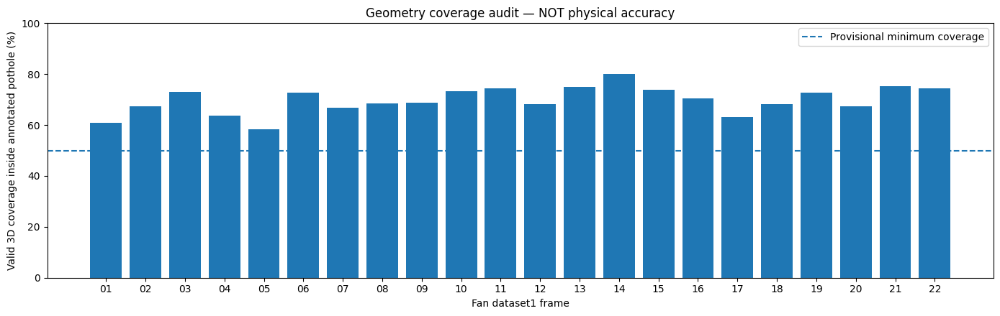


C3-02 SECTION 4 — BATCH GEOMETRY QA
Frames attempted: 22
Diagnostic status: {'DIAGNOSTIC_PASS': 16, 'DIAGNOSTIC_FAIL': 6}
Frame01 prototype difference: 0.005906494374887217
Independent validation groups verified: NONE
Metric depth certified: NO
Training labels approved: NO
Neural network trained: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section04_BATCH_20261020T064109_316286Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 4
# GROUP-SAFE BATCH GEOMETRY DIAGNOSTICS
# Version 1.0
#
# Dataset1 only | Dataset3 quarantined
# NO metric labels | NO ML training | NO train/val split
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from scipy.io import loadmat
from scipy.ndimage import distance_transform_edt
from PIL import Image
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
import gc

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

FAN = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "fan_stereo_pothole/stereo_pothole_datasets-master"
)

PREVIOUS = PROJECT / (
    "03_splits_manifests/"
    "C3-02_section02_20261020T062450_562688Z"
)

PROTOTYPE = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section03_PROTOTYPE_20261020T063328_275847Z"
)

OUTPUT_ROOT = PROJECT / "04_geometry_targets"

CONFIG = {
    "seed": 20261020,
    "ring_min_px": 8,
    "ring_max_px": 55,
    "max_support_points": 16000,
    "robust_iterations": 5,
    "min_coverage": 0.50,
    "min_road_inlier_fraction": 0.70,
    "min_positive_fraction": 0.75,
    "max_road_p95_to_median_abs_ratio": 0.25,
    "max_sector_p95_to_median_abs_ratio": 0.30,
    "min_holdout_pixels_per_sector": 250,
}

# These are preliminary internal QA thresholds.
# They are NOT calibrated physical-accuracy thresholds.

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS RESEARCH EVIDENCE
# ------------------------------------------------------------

def digest(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


def checked_report(folder, filename):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        sha, name = line.split(None, 1)
        name = name.strip()

        if Path(name).name != name:
            raise RuntimeError("Unsafe checksum record")

        expected[name] = sha

    path = folder / filename

    if digest(path) != expected[filename]:
        raise RuntimeError(
            "Evidence checksum mismatch: " + filename
        )

    return json.loads(
        path.read_text(encoding="utf-8")
    )


source = checked_report(
    PREVIOUS, "fan_mask_scene_audit.json"
)

proto = checked_report(
    PROTOTYPE, "prototype_report.json"
)

assert source["section"] == 2
assert len(source["mask_records"]) == 27
assert source["split_frozen"] is False
assert source["dataset3_quarantined"] is True
assert proto["trainable_targets_approved"] is False

rows = sorted(
    [
        r for r in source["mask_records"]
        if r["dataset"] == "dataset1"
    ],
    key=lambda r: r["frame_id"]
)

assert len(rows) == 22

assert [
    r["frame_id"] for r in rows
] == [
    f"{i:02d}" for i in range(1, 23)
]

assert all(
    r["mask_exact_palette_verified"]
    for r in rows
)

print("C3-02 previous evidence: PASS")
print("Approved source: Fan dataset1, 22 frames")
print("Dataset3 and dataset2: NOT READ")

# ------------------------------------------------------------
# 2. CREATE VERSIONED OUTPUT FOLDER
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTPUT_ROOT / (
    f"C3-02_section04_BATCH_{stamp}"
)

OUT.mkdir(exist_ok=False)

QA_DIR = OUT / "diagnostic_pass_npz"
QA_DIR.mkdir()

# ------------------------------------------------------------
# 3. ROBUST LOCAL 3D PLANE FITTING
# ------------------------------------------------------------

def fit_plane(points, iterations=5):

    used = np.ones(
        len(points), dtype=bool
    )

    for iteration in range(iterations):

        if used.sum() < 1000:
            raise ValueError(
                "Insufficient road-plane support"
            )

        subset = points[used]

        center = subset.mean(axis=0)

        _, _, vh = np.linalg.svd(
            subset - center,
            full_matrices=False
        )

        normal = vh[-1]

        residual = (
            points - center
        ) @ normal

        med = np.median(residual)

        mad = np.median(
            np.abs(residual - med)
        )

        threshold = max(
            3 * 1.4826 * mad,
            1e-6
        )

        new = (
            np.abs(residual - med)
            <= threshold
        )

        if new.sum() < 1000:
            raise ValueError(
                "Too few retained road points"
            )

        if np.array_equal(new, used):
            used = new
            break

        used = new

    subset = points[used]

    center = subset.mean(axis=0)

    _, _, vh = np.linalg.svd(
        subset - center,
        full_matrices=False
    )

    normal = vh[-1]

    # Provisional camera-facing convention.
    if np.dot(normal, -center) < 0:
        normal = -normal

    return center, normal, used

# ------------------------------------------------------------
# 4. PROCESS ONE APPROVED DEVELOPMENT FRAME
# ------------------------------------------------------------

def audit_one(row):

    frame = row["frame_id"]

    base = FAN / "dataset1"

    paths = {
        "rgb": base / "rgb" / f"{frame}.png",
        "label": base / "label" / f"{frame}.png",
        "ptcloud": base / "ptcloud" / f"{frame}.mat",
    }

    for path in paths.values():
        if not path.is_file() or path.is_symlink():
            raise FileNotFoundError(str(path))

    if digest(paths["label"]) != row["label_sha256"]:
        raise RuntimeError("Source mask checksum mismatch")

    with Image.open(paths["label"]) as im:
        label = np.asarray(im.convert("RGB"))

    background = np.all(
        label == [0, 0, 0], axis=2
    )

    mask = np.all(
        label == [153, 0, 0], axis=2
    )

    if not np.all(background | mask):
        raise ValueError("Unexpected annotation colors")

    if not mask.any():
        raise ValueError("Empty pothole annotation")

    xyz_data = loadmat(
        paths["ptcloud"],
        variable_names=["xyzPoints"]
    )

    if "xyzPoints" not in xyz_data:
        raise ValueError("Missing XYZ variable")

    xyz = xyz_data["xyzPoints"]

    if xyz.shape != (*mask.shape, 3):
        raise ValueError("XYZ/annotation mismatch")

    valid_xyz = (
        np.isfinite(xyz).all(axis=2)
        & (xyz[:, :, 2] > 0)
    )

    valid_target = mask & valid_xyz

    coverage = float(
        valid_target.sum() / mask.sum()
    )

    # --------------------------------------------------------
    # 5. SURROUNDING INTACT-ROAD SUPPORT
    # --------------------------------------------------------

    distance = distance_transform_edt(~mask)

    ring = (
        (distance >= CONFIG["ring_min_px"])
        & (distance <= CONFIG["ring_max_px"])
        & valid_xyz
    )

    ring_y, ring_x = np.nonzero(ring)

    if len(ring_y) < 1500:
        raise ValueError(
            "Insufficient surrounding valid geometry"
        )

    rng = np.random.default_rng(
        CONFIG["seed"] + int(frame)
    )

    chosen = rng.choice(
        len(ring_y),
        size=min(
            len(ring_y),
            CONFIG["max_support_points"]
        ),
        replace=False
    )

    support = xyz[
        ring_y[chosen],
        ring_x[chosen]
    ].astype(np.float64)

    center, normal, inliers = fit_plane(
        support,
        CONFIG["robust_iterations"]
    )

    road_p95 = float(
        np.percentile(
            np.abs(
                (support - center) @ normal
            ),
            95
        )
    )

    # --------------------------------------------------------
    # 6. CONSTRUCT NONMETRIC SIGNED RESIDUALS
    # --------------------------------------------------------

    points = xyz[
        valid_target
    ].astype(np.float64)

    if len(points) == 0:
        raise ValueError("No usable pothole XYZ")

    signed = -(
        (points - center) @ normal
    )

    median = float(np.median(signed))

    median_abs = float(
        np.median(np.abs(signed))
    )

    positive_fraction = float(
        np.mean(signed > 0)
    )

    # --------------------------------------------------------
    # 7. FOUR-SECTOR SPATIAL HOLDOUT DIAGNOSTIC
    # --------------------------------------------------------

    cy, cx = np.mean(
        np.nonzero(mask),
        axis=1
    )

    angles = np.mod(
        np.arctan2(
            ring_y - cy,
            ring_x - cx
        ) + 2 * np.pi,
        2 * np.pi
    )

    sectors = np.floor(
        angles / (np.pi / 2)
    ).astype(np.int8).clip(0, 3)

    holdouts = []

    for sector in range(4):

        test_idx = np.where(
            sectors == sector
        )[0]

        train_idx = np.where(
            sectors != sector
        )[0]

        if (
            len(test_idx)
            < CONFIG["min_holdout_pixels_per_sector"]
            or len(train_idx) < 1500
        ):
            holdouts.append({
                "sector": sector,
                "status": "INSUFFICIENT_SUPPORT"
            })
            continue

        sampled = rng.choice(
            train_idx,
            size=min(12000, len(train_idx)),
            replace=False
        )

        training_points = xyz[
            ring_y[sampled],
            ring_x[sampled]
        ].astype(np.float64)

        cv_center, cv_normal, _ = fit_plane(
            training_points,
            CONFIG["robust_iterations"]
        )

        test_points = xyz[
            ring_y[test_idx],
            ring_x[test_idx]
        ].astype(np.float64)

        errors = np.abs(
            (test_points - cv_center) @ cv_normal
        )

        holdouts.append({
            "sector": sector,
            "status": "TESTED",
            "test_points": len(test_idx),
            "abs_p95_raw": float(
                np.percentile(errors, 95)
            )
        })

    tested = [
        h["abs_p95_raw"]
        for h in holdouts
        if h["status"] == "TESTED"
    ]

    holdout_max = (
        max(tested)
        if len(tested) == 4
        else None
    )

    # --------------------------------------------------------
    # 8. APPLY INTERNAL DIAGNOSTIC QUALITY GATES
    # --------------------------------------------------------

    # Ratios cancel uniform XYZ scale.
    # They do NOT establish physical accuracy.

    denominator = max(
        median_abs, 1e-9
    )

    flags = []

    if coverage < CONFIG["min_coverage"]:
        flags.append("LOW_VALID_GEOMETRY")

    if inliers.mean() < CONFIG[
        "min_road_inlier_fraction"
    ]:
        flags.append("WEAK_PLANE_INLIERS")

    if positive_fraction < CONFIG[
        "min_positive_fraction"
    ]:
        flags.append("AMBIGUOUS_INWARD_DIRECTION")

    if (
        road_p95 / denominator
        > CONFIG["max_road_p95_to_median_abs_ratio"]
    ):
        flags.append("HIGH_ROAD_NOISE")

    if holdout_max is None:
        flags.append("INCOMPLETE_SPATIAL_HOLDOUT")

    elif (
        holdout_max / denominator
        > CONFIG["max_sector_p95_to_median_abs_ratio"]
    ):
        flags.append("WEAK_SPATIAL_GENERALIZATION")

    status = (
        "DIAGNOSTIC_PASS"
        if not flags
        else "DIAGNOSTIC_FAIL"
    )

    result = {
        "sample_id": f"dataset1/{frame}",
        "physical_group": "FAN_D1_ALL_FRAMES",
        "status": status,
        "flags": flags,
        "mask_pixels": int(mask.sum()),
        "valid_target_pixels": int(valid_target.sum()),
        "coverage": coverage,
        "support_points": len(support),
        "support_inliers": int(inliers.sum()),
        "support_inlier_fraction": float(
            inliers.mean()
        ),
        "road_abs_p95_raw": road_p95,
        "median_signed_inward_raw": median,
        "median_abs_raw": median_abs,
        "positive_fraction": positive_fraction,
        "road_p95_over_median_abs": (
            road_p95 / denominator
        ),
        "heldout_sector_max_p95_raw": holdout_max,
        "heldout_ratio": (
            holdout_max / denominator
            if holdout_max is not None
            else None
        ),
        "sector_results": holdouts,
        "source_mask_sha256": row["label_sha256"],
        "source_xyz_sha256": digest(
            paths["ptcloud"]
        ),
        "units": "UNVERIFIED_XYZ",
        "approved_for_training": False,
        "approved_for_metric_training": False,
        "npz": None,
    }

    # --------------------------------------------------------
    # 9. EXPORT PASSED DIAGNOSTICS ONLY
    # --------------------------------------------------------

    if status == "DIAGNOSTIC_PASS":

        residual = np.full(
            mask.shape,
            np.nan,
            dtype=np.float32
        )

        residual[valid_target] = (
            signed.astype(np.float32)
        )

        destination = QA_DIR / (
            f"fan_dataset1_{frame}_signed_raw.npz"
        )

        np.savez_compressed(
            destination,
            inward_signed_raw=residual,
            damage_mask=mask.astype(np.uint8),
            valid_target_mask=(
                valid_target.astype(np.uint8)
            ),
            valid_xyz_mask=(
                valid_xyz.astype(np.uint8)
            ),
            normal_toward_camera_raw=normal,
            reference_point_raw=center,
        )

        with np.load(
            destination,
            allow_pickle=False
        ) as loaded:

            assert np.array_equal(
                np.isfinite(
                    loaded["inward_signed_raw"]
                ),
                loaded["valid_target_mask"].astype(bool)
            )

        result["npz"] = str(
            destination.relative_to(OUT)
        )

    del xyz, xyz_data

    return result

# ------------------------------------------------------------
# 10. RUN APPROVED DATASET1 BATCH
# ------------------------------------------------------------

results = []

for row in rows:

    uid = "dataset1/" + row["frame_id"]

    try:
        result = audit_one(row)

    except Exception as exc:
        result = {
            "sample_id": uid,
            "physical_group": "FAN_D1_ALL_FRAMES",
            "status": "ERROR",
            "flags": ["PROCESSING_ERROR"],
            "error": (
                f"{type(exc).__name__}: {exc}"
            ),
            "approved_for_training": False,
            "approved_for_metric_training": False,
            "npz": None,
        }

    results.append(result)

    coverage = result.get("coverage", 0)

    ratio = result.get("heldout_ratio")

    print(
        uid,
        "|", result["status"],
        "| valid:", round(coverage * 100, 1), "%",
        "| holdout ratio:",
        None if ratio is None else round(ratio, 3),
        "| flags:", result["flags"]
    )

    gc.collect()

# ------------------------------------------------------------
# 11. COMPARE FRAME01 WITH SECTION 3 PROTOTYPE
# ------------------------------------------------------------

prior_median = float(
    proto["inward_signed_median_raw"]
)

new_01 = next(
    r for r in results
    if r["sample_id"] == "dataset1/01"
)

difference = (
    abs(
        new_01["median_signed_inward_raw"]
        - prior_median
    )
    if "median_signed_inward_raw" in new_01
    else None
)

print("\nFrame01 median difference:", difference)
print("Units: raw XYZ, not mm")

# ------------------------------------------------------------
# 12. SAVE BATCH REPORTS
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": 4,
    "version": "1.0",
    "generated_utc": stamp,
    "source_section02_sha256": digest(
        PREVIOUS / "fan_mask_scene_audit.json"
    ),
    "source_prototype_sha256": digest(
        PROTOTYPE / "prototype_report.json"
    ),
    "config": CONFIG,
    "results": results,
    "frame01_prototype_median_difference_raw": difference,
    "single_source_group_only": True,
    "physical_scene_independence_verified": False,
    "dataset3_read": False,
    "dataset2_read": False,
    "historical_399_test_read": False,
    "random_split_created": False,
    "metric_units_verified": False,
    "physical_accuracy_verified": False,
    "diagnostic_pass_is_not_training_approval": True,
    "training_labels_approved": False,
    "model_training_authorized": False,
}

report_path = (
    OUT / "fan_batch_diagnostic_report.json"
)

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

summary = []

for result in results:

    summary.append({
        key: (
            json.dumps(value)
            if isinstance(value, (dict, list))
            else value
        )
        for key, value in result.items()
        if key != "sector_results"
    })

pd.DataFrame(summary).to_csv(
    OUT / "fan_batch_quality_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 13. VISUALIZE VALID GEOMETRY COVERAGE
# ------------------------------------------------------------

frame_names = [
    r["sample_id"].split("/")[-1]
    for r in results
]

coverage_values = [
    100 * r.get("coverage", 0)
    for r in results
]

fig, ax = plt.subplots(
    figsize=(14, 4.5)
)

ax.bar(frame_names, coverage_values)

ax.axhline(
    100 * CONFIG["min_coverage"],
    linestyle="--",
    label="Provisional minimum coverage"
)

ax.set_ylim(0, 100)

ax.set_ylabel(
    "Valid 3D coverage inside annotated pothole (%)"
)

ax.set_xlabel("Fan dataset1 frame")

ax.set_title(
    "Geometry coverage audit — NOT physical accuracy"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "fan_dataset1_geometry_coverage.png",
    dpi=140
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. SAVE PROVENANCE NOTE AND ARTIFACT CHECKSUMS
# ------------------------------------------------------------

(OUT / "README_PROVENANCE.txt").write_text(
    "NON-METRIC DIAGNOSTICS ONLY.\n"
    "No ML training or metric severity claims.\n"
    "All dataset1 frames form group FAN_D1_ALL_FRAMES.\n"
    "Dataset3 remains quarantined.\n"
    "Signed residuals use NaN for unavailable targets.\n"
    "DIAGNOSTIC_PASS does not authorize training.\n",
    encoding="utf-8"
)

checksum_lines = []

for path in sorted(OUT.rglob("*")):

    if path.is_file() and path.name != "checksums.sha256":

        checksum_lines.append(
            f"{digest(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

counts = Counter(
    r["status"] for r in results
)

print("\n" + "=" * 65)
print("C3-02 SECTION 4 — BATCH GEOMETRY QA")
print("=" * 65)

print("Frames attempted:", len(results))
print("Diagnostic status:", dict(counts))
print("Frame01 prototype difference:", difference)
print("Independent validation groups verified: NONE")
print("Metric depth certified: NO")
print("Training labels approved: NO")
print("Neural network trained: NO")
print("Saved:", OUT)

print("=" * 65)


Section 4 artifact integrity: PASS
Artifacts verified: 20

Original diagnostic decisions: {'DIAGNOSTIC_PASS': 16, 'DIAGNOSTIC_FAIL': 6}

NPZ integrity verification: PASS
NPZ files verified: 16

DIAGNOSTIC QUALITY DISTRIBUTION
BORDERLINE_DIAGNOSTIC_PASS : 2
DIAGNOSTIC_PASS : 14
REJECTED_BY_ORIGINAL_DIAGNOSTIC_GATE : 6

Original acceptance threshold: 0.3
Borderline reporting margin: 0.02
NOTE: No acceptance thresholds were changed.


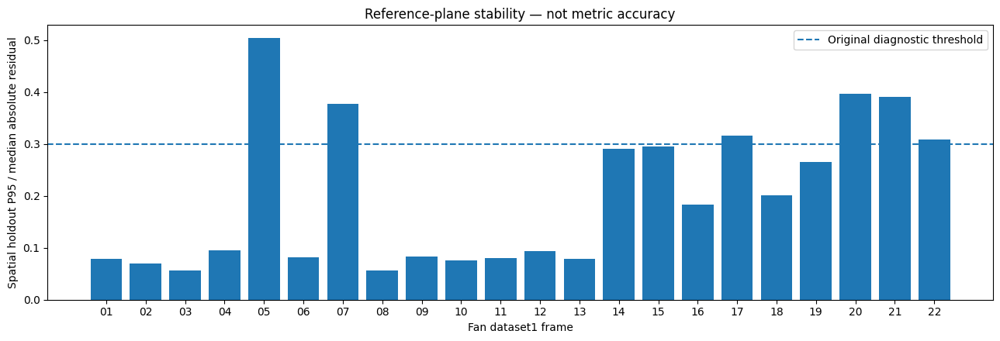


C3-02 SECTION 5 — DIAGNOSTIC TARGET HANDOFF
Original source evidence: VERIFIED
All saved target NPZs: VERIFIED
Target files: 16
Quality distribution: {'DIAGNOSTIC_PASS': 14, 'REJECTED_BY_ORIGINAL_DIAGNOSTIC_GATE': 6, 'BORDERLINE_DIAGNOSTIC_PASS': 2}
Training/validation groups: NOT ESTABLISHED
Engineering model smoke test: POSSIBLE
Metric CRDL training: NOT AUTHORIZED
Independent accuracy evaluation: NOT AUTHORIZED
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section05_HANDOFF_20261020T065059_185606Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 5
# DIAGNOSTIC TARGET INTEGRITY & ML ENGINEERING HANDOFF
# Version: 1.0
#
# READ-ONLY EXISTING NPZ TARGETS
# NO SOURCE IMAGE ACCESS
# NO TRAIN/VALIDATION SPLIT
# NO PHYSICAL DEPTH CLAIMS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

SOURCE = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section04_BATCH_20261020T064109_316286Z"
)

OUTPUT_ROOT = PROJECT / "04_geometry_targets"

assert SOURCE.is_dir()
assert OUTPUT_ROOT.is_dir()

# ------------------------------------------------------------
# 1. VERIFY COMPLETE SECTION 4 ARTIFACT INTEGRITY
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()

checksum_path = SOURCE / "checksums.sha256"

assert checksum_path.is_file()

expected = {}

for line in checksum_path.read_text(
    encoding="utf-8"
).splitlines():

    if not line.strip():
        continue

    digest, relative = line.split(None, 1)
    relative = relative.strip()

    candidate = Path(relative)

    if (
        candidate.is_absolute()
        or ".." in candidate.parts
        or relative in expected
    ):
        raise RuntimeError(
            "Unsafe or duplicate checksum entry"
        )

    expected[relative] = digest

assert expected

for relative, recorded_sha in expected.items():

    file = SOURCE / relative

    assert file.is_file()
    assert not file.is_symlink()

    if sha256(file) != recorded_sha:
        raise RuntimeError(
            f"Checksum mismatch: {relative}"
        )

actual_files = {
    p.relative_to(SOURCE).as_posix()
    for p in SOURCE.rglob("*")
    if p.is_file()
    and p.name != "checksums.sha256"
}

assert actual_files == set(expected), (
    "Section 4 artifact inventory differs "
    "from its recorded checksum list"
)

print("Section 4 artifact integrity: PASS")
print("Artifacts verified:", len(expected))

# ------------------------------------------------------------
# 2. READ COMPLETED DIAGNOSTIC REPORT
# ------------------------------------------------------------

REPORT = SOURCE / "fan_batch_diagnostic_report.json"

report = json.loads(
    REPORT.read_text(encoding="utf-8")
)

assert report["milestone"] == "C3-02"
assert report["section"] == 4

assert report["single_source_group_only"] is True
assert report["random_split_created"] is False

assert report["metric_units_verified"] is False
assert report["training_labels_approved"] is False

assert report["dataset3_read"] is False
assert report["dataset2_read"] is False

results = sorted(
    report["results"],
    key=lambda r: r["sample_id"]
)

assert len(results) == 22

assert [
    r["sample_id"] for r in results
] == [
    f"dataset1/{i:02d}"
    for i in range(1, 23)
]

counts = Counter(
    r["status"] for r in results
)

print("\nOriginal diagnostic decisions:", dict(counts))

# ------------------------------------------------------------
# 3. VERIFY SAVED NPZ CONTENT AND MISSING-DATA MASKS
# ------------------------------------------------------------

PASS_STATUS = "DIAGNOSTIC_PASS"

# Used only to identify passes near the existing
# 0.30 threshold. This is not a new acceptance rule.
BORDERLINE_MARGIN = 0.02

original_threshold = float(
    report["config"][
        "max_sector_p95_to_median_abs_ratio"
    ]
)

records = []
verified_npz = set()

for result in results:

    sample = result["sample_id"]
    status = result["status"]

    frame = sample.split("/")[1]

    row = {
        "sample_id": sample,
        "capture_group": "FAN_D1_ALL_FRAMES",
        "diagnostic_status": status,
        "valid_coverage": result.get("coverage"),
        "holdout_ratio": result.get("heldout_ratio"),
        "quality_note": "",
        "npz_path": result.get("npz"),
        "mask_pixels": result.get("mask_pixels"),
        "valid_pixels": result.get("valid_target_pixels"),
        "npz_integrity": "NOT_APPLICABLE",
        "training_approved": False,
        "metric_training_approved": False,
        "validation_split": "NONE",
    }

    if status != PASS_STATUS:

        assert result.get("npz") is None

        row["quality_note"] = (
            "REJECTED_BY_ORIGINAL_DIAGNOSTIC_GATE"
        )

        records.append(row)
        continue

    relative = result.get("npz")

    assert relative is not None

    expected_relative = (
        "diagnostic_pass_npz/"
        f"fan_dataset1_{frame}_signed_raw.npz"
    )

    assert relative == expected_relative

    target_file = SOURCE / relative

    assert target_file.is_file()

    with np.load(
        target_file,
        allow_pickle=False
    ) as saved:

        required = {
            "inward_signed_raw",
            "damage_mask",
            "valid_target_mask",
            "valid_xyz_mask",
            "normal_toward_camera_raw",
            "reference_point_raw",
        }

        assert set(saved.files) == required

        depth = saved[
            "inward_signed_raw"
        ]

        damage_raw = saved[
            "damage_mask"
        ]

        valid_raw = saved[
            "valid_target_mask"
        ]

        xyz_raw = saved[
            "valid_xyz_mask"
        ]

        normal = saved[
            "normal_toward_camera_raw"
        ]

        center = saved[
            "reference_point_raw"
        ]

        assert depth.dtype == np.float32

        assert depth.ndim == 2

        assert (
            damage_raw.shape
            == valid_raw.shape
            == xyz_raw.shape
            == depth.shape
        )

        assert set(
            np.unique(damage_raw).tolist()
        ).issubset({0, 1})

        assert set(
            np.unique(valid_raw).tolist()
        ).issubset({0, 1})

        assert set(
            np.unique(xyz_raw).tolist()
        ).issubset({0, 1})

        damage = damage_raw.astype(bool)
        valid = valid_raw.astype(bool)
        xyz_valid = xyz_raw.astype(bool)

        # Core reference-target invariants.
        assert np.array_equal(
            np.isfinite(depth),
            valid
        )

        assert np.all(valid <= damage)
        assert np.all(valid <= xyz_valid)

        assert int(damage.sum()) == (
            result["mask_pixels"]
        )

        assert int(valid.sum()) == (
            result["valid_target_pixels"]
        )

        actual_coverage = float(
            valid.sum() / damage.sum()
        )

        assert np.isclose(
            actual_coverage,
            result["coverage"],
            atol=1e-9
        )

        assert normal.shape == (3,)
        assert center.shape == (3,)

        assert np.isfinite(normal).all()
        assert np.isfinite(center).all()

        assert np.isclose(
            np.linalg.norm(normal),
            1.0,
            atol=1e-5
        )

        measured_median = float(
            np.median(depth[valid])
        )

        assert np.isclose(
            measured_median,
            result["median_signed_inward_raw"],
            atol=0.02
        )

        # No missing pixel has become false zero.
        assert np.isnan(depth[~valid]).all()

        row["verified_median_raw"] = (
            measured_median
        )

    verified_npz.add(relative)

    ratio = float(
        result["heldout_ratio"]
    )

    margin = original_threshold - ratio

    if margin <= BORDERLINE_MARGIN:

        row["quality_note"] = (
            "BORDERLINE_DIAGNOSTIC_PASS"
        )

    else:

        row["quality_note"] = (
            "DIAGNOSTIC_PASS"
        )

    row["threshold_margin"] = float(margin)
    row["npz_integrity"] = "PASS"

    records.append(row)

# ------------------------------------------------------------
# 4. CONFIRM THERE ARE NO EXTRA NPZ TARGETS
# ------------------------------------------------------------

all_npz = {
    p.relative_to(SOURCE).as_posix()
    for p in (
        SOURCE / "diagnostic_pass_npz"
    ).glob("*.npz")
}

assert all_npz == verified_npz

print("\nNPZ integrity verification: PASS")
print("NPZ files verified:", len(verified_npz))

# ------------------------------------------------------------
# 5. SUMMARIZE THE ACCEPTANCE MARGINS
# ------------------------------------------------------------

quality = Counter(
    r["quality_note"]
    for r in records
)

print("\nDIAGNOSTIC QUALITY DISTRIBUTION")

for name, count in sorted(quality.items()):
    print(name, ":", count)

print(
    "\nOriginal acceptance threshold:",
    original_threshold
)

print(
    "Borderline reporting margin:",
    BORDERLINE_MARGIN
)

print(
    "NOTE: No acceptance thresholds were changed."
)

# ------------------------------------------------------------
# 6. CREATE VERSIONED MODEL-ENGINEERING HANDOFF
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTPUT_ROOT / (
    f"C3-02_section05_HANDOFF_{stamp}"
)

OUT.mkdir(exist_ok=False)

manifest_file = (
    OUT / "diagnostic_target_manifest.csv"
)

pd.DataFrame(records).to_csv(
    manifest_file,
    index=False
)

# ------------------------------------------------------------
# 7. EXPLICIT MACHINE-LEARNING TARGET CONTRACT
# ------------------------------------------------------------

target_contract = {
    "version": "0.1-diagnostic",
    "status": "ENGINEERING_SMOKE_TEST_ONLY",
    "prediction_problem": (
        "Predict road-relative signed displacement "
        "from RGB imagery and an externally "
        "provided pothole mask."
    ),
    "inputs_expected_later": {
        "rgb": "RGB image from detection pipeline",
        "damage_mask": (
            "binary mask supplied by segmentation "
            "pipeline"
        ),
        "detection_confidence": (
            "optional confidence from teammate pipeline"
        )
    },
    "reference_target": {
        "key": "inward_signed_raw",
        "dtype": "float32",
        "units": "UNVERIFIED_FAN_XYZ",
        "missing_value": "NaN",
        "validity_key": "valid_target_mask",
        "loss_rule": (
            "Compute regression loss only where "
            "valid_target_mask == 1."
        ),
        "positive_direction": (
            "Heuristic inward orientation; "
            "not independently certified"
        )
    },
    "source_policy": {
        "dataset1": "ONE_CONSERVATIVE_CAPTURE_GROUP",
        "dataset3": "QUARANTINED",
        "dataset2": "PROTECTED",
        "historical_benchmark": "PROTECTED"
    },
    "restrictions": {
        "random_image_train_validation_split": False,
        "metric_depth_claims": False,
        "severity_thresholds_in_mm": False,
        "backend_release": False,
        "scientific_model_accuracy_claims": False
    },
    "future_requirements": [
        "Independent physical-scene groups",
        "Verified camera scale and reference units",
        "External physical depth measurements",
        "Grouped validation and untouched testing",
        "Trained CRDL model and calibration evaluation"
    ]
}

contract_path = (
    OUT / "provisional_target_contract.json"
)

contract_path.write_text(
    json.dumps(target_contract, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. SAVE PROVENANCE REPORT
# ------------------------------------------------------------

handoff = {
    "milestone": "C3-02",
    "section": 5,
    "version": "1.0",
    "source_batch": SOURCE.name,
    "source_batch_report_sha256": sha256(
        REPORT
    ),
    "source_batch_checksums_sha256": sha256(
        checksum_path
    ),
    "total_records": len(records),
    "original_status_counts": dict(counts),
    "quality_note_counts": dict(quality),
    "verified_npz_count": len(verified_npz),
    "source_group_count_for_model_validation": 1,
    "independent_scene_count_verified": False,
    "training_split_assigned": False,
    "metric_depth_units_verified": False,
    "physical_ground_truth_available": False,
    "scientific_model_validation_authorized": False,
    "metric_model_training_authorized": False,
    "engineering_smoke_test_possible": True,
    "thresholds_retuned_after_results": False,
    "no_original_source_images_opened": True,
    "no_model_trained": True,
    "conclusion": (
        "The retained NPZ collection is internally "
        "consistent and suitable for limited "
        "data-loader and model-engineering tests. "
        "It is not a physically certified target "
        "dataset and does not support independent "
        "model generalization claims."
    )
}

report_path = OUT / "diagnostic_handoff_report.json"

report_path.write_text(
    json.dumps(handoff, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. VISUALIZE THE ORIGINAL QA RESULTS
# ------------------------------------------------------------

frames = [
    r["sample_id"].split("/")[1]
    for r in results
]

ratios = [
    r["heldout_ratio"]
    for r in results
]

fig, ax = plt.subplots(
    figsize=(13, 4.5)
)

ax.bar(frames, ratios)

ax.axhline(
    original_threshold,
    linestyle="--",
    label="Original diagnostic threshold"
)

ax.set_xlabel("Fan dataset1 frame")
ax.set_ylabel(
    "Spatial holdout P95 / median absolute residual"
)
ax.set_title(
    "Reference-plane stability — not metric accuracy"
)

ax.legend()
fig.tight_layout()

figure_path = (
    OUT / "spatial_holdout_diagnostic.png"
)

fig.savefig(
    figure_path,
    dpi=140
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. CHECKSUM ALL NEW HANDOFF ARTIFACTS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.iterdir()):

    if file.is_file():

        lines.append(
            f"{sha256(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 5 — DIAGNOSTIC TARGET HANDOFF")
print("=" * 65)

print("Original source evidence: VERIFIED")
print("All saved target NPZs: VERIFIED")
print("Target files:", len(verified_npz))
print("Quality distribution:", dict(quality))
print("Training/validation groups: NOT ESTABLISHED")
print("Engineering model smoke test: POSSIBLE")
print("Metric CRDL training: NOT AUTHORIZED")
print("Independent accuracy evaluation: NOT AUTHORIZED")
print("Output:", OUT)

print("=" * 65)


C3-02 — POTHOLE440 TRAINING DATA READINESS
rgb: 350 PNG files
mask: 350 PNG files
depth: 350 PNG files
Complete training triplets: 350
Unmatched names by modality: {'rgb': 0, 'mask': 0, 'depth': 0}

GROUPING AUDIT
Filename-derived candidate groups: 98
Non-base / variant filenames: 274
Unresolved group patterns: 0

Example candidate groups:
2022_05_22_pothole_10 : 7 files
2022_05_22_pothole_11 : 5 files
2022_05_22_pothole_12 : 5 files
2022_05_22_pothole_13 : 8 files
2022_05_22_pothole_14 : 7 files

Selected groups: 5

-------------------------------------------------------
Sample: 2022_05_22_pothole_10.png
Source group: 2022_05_22_pothole_10
RGB / mask / depth shapes:
(800, 1200, 3) (800, 1200, 3) (800, 1200)
Depth encoding: uint8 L
Raw depth range: 0.0 to 175.0
Unique depth codes: 176
Spatial shapes match: True


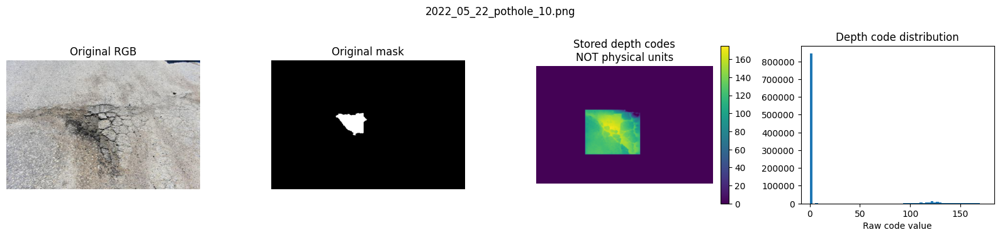


-------------------------------------------------------
Sample: 2022_05_25_pothole_5_horizantal.png
Source group: 2022_05_25_pothole_5
RGB / mask / depth shapes:
(800, 1200, 3) (800, 1200, 3) (800, 1200)
Depth encoding: uint8 L
Raw depth range: 70.0 to 165.0
Unique depth codes: 96
Spatial shapes match: True


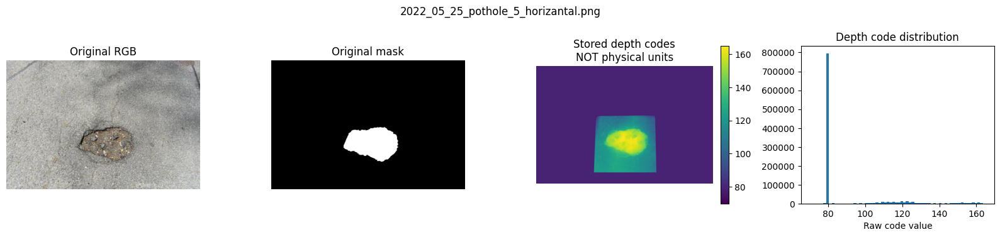


-------------------------------------------------------
Sample: 2022_06_01_pothole_8.png
Source group: 2022_06_01_pothole_8
RGB / mask / depth shapes:
(800, 1200, 3) (800, 1200, 3) (800, 1200)
Depth encoding: uint8 L
Raw depth range: 33.0 to 149.0
Unique depth codes: 117
Spatial shapes match: True


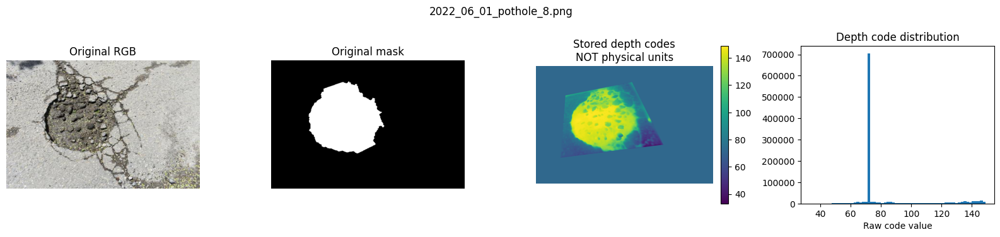


-------------------------------------------------------
Sample: 2022_06_03_pothole_24.png
Source group: 2022_06_03_pothole_24
RGB / mask / depth shapes:
(800, 1200, 3) (800, 1200, 3) (800, 1200)
Depth encoding: uint8 L
Raw depth range: 38.0 to 162.0
Unique depth codes: 125
Spatial shapes match: True


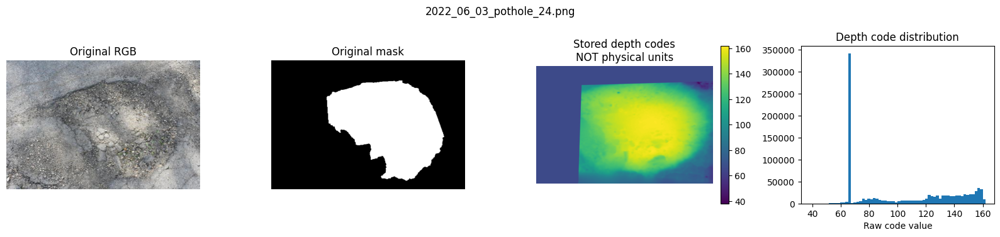


-------------------------------------------------------
Sample: 2022_06_04_pothole_18.png
Source group: 2022_06_04_pothole_18
RGB / mask / depth shapes:
(800, 1200, 3) (800, 1200, 3) (800, 1200)
Depth encoding: uint8 L
Raw depth range: 96.0 to 174.0
Unique depth codes: 79
Spatial shapes match: True


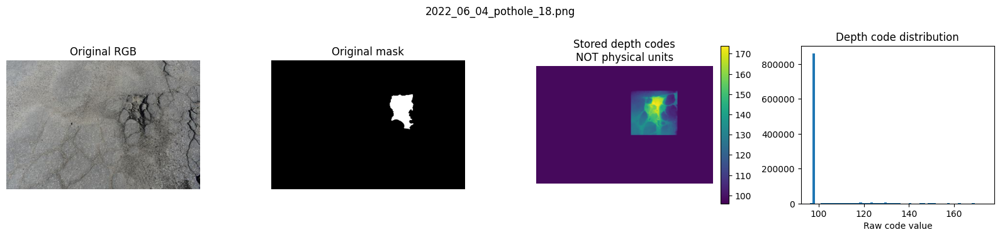


C3-02 SECTION 6 — P440 DATASET READINESS
Complete training triplets: 350
Candidate source groups: 98
Variant filenames: 274
Samples examined: 5
Depth dtypes: ['uint8']
Dimensions matched: 5 / 5
Independent groups verified: NO
Physical scale certified: NO
Model training performed: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-02_section06_P440_20261020T071225_156946Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SUPPLEMENTARY SECTION 6
# POTHOLE440 GROUPING AND DEPTH ENCODING READINESS
# Version: 1.0
#
# TRAIN FOLDER ONLY | READ-ONLY INPUTS
# NO VALIDATION OR TEST ACCESS
# NO PHYSICAL DEPTH CONVERSION OR MODEL TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json
import re

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "Pothole440-main"
)

TRAIN = ROOT / "train"

OUT_ROOT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1/02_dataset_audits"
)

assert TRAIN.is_dir()
assert OUT_ROOT.is_dir()

DIRS = {
    "rgb": TRAIN / "rgb",
    "mask": TRAIN / "mask",
    "depth": TRAIN / "depth",
}

for path in DIRS.values():
    assert path.is_dir()

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

# ------------------------------------------------------------
# 1. INVENTORY TRAIN FILE NAMES ONLY
# ------------------------------------------------------------

names = {}

for kind, folder in DIRS.items():

    names[kind] = {
        p.name
        for p in folder.iterdir()
        if p.is_file()
        and not p.is_symlink()
        and p.suffix.lower() == ".png"
    }

common = sorted(
    names["rgb"] & names["mask"] & names["depth"]
)

mismatched = {
    kind: sorted(files - set(common))
    for kind, files in names.items()
}

print("=" * 65)
print("C3-02 — POTHOLE440 TRAINING DATA READINESS")
print("=" * 65)

for kind, files in names.items():
    print(f"{kind}: {len(files)} PNG files")

print("Complete training triplets:", len(common))
print(
    "Unmatched names by modality:",
    {k: len(v) for k, v in mismatched.items()}
)

assert common, "No matched training triplets"

# ------------------------------------------------------------
# 2. CONSERVATIVE AUGMENTATION-SOURCE GROUPING
# ------------------------------------------------------------

# Example:
# 2022_05_22_pothole_10.png
# 2022_05_22_pothole_10_vertical.png
# 2022_05_22_pothole_10_aug0.png
#
# All are grouped under the same filename-derived
# source group. This does not prove distinct groups
# are independent physical potholes.

def source_group(filename):

    stem = Path(filename).stem

    match = re.match(
        r"^(.*?_pothole_\d+)(?:_.*)?$",
        stem,
        flags=re.IGNORECASE
    )

    if match:
        return match.group(1), "PATTERN_MATCH"

    return (
        "UNRESOLVED_" + stem,
        "UNRESOLVED"
    )

groups = defaultdict(list)
manifest = []

for filename in common:

    group_id, parse_status = source_group(filename)

    groups[group_id].append(filename)

    manifest.append({
        "filename": filename,
        "source_group_candidate": group_id,
        "group_parse_status": parse_status,
        "is_base_filename": (
            Path(filename).stem == group_id
        ),
        "partition": "train",
        "physical_pothole_independence_verified": False,
        "metric_scale_verified": False,
        "training_approved": False,
    })

aug_count = sum(
    not row["is_base_filename"]
    for row in manifest
)

unresolved = sum(
    row["group_parse_status"] == "UNRESOLVED"
    for row in manifest
)

print("\nGROUPING AUDIT")
print("Filename-derived candidate groups:", len(groups))
print("Non-base / variant filenames:", aug_count)
print("Unresolved group patterns:", unresolved)

print("\nExample candidate groups:")

for group_id in sorted(groups)[:5]:
    print(group_id, ":", len(groups[group_id]), "files")

# ------------------------------------------------------------
# 3. SELECT DISTINCT TRAINING GROUP EXAMPLES
# ------------------------------------------------------------

group_ids = sorted(groups)

sample_count = min(5, len(group_ids))

indices = np.linspace(
    0,
    len(group_ids) - 1,
    sample_count,
    dtype=int
)

selected = []

for index in indices:

    group_id = group_ids[int(index)]
    candidates = sorted(groups[group_id])

    # Prefer the unaugmented/base example.
    base_name = group_id + ".png"

    filename = (
        base_name
        if base_name in candidates
        else candidates[0]
    )

    selected.append((group_id, filename))

print("\nSelected groups:", len(selected))

# ------------------------------------------------------------
# 4. CREATE VERSIONED AUDIT OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUT_ROOT / (
    f"C3-02_section06_P440_{stamp}"
)

OUT.mkdir(exist_ok=False)

records = []

# ------------------------------------------------------------
# 5. INSPECT NATIVE RGB, MASK AND SCANNER-DEPTH PNG
# ------------------------------------------------------------

for group_id, filename in selected:

    paths = {
        key: directory / filename
        for key, directory in DIRS.items()
    }

    for path in paths.values():
        assert path.is_file()
        assert not path.is_symlink()

    with Image.open(paths["rgb"]) as im:
        rgb_mode = im.mode
        rgb = np.asarray(im.convert("RGB"))

    with Image.open(paths["mask"]) as im:
        mask_mode = im.mode
        mask_rgb = np.asarray(im.convert("RGB"))

    with Image.open(paths["depth"]) as im:
        depth_mode = im.mode
        metadata_keys = sorted(im.info.keys())
        depth = np.asarray(im)

    rgb_shape = rgb.shape[:2]
    mask_shape = mask_rgb.shape[:2]
    depth_shape = depth.shape[:2]

    shape_match = (
        rgb_shape == mask_shape == depth_shape
    )

    # Annotation hypothesis only:
    # inspect nonblack values without assuming
    # anything about depth scale.
    damage_candidate = np.any(
        mask_rgb != 0, axis=2
    )

    depth_numeric = depth.astype(np.float64)

    sample = {
        "group_id": group_id,
        "filename": filename,
        "rgb_shape": list(rgb.shape),
        "mask_shape": list(mask_rgb.shape),
        "depth_shape": list(depth.shape),
        "rgb_mode": rgb_mode,
        "mask_mode": mask_mode,
        "depth_mode": depth_mode,
        "depth_dtype": str(depth.dtype),
        "depth_metadata_keys": metadata_keys,
        "shape_match": bool(shape_match),
        "depth_min_raw": float(depth_numeric.min()),
        "depth_max_raw": float(depth_numeric.max()),
        "depth_median_raw": float(
            np.median(depth_numeric)
        ),
        "depth_unique_values": int(
            np.unique(depth).size
        ),
        "depth_zero_fraction": float(
            np.mean(depth_numeric == 0)
        ),
        "damage_candidate_fraction": float(
            damage_candidate.mean()
        ),
        "source_hashes": {
            key: sha256(path)
            for key, path in paths.items()
        },
        "depth_is_metric_certified": False,
        "rgb_depth_registration_certified": False,
    }

    if (
        shape_match
        and depth.ndim == 2
        and damage_candidate.any()
        and (~damage_candidate).any()
    ):

        sample["inside_mask_median_raw"] = float(
            np.median(
                depth_numeric[damage_candidate]
            )
        )

        sample["outside_mask_median_raw"] = float(
            np.median(
                depth_numeric[~damage_candidate]
            )
        )

    else:
        sample["inside_mask_median_raw"] = None
        sample["outside_mask_median_raw"] = None

    records.append(sample)

    print("\n" + "-" * 55)
    print("Sample:", filename)
    print("Source group:", group_id)
    print("RGB / mask / depth shapes:")
    print(rgb.shape, mask_rgb.shape, depth.shape)
    print("Depth encoding:", depth.dtype, depth_mode)
    print(
        "Raw depth range:",
        sample["depth_min_raw"],
        "to",
        sample["depth_max_raw"]
    )
    print(
        "Unique depth codes:",
        sample["depth_unique_values"]
    )
    print("Spatial shapes match:", shape_match)

    # --------------------------------------------------------
    # 6. VISUAL DIAGNOSTICS, NO RESIZING
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 4, figsize=(16, 3.8)
    )

    axes[0].imshow(rgb)
    axes[0].set_title("Original RGB")

    axes[1].imshow(mask_rgb)
    axes[1].set_title("Original mask")

    im = axes[2].imshow(
        depth,
        cmap="viridis"
    )
    axes[2].set_title(
        "Stored depth codes\nNOT physical units"
    )

    fig.colorbar(
        im,
        ax=axes[2],
        fraction=0.046,
        pad=0.04
    )

    axes[3].hist(
        depth_numeric.ravel(),
        bins=64
    )

    axes[3].set_title(
        "Depth code distribution"
    )
    axes[3].set_xlabel("Raw code value")

    for ax in axes[:3]:
        ax.axis("off")

    fig.suptitle(filename)
    fig.tight_layout()

    fig.savefig(
        OUT / (
            Path(filename).stem
            + "_encoding_diagnostic.png"
        ),
        dpi=125,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 7. SAVE MANIFEST, REPORT AND SCIENTIFIC DECISION
# ------------------------------------------------------------

manifest_path = OUT / "p440_train_group_manifest.csv"

pd.DataFrame(manifest).to_csv(
    manifest_path,
    index=False
)

report = {
    "milestone": "C3-02",
    "section": "6_supplementary",
    "version": "1.0",
    "dataset": "Pothole440",
    "partition": "train_only",
    "complete_train_triplets": len(common),
    "candidate_source_groups": len(groups),
    "variant_filename_count": aug_count,
    "unresolved_group_patterns": unresolved,
    "unmatched_file_counts": {
        k: len(v) for k, v in mismatched.items()
    },
    "sampled_group_records": records,
    "source_readme_sha256": sha256(
        ROOT / "README.md"
    ),
    "physical_group_independence_verified": False,
    "source_mask_semantics_verified": False,
    "depth_code_to_mm_conversion_verified": False,
    "depth_registration_verified": False,
    "physical_ground_truth_certified": False,
    "metric_training_authorized": False,
    "validation_or_test_payloads_opened": False,
    "warning": (
        "Filename grouping is conservative and "
        "provisional. Scanner-derived 8-bit depth "
        "images cannot be interpreted as physical "
        "depression without encoding evidence."
    ),
}

report_path = OUT / "p440_readiness_report.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. CHECKSUM NEW OUTPUTS
# ------------------------------------------------------------

checksum_lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        checksum_lines.append(
            f"{sha256(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 6 — P440 DATASET READINESS")
print("=" * 65)

print("Complete training triplets:", len(common))
print("Candidate source groups:", len(groups))
print("Variant filenames:", aug_count)
print("Samples examined:", len(records))
print(
    "Depth dtypes:",
    sorted(set(r["depth_dtype"] for r in records))
)
print(
    "Dimensions matched:",
    sum(r["shape_match"] for r in records),
    "/", len(records)
)
print("Independent groups verified: NO")
print("Physical scale certified: NO")
print("Model training performed: NO")
print("Saved:", OUT)

print("=" * 65)


Section 6 integrity: PASS
Original groups: 98
Base filenames: 76
Variant filenames: 274


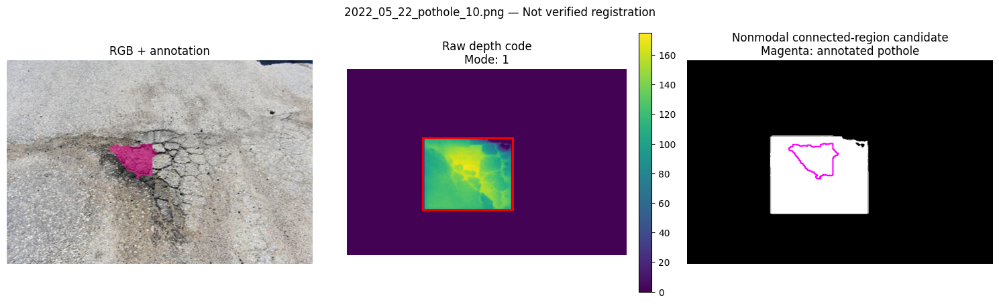


 2022_05_22_pothole_10.png
Modal raw code: 1
Modal pixel fraction: 0.8788
Damage inside candidate footprint: 100.0 %
Footprint status: DOMINANT_CONSTANT_CODE


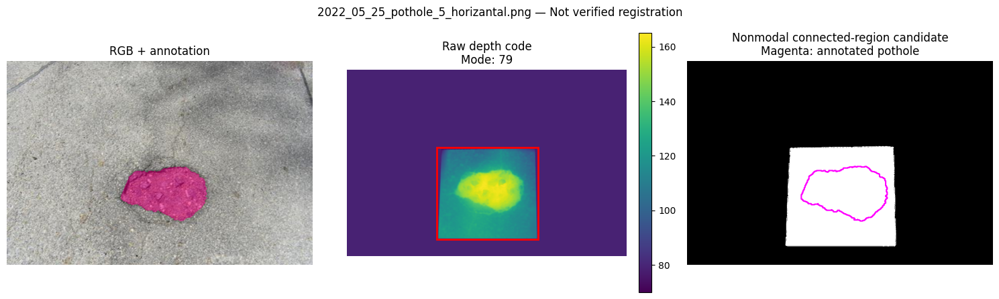


 2022_05_25_pothole_5_horizantal.png
Modal raw code: 79
Modal pixel fraction: 0.8293
Damage inside candidate footprint: 100.0 %
Footprint status: DOMINANT_CONSTANT_CODE


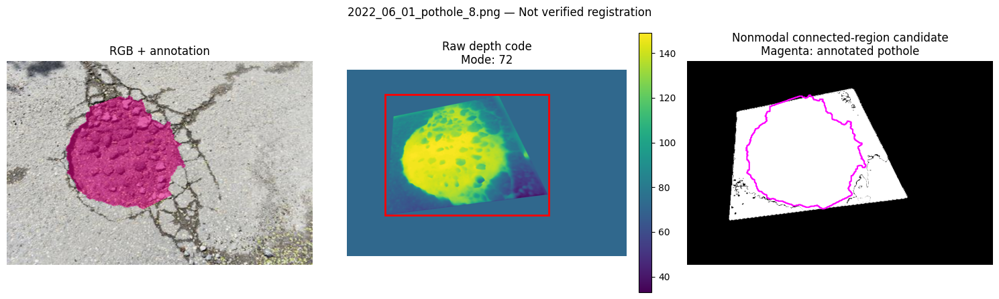


 2022_06_01_pothole_8.png
Modal raw code: 72
Modal pixel fraction: 0.7354
Damage inside candidate footprint: 99.66 %
Footprint status: DOMINANT_CONSTANT_CODE


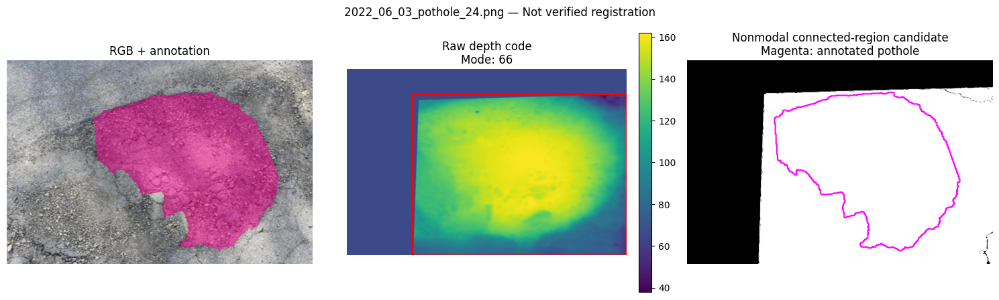


 2022_06_03_pothole_24.png
Modal raw code: 66
Modal pixel fraction: 0.355
Damage inside candidate footprint: 100.0 %
Footprint status: AMBIGUOUS_MODAL_CODE


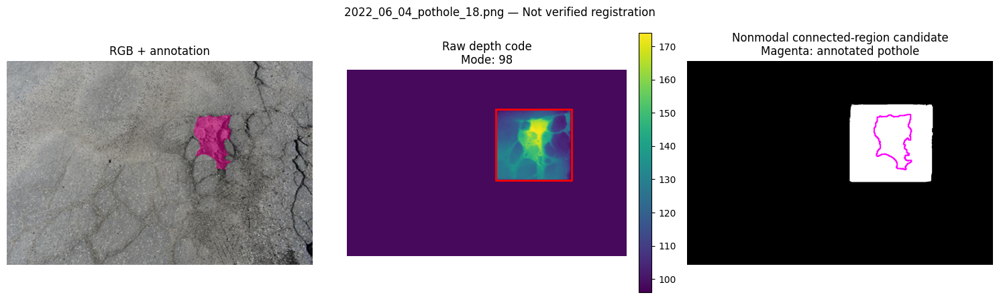


 2022_06_04_pothole_18.png
Modal raw code: 98
Modal pixel fraction: 0.8977
Damage inside candidate footprint: 100.0 %
Footprint status: DOMINANT_CONSTANT_CODE

C3-02 SECTION 7 — POTHOLE440 FOOTPRINT AUDIT
Training samples inspected: 5
Physical depth units verified: NO
Pixel registration certified: NO
Metric training authorized: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-02_section07_P440_20261020T071729_555306Z


In [ ]:

# ============================================================
# CRDL C3-02 — SUPPLEMENTARY SECTION 7
# POTHOLE440 SCANNER-FOOTPRINT / MASK CORRESPONDENCE
# Version 1.0
# Training examples only | No metric assumptions
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from scipy import ndimage
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
import re

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)
ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "Pothole440-main"
)
PREVIOUS = PROJECT / (
    "02_dataset_audits/"
    "C3-02_section06_P440_20261020T071225_156946Z"
)
OUT_ROOT = PROJECT / "02_dataset_audits"

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# ------------------------------------------------------------
# 1. VERIFY SECTION 6 EVIDENCE
# ------------------------------------------------------------

expected = {}

for line in (
    PREVIOUS / "checksums.sha256"
).read_text().splitlines():
    if not line.strip():
        continue
    value, name = line.split(None, 1)
    name = name.strip()
    assert Path(name).name == name
    expected[name] = value

for name in [
    "p440_readiness_report.json",
    "p440_train_group_manifest.csv"
]:
    assert sha256(PREVIOUS / name) == expected[name]

prior = json.loads(
    (
        PREVIOUS / "p440_readiness_report.json"
    ).read_text(encoding="utf-8")
)

assert prior["complete_train_triplets"] == 350
assert prior["metric_training_authorized"] is False

manifest = pd.read_csv(
    PREVIOUS / "p440_train_group_manifest.csv"
)

assert len(manifest) == 350
assert (manifest["partition"] == "train").all()

print("Section 6 integrity: PASS")
print("Original groups:", prior["candidate_source_groups"])
print(
    "Base filenames:",
    int(manifest["is_base_filename"].sum())
)
print(
    "Variant filenames:",
    prior["variant_filename_count"]
)

# ------------------------------------------------------------
# 2. USE ONLY THE PREVIOUSLY INSPECTED TRAIN SAMPLES
# ------------------------------------------------------------

samples = prior["sampled_group_records"]
assert len(samples) == 5

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUT_ROOT / f"C3-02_section07_P440_{stamp}"
OUT.mkdir(exist_ok=False)

results = []

for old in samples:

    filename = old["filename"]

    assert re.fullmatch(
        r"[A-Za-z0-9_]+\.png", filename
    )

    assert filename in set(manifest["filename"])

    paths = {
        kind: ROOT / "train" / kind / filename
        for kind in ["rgb", "mask", "depth"]
    }

    for kind, path in paths.items():
        assert path.is_file() and not path.is_symlink()
        assert sha256(path) == old["source_hashes"][kind]

    with Image.open(paths["rgb"]) as im:
        rgb = np.asarray(im.convert("RGB"))

    with Image.open(paths["mask"]) as im:
        mask_rgb = np.asarray(im.convert("RGB"))

    with Image.open(paths["depth"]) as im:
        depth = np.asarray(im)

    assert depth.ndim == 2
    assert rgb.shape[:2] == mask_rgb.shape[:2] == depth.shape

    # These are annotation and code-value hypotheses,
    # not certified correspondence or scanner validity.
    damage = np.any(mask_rgb != 0, axis=2)

    codes, counts = np.unique(
        depth, return_counts=True
    )

    modal_index = int(np.argmax(counts))
    modal_code = int(codes[modal_index])
    modal_fraction = float(
        counts[modal_index] / depth.size
    )

    nonmodal = depth != modal_code

    # Largest connected nonmodal region is only
    # a scanner-footprint CANDIDATE.
    components, number = ndimage.label(nonmodal)

    if number:
        component_sizes = np.bincount(
            components.ravel()
        )
        component_sizes[0] = 0

        largest_id = int(np.argmax(component_sizes))
        footprint = components == largest_id
    else:
        footprint = np.zeros_like(nonmodal)

    if footprint.any():
        ys, xs = np.where(footprint)
        bbox = [
            int(xs.min()), int(ys.min()),
            int(xs.max()) + 1, int(ys.max()) + 1
        ]
    else:
        bbox = None

    overlap = float(
        np.mean(footprint[damage])
    ) if damage.any() else None

    nonmodal_overlap = float(
        np.mean(nonmodal[damage])
    ) if damage.any() else None

    # Coverage is hypothetical because modal values
    # may also occur at genuine scanner points.
    footprint_strength = (
        "DOMINANT_CONSTANT_CODE"
        if modal_fraction >= 0.55
        else "AMBIGUOUS_MODAL_CODE"
    )

    inside_codes = depth[damage & footprint]
    road_codes = depth[~damage & footprint]

    result = {
        "sample": filename,
        "source_group": old["group_id"],
        "modal_depth_code": modal_code,
        "modal_code_fraction": modal_fraction,
        "candidate_footprint_fraction": float(
            footprint.mean()
        ),
        "damage_inside_candidate_footprint_fraction": overlap,
        "damage_on_nonmodal_fraction": nonmodal_overlap,
        "candidate_footprint_bbox_xyxy": bbox,
        "footprint_interpretation": footprint_strength,
        "inside_damage_median_code": (
            float(np.median(inside_codes))
            if inside_codes.size else None
        ),
        "surrounding_median_code": (
            float(np.median(road_codes))
            if road_codes.size else None
        ),
        "scanner_validity_verified": False,
        "image_registration_verified": False,
        "physical_units_verified": False,
    }

    results.append(result)

    # --------------------------------------------------------
    # 3. VISUAL REVIEW
    # --------------------------------------------------------

    overlay = rgb.copy()
    overlay[damage] = (
        0.5 * rgb[damage].astype(np.float32)
        + 0.5 * np.array([255, 0, 150])
    ).astype(np.uint8)

    fig, axes = plt.subplots(
        1, 3, figsize=(15, 4.5)
    )

    axes[0].imshow(overlay)
    axes[0].set_title("RGB + annotation")

    im = axes[1].imshow(depth, cmap="viridis")

    if bbox is not None:
        from matplotlib.patches import Rectangle

        x0, y0, x1, y1 = bbox
        axes[1].add_patch(
            Rectangle(
                (x0, y0),
                x1-x0, y1-y0,
                fill=False,
                edgecolor="red",
                linewidth=2
            )
        )

    axes[1].set_title(
        f"Raw depth code\nMode: {modal_code}"
    )
    fig.colorbar(
        im, ax=axes[1],
        fraction=0.046, pad=0.04
    )

    axes[2].imshow(
        footprint,
        cmap="gray",
        vmin=0, vmax=1
    )
    axes[2].contour(
        damage, levels=[0.5],
        colors=["magenta"],
        linewidths=1.5
    )
    axes[2].set_title(
        "Nonmodal connected-region candidate\n"
        "Magenta: annotated pothole"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        filename + " — Not verified registration"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / (
            Path(filename).stem
            + "_footprint_check.png"
        ),
        dpi=125,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("\n", filename)
    print("Modal raw code:", modal_code)
    print(
        "Modal pixel fraction:",
        round(modal_fraction, 4)
    )
    print(
        "Damage inside candidate footprint:",
        None if overlap is None
        else round(100*overlap, 2), "%"
    )
    print("Footprint status:", footprint_strength)

# ------------------------------------------------------------
# 4. VERSIONED RESEARCH DECISION
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": "7_supplementary",
    "version": "1.0",
    "dataset": "Pothole440",
    "source_section06": PREVIOUS.name,
    "source_report_sha256": sha256(
        PREVIOUS / "p440_readiness_report.json"
    ),
    "training_triplets": 350,
    "candidate_source_groups": 98,
    "samples": results,
    "method": (
        "Modal-code and largest-connected-nonmodal-"
        "region diagnostic; not certified scanner coverage"
    ),
    "source_depth_conversion_known": False,
    "source_pixel_registration_verified": False,
    "physical_metric_scale_verified": False,
    "depth_to_depression_semantics_verified": False,
    "candidate_for_auxiliary_shape_learning": True,
    "approved_for_metric_geometry_training": False,
    "protected_validation_test_opened": False,
    "next_action": (
        "Seek source depth encoding and registration "
        "details. Until then, retain as nonmetric "
        "auxiliary geometry candidate."
    ),
}

report_path = OUT / "p440_footprint_readiness.json"
report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

pd.DataFrame(results).to_csv(
    OUT / "p440_footprint_summary.csv",
    index=False
)

hash_lines = []

for path in sorted(OUT.iterdir()):
    if path.is_file():
        hash_lines.append(
            f"{sha256(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(hash_lines) + "\n",
    encoding="utf-8"
)

print("\n" + "="*65)
print("C3-02 SECTION 7 — POTHOLE440 FOOTPRINT AUDIT")
print("="*65)
print("Training samples inspected:", len(results))
print("Physical depth units verified: NO")
print("Pixel registration certified: NO")
print("Metric training authorized: NO")
print("Saved:", OUT)
print("="*65)


Previous Pothole440 audit integrity: PASS

Training directory: /content/drive/MyDrive/manushi_research_data/pothole600/pothole600/training
Validation/test directories: NOT OPENED

POTHOLE600 TRAINING SOURCE INVENTORY
rgb : 240
label : 240
tdisp : 240
Matched training triplets: 240
Unmatched counts: {'rgb': 0, 'label': 0, 'tdisp': 0}

-------------------------------------------------------
Sample: 0000.png
RGB / label / tdisp: (400, 400, 3) (400, 400, 3) (400, 400, 3)
Transformed disparity: uint8 RGB
Raw range: 73.0 to 189.0
Label colors: 2
Top label colors: [{'rgb': [0, 0, 0], 'pixels': 155817}, {'rgb': [255, 255, 255], 'pixels': 4183}]
Spatial dimensions match: True


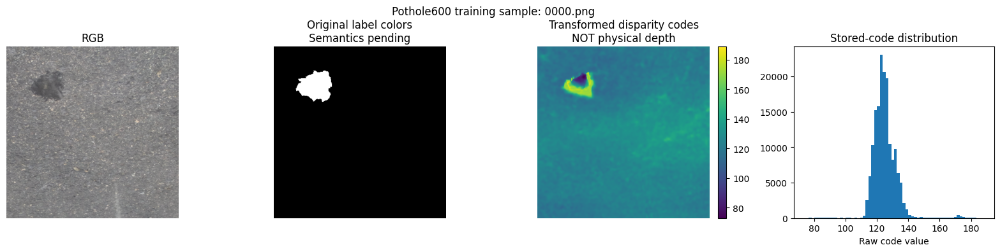


-------------------------------------------------------
Sample: 0059.png
RGB / label / tdisp: (400, 400, 3) (400, 400, 3) (400, 400, 3)
Transformed disparity: uint8 RGB
Raw range: 72.0 to 185.0
Label colors: 2
Top label colors: [{'rgb': [0, 0, 0], 'pixels': 156322}, {'rgb': [255, 255, 255], 'pixels': 3678}]
Spatial dimensions match: True


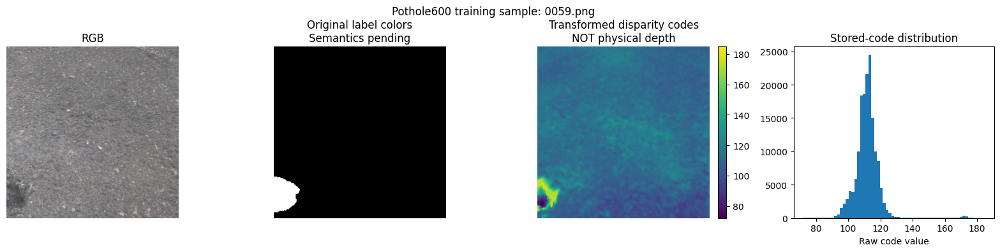


-------------------------------------------------------
Sample: 0119.png
RGB / label / tdisp: (400, 400, 3) (400, 400, 3) (400, 400, 3)
Transformed disparity: uint8 RGB
Raw range: 59.666666666666664 to 171.0
Label colors: 2
Top label colors: [{'rgb': [0, 0, 0], 'pixels': 152875}, {'rgb': [255, 255, 255], 'pixels': 7125}]
Spatial dimensions match: True


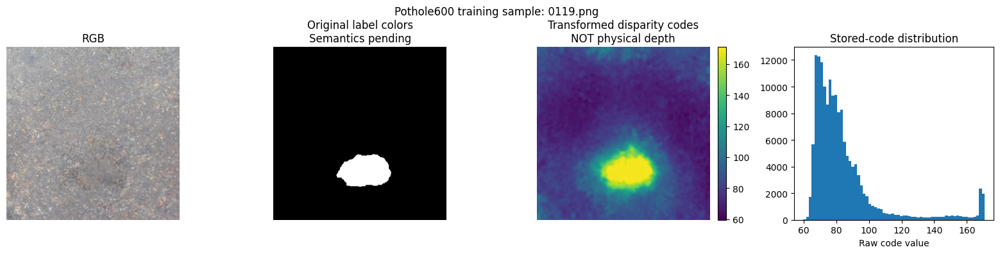


-------------------------------------------------------
Sample: 0179.png
RGB / label / tdisp: (400, 400, 3) (400, 400, 3) (400, 400, 3)
Transformed disparity: uint8 RGB
Raw range: 62.0 to 170.33333333333334
Label colors: 2
Top label colors: [{'rgb': [0, 0, 0], 'pixels': 137954}, {'rgb': [255, 255, 255], 'pixels': 22046}]
Spatial dimensions match: True


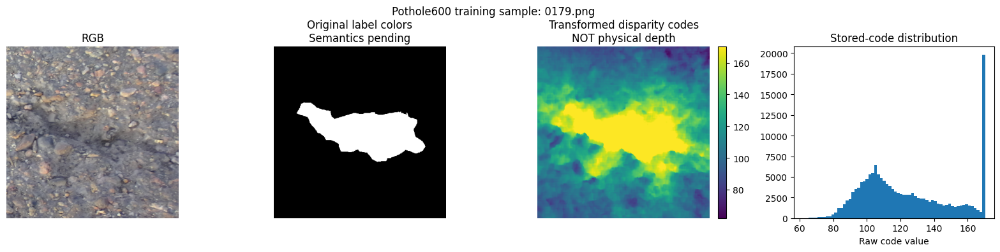


-------------------------------------------------------
Sample: 0239.png
RGB / label / tdisp: (400, 400, 3) (400, 400, 3) (400, 400, 3)
Transformed disparity: uint8 RGB
Raw range: 58.0 to 170.0
Label colors: 2
Top label colors: [{'rgb': [0, 0, 0], 'pixels': 146604}, {'rgb': [255, 255, 255], 'pixels': 13396}]
Spatial dimensions match: True


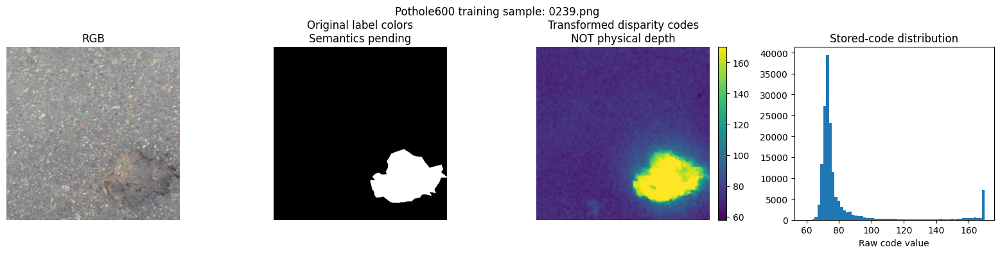


C3-02 SECTION 8 — POTHOLE600 READINESS
Training triplets: 240
Samples inspected: 5
Spatial shape matches: 5 / 5
Transformed disparity types: ['uint8']
Physical scale certified: NO
Scene independence verified: NO
Metric geometry training authorized: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-02_section08_P600_20261020T072458_120046Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SUPPLEMENTARY SECTION 8
# POTHOLE600 RGB / LABEL / TRANSFORMED DISPARITY AUDIT
# Version 1.0
#
# TRAINING PARTITION ONLY | READ-ONLY SOURCE DATA
# NO SPLIT ASSIGNMENT | NO METRIC LABELS | NO TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

AUDIT = PROJECT / "02_dataset_audits"

PRIOR = AUDIT / (
    "C3-02_section07_P440_20261020T071729_555306Z"
)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS DATASET-READINESS EVIDENCE
# ------------------------------------------------------------

checksums = {}

for line in (
    PRIOR / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, name = line.split(None, 1)
        name = name.strip()
        assert Path(name).name == name
        checksums[name] = digest

prior_file = PRIOR / "p440_footprint_readiness.json"

assert sha256(prior_file) == checksums[prior_file.name]

prior_report = json.loads(
    prior_file.read_text(encoding="utf-8")
)

assert prior_report["approved_for_metric_geometry_training"] is False

print("Previous Pothole440 audit integrity: PASS")

# ------------------------------------------------------------
# 2. IDENTIFY THE KNOWN POTHOLE600 TRAINING FOLDER
# ------------------------------------------------------------

candidates = [
    DATA / "pothole600" / "pothole600" / "training",
    DATA / "pothole600" / "training",
]

required = ("rgb", "label", "tdisp")

available = [
    folder for folder in candidates
    if folder.is_dir()
    and all(
        (folder / name).is_dir()
        for name in required
    )
]

if not available:
    raise FileNotFoundError(
        "Pothole600 training modalities not found. "
        "Check the dataset location before proceeding."
    )

TRAIN = available[0]

print("\nTraining directory:", TRAIN)
print("Validation/test directories: NOT OPENED")

# ------------------------------------------------------------
# 3. AUDIT TRAINING FILENAMES ONLY
# ------------------------------------------------------------

names = {}

for kind in required:

    folder = TRAIN / kind

    names[kind] = {
        p.name
        for p in folder.iterdir()
        if p.is_file()
        and not p.is_symlink()
        and p.suffix.lower() == ".png"
    }

matched = set.intersection(
    *(names[name] for name in required)
)

def filename_sort(name):
    stem = Path(name).stem
    return (
        (0, int(stem))
        if stem.isdigit()
        else (1, stem)
    )

matched = sorted(
    matched, key=filename_sort
)

unmatched = {
    kind: len(names[kind] - set(matched))
    for kind in required
}

assert matched, "No complete Pothole600 training triplets"

print("\n" + "=" * 65)
print("POTHOLE600 TRAINING SOURCE INVENTORY")
print("=" * 65)

for kind in required:
    print(kind, ":", len(names[kind]))

print("Matched training triplets:", len(matched))
print("Unmatched counts:", unmatched)

# ------------------------------------------------------------
# 4. SELECT FIVE DETERMINISTIC TRAINING EXAMPLES
# ------------------------------------------------------------

sample_count = min(5, len(matched))

indices = np.linspace(
    0, len(matched)-1,
    sample_count,
    dtype=int
)

selected = [matched[int(i)] for i in indices]

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = AUDIT / f"C3-02_section08_P600_{stamp}"
OUT.mkdir(exist_ok=False)

records = []

# ------------------------------------------------------------
# 5. READ ORIGINAL RGB, LABEL AND TDISP
# ------------------------------------------------------------

for filename in selected:

    paths = {
        kind: TRAIN / kind / filename
        for kind in required
    }

    for path in paths.values():
        assert path.is_file()
        assert not path.is_symlink()

    with Image.open(paths["rgb"]) as im:
        rgb_mode = im.mode
        rgb = np.asarray(im.convert("RGB"))

    with Image.open(paths["label"]) as im:
        label_mode = im.mode
        label_rgb = im.convert("RGB")
        label = np.asarray(label_rgb)

        colors = label_rgb.getcolors(
            maxcolors=4096
        )

    with Image.open(paths["tdisp"]) as im:
        disparity_mode = im.mode
        disparity_metadata = sorted(im.info.keys())
        disparity = np.asarray(im)

    if disparity.ndim == 2:
        display_disp = disparity.astype(np.float64)

    elif disparity.ndim == 3:
        # Visualization only.
        # The mean of channels is NOT calibrated disparity.
        display_disp = disparity.astype(
            np.float64
        ).mean(axis=2)

    else:
        raise ValueError(
            f"Unexpected transformed disparity shape: "
            f"{disparity.shape}"
        )

    dimensions_match = (
        rgb.shape[:2]
        == label.shape[:2]
        == disparity.shape[:2]
    )

    if colors is None:
        label_count = None
        top_colors = []

    else:
        label_count = len(colors)

        top_colors = [
            {
                "rgb": list(color),
                "pixels": int(count)
            }
            for count, color in sorted(
                colors, reverse=True
            )[:6]
        ]

    record = {
        "filename": filename,
        "partition": "training",
        "rgb_shape": list(rgb.shape),
        "label_shape": list(label.shape),
        "tdisp_shape": list(disparity.shape),
        "rgb_mode": rgb_mode,
        "label_mode": label_mode,
        "tdisp_mode": disparity_mode,
        "tdisp_dtype": str(disparity.dtype),
        "tdisp_metadata_keys": disparity_metadata,
        "dimensions_match": bool(dimensions_match),
        "label_unique_color_count": label_count,
        "label_top_colors": top_colors,
        "tdisp_raw_min": float(display_disp.min()),
        "tdisp_raw_max": float(display_disp.max()),
        "tdisp_raw_median": float(
            np.median(display_disp)
        ),
        "tdisp_unique_display_values": int(
            np.unique(display_disp).size
        ),
        "tdisp_zero_fraction": float(
            np.mean(display_disp == 0)
        ),
        "tdisp_source_transform_verified": False,
        "stereo_metric_calibration_verified": False,
        "physical_scene_group_verified": False,
        "source_hashes": {
            key: sha256(path)
            for key, path in paths.items()
        },
    }

    records.append(record)

    print("\n" + "-" * 55)
    print("Sample:", filename)

    print(
        "RGB / label / tdisp:",
        rgb.shape,
        label.shape,
        disparity.shape
    )

    print(
        "Transformed disparity:",
        disparity.dtype,
        disparity_mode
    )

    print(
        "Raw range:",
        record["tdisp_raw_min"],
        "to",
        record["tdisp_raw_max"]
    )

    print("Label colors:", label_count)
    print("Top label colors:", top_colors[:3])
    print("Spatial dimensions match:", dimensions_match)

    # --------------------------------------------------------
    # 6. VISUALIZE WITHOUT RESIZING OR RESCALING SOURCES
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, 4, figsize=(16, 4)
    )

    axes[0].imshow(rgb)
    axes[0].set_title("RGB")

    axes[1].imshow(label)
    axes[1].set_title(
        "Original label colors\nSemantics pending"
    )

    im = axes[2].imshow(
        display_disp, cmap="viridis"
    )

    axes[2].set_title(
        "Transformed disparity codes\nNOT physical depth"
    )

    fig.colorbar(
        im, ax=axes[2],
        fraction=0.046, pad=0.04
    )

    axes[3].hist(
        display_disp.ravel(),
        bins=64
    )

    axes[3].set_title(
        "Stored-code distribution"
    )
    axes[3].set_xlabel("Raw code value")

    for ax in axes[:3]:
        ax.axis("off")

    fig.suptitle(
        f"Pothole600 training sample: {filename}"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / (
            Path(filename).stem
            + "_modality_audit.png"
        ),
        dpi=125,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 7. CREATE TRAINING-ONLY SOURCE MANIFEST
# ------------------------------------------------------------

manifest_rows = []

for name in matched:
    manifest_rows.append({
        "filename": name,
        "partition": "training",
        "rgb_present": True,
        "label_present": True,
        "tdisp_present": True,
        "physical_scene_group": "UNKNOWN",
        "geometry_units": "UNVERIFIED",
        "metric_supervision_approved": False,
    })

pd.DataFrame(manifest_rows).to_csv(
    OUT / "p600_training_manifest.csv",
    index=False
)

pd.DataFrame([
    {
        key: (
            json.dumps(value)
            if isinstance(value, (dict, list))
            else value
        )
        for key, value in record.items()
    }
    for record in records
]).to_csv(
    OUT / "p600_sample_encoding_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 8. SAVE SCIENTIFIC READINESS REPORT
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": "8_supplementary",
    "version": "1.0",
    "dataset": "Pothole600",
    "source_partition": "training_only",
    "training_directory": str(TRAIN),
    "modality_counts": {
        key: len(value)
        for key, value in names.items()
    },
    "matched_training_triplets": len(matched),
    "unmatched_counts": unmatched,
    "sampled_records": records,
    "source_transformed_disparity": True,
    "transformation_formula_verified": False,
    "metric_stereo_calibration_verified": False,
    "physical_depth_scale_verified": False,
    "physical_scene_grouping_verified": False,
    "segmentation_semantics_verified": False,
    "approved_for_metric_geometry_training": False,
    "validation_test_data_accessed": False,
    "source_images_modified": False,
    "next_decision": (
        "Classify transformed disparity for nonmetric "
        "auxiliary learning only unless its source "
        "transformation and calibration are established."
    ),
}

report_path = OUT / "p600_readiness_report.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 9. CHECKSUM OUTPUT ARTIFACTS
# ------------------------------------------------------------

checksums = []

for path in sorted(OUT.iterdir()):
    if path.is_file():
        checksums.append(
            f"{sha256(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksums) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 8 — POTHOLE600 READINESS")
print("=" * 65)

print("Training triplets:", len(matched))
print("Samples inspected:", len(records))

print(
    "Spatial shape matches:",
    sum(
        r["dimensions_match"]
        for r in records
    ),
    "/", len(records)
)

print(
    "Transformed disparity types:",
    sorted(set(
        r["tdisp_dtype"]
        for r in records
    ))
)

print("Physical scale certified: NO")
print("Scene independence verified: NO")
print("Metric geometry training authorized: NO")
print("Saved:", OUT)

print("=" * 65)


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SUPPLEMENTARY SECTION 9
# SHREC POTHOLE MIX SOURCE-OVERLAP / SPLIT AUDIT
# Version 1.0
#
# ZIP CENTRAL DIRECTORY ONLY
# NO IMAGE, VIDEO, MASK OR TEST PAYLOADS READ
# NO TRAINING | NO METRIC LABELS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import zipfile
import hashlib
import json
import re
import csv

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

PRIOR = PROJECT / (
    "02_dataset_audits/"
    "C3-00_section06_20261020T045151_544193Z"
)

ARCHIVE = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "shrec2022/kfth5g2xk3-2/Pothole-Mix/"
    "pothole-mix-v1.0-20220526.zip"
)

OUT_ROOT = PROJECT / "02_dataset_audits"

assert ARCHIVE.is_file()
assert PRIOR.is_dir()
assert OUT_ROOT.is_dir()

# ------------------------------------------------------------
# 1. VERIFY PRIOR RESEARCH INVENTORY
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


expected = {}

for line in (
    PRIOR / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        value, name = line.split(None, 1)
        name = name.strip()

        if Path(name).name != name:
            raise ValueError("Unsafe checksum record")

        expected[name] = value

prior_path = PRIOR / "source_calibration_evidence.json"

assert sha256(prior_path) == expected[prior_path.name]

prior = json.loads(
    prior_path.read_text(encoding="utf-8")
)

prior_index = prior[
    "shrec_zip_indexes"
]["SHREC Pothole-Mix"]

assert prior_index["status"] == "CENTRAL_DIRECTORY_READ"

assert ARCHIVE.stat().st_size == (
    prior_index["archive_bytes"]
)

print("C3-00 SHREC evidence: VERIFIED")

# ------------------------------------------------------------
# 2. DEFINE CONSERVATIVE PARTITION RULES
# ------------------------------------------------------------

TRAIN_PARTS = {
    "train", "training"
}

PROTECTED_PARTS = {
    "val", "valid", "validation",
    "test", "testing", "evaluation",
    "eval", "benchmark", "holdout", "heldout"
}

def path_parts(name):
    return [
        part.lower()
        for part in re.split(r"[/\\]+", name)
        if part
    ]


def partition(name):

    parts = set(path_parts(name))

    if parts & PROTECTED_PARTS:
        return "PROTECTED_OR_EVALUATION"

    if parts & TRAIN_PARTS:
        return "EXPLICIT_TRAIN"

    return "UNDETERMINED"


def source_family(name):

    normalized = name.lower().replace(
        "-", ""
    ).replace("_", "").replace(" ", "")

    families = {
        "pothole600": "POTHOLE600_OVERLAP_CANDIDATE",
        "crack500": "CRACK500_SOURCE_CANDIDATE",
        "gap": "GAP_SOURCE_CANDIDATE",
        "cprid": "CPRID_SOURCE_CANDIDATE",
        "edmcrack": "EDMCRACK_SOURCE_CANDIDATE",
    }

    for token, family in families.items():
        if token in normalized:
            return family

    return "SOURCE_UNRESOLVED"


# ------------------------------------------------------------
# 3. READ THE ZIP INDEX, NOT THE FILE CONTENTS
# ------------------------------------------------------------

print("\nInspecting SHREC ZIP central directory...")
print("No ZIP members will be opened.")

partition_counts = Counter()
extension_counts = Counter()
source_counts = Counter()

safe_training_entries = []

with zipfile.ZipFile(ARCHIVE, "r") as z:

    items = z.infolist()

    total_entries = len(items)

    for item in items:

        if item.is_dir():
            continue

        role = partition(item.filename)

        partition_counts[role] += 1

        if role != "EXPLICIT_TRAIN":
            # Never store or display protected/
            # unidentified member paths.
            continue

        extension = Path(
            item.filename
        ).suffix.lower()

        family = source_family(
            item.filename
        )

        extension_counts[extension] += 1
        source_counts[family] += 1

        safe_training_entries.append({
            "path": item.filename,
            "source_family_candidate": family,
            "extension": extension,
            "uncompressed_bytes": item.file_size,
            "crc32": f"{item.CRC:08x}",
            "source_payload_read": False,
        })

assert total_entries == (
    prior_index["total_zip_entries_including_directories"]
)

print("\nTOTAL ZIP ENTRIES:", total_entries)

print("\nPARTITION DISCOVERY")

for name, count in sorted(
    partition_counts.items()
):
    print(name, ":", count)

print("\nEXPLICIT TRAIN FILE EXTENSIONS")

for name, count in sorted(
    extension_counts.items()
):
    print(name, ":", count)

print("\nTRAINING SOURCE-FAMILY CANDIDATES")

for name, count in sorted(
    source_counts.items()
):
    print(name, ":", count)

print("\nFIRST 15 SAFE TRAIN ENTRIES")

for entry in safe_training_entries[:15]:
    print(entry["path"])

# ------------------------------------------------------------
# 4. RECORD CROSS-DATASET LEAKAGE RISK
# ------------------------------------------------------------

# From the published Pothole Mix description:
# It incorporates several existing public datasets.
# Pothole600 is one such source.
#
# This is a DOCUMENTED provenance risk, not
# an observed SHA-level duplicate yet.

provenance = {
    "published_source": (
        "https://data.mendeley.com/datasets/"
        "kfth5g2xk3"
    ),
    "related_pothole600": (
        "https://sites.google.com/view/"
        "pothole-600/dataset"
    ),
    "documented_source_reuse_risk": True,
    "exact_cross_dataset_duplicates_verified": False,
    "independent_physical_scenes_verified": False,
    "required_policy": (
        "Do not combine SHREC and original "
        "Pothole600 as independent sources "
        "until overlap is resolved."
    ),
}

# ------------------------------------------------------------
# 5. DETERMINE WHAT IS SAFE TO CLAIM
# ------------------------------------------------------------

train_count = partition_counts["EXPLICIT_TRAIN"]

if train_count == 0:

    readiness = "TRAIN_PARTITION_NOT_RESOLVED"

else:

    readiness = "TRAIN_METADATA_DISCOVERED"

# A filename that does not identify a dataset
# cannot prove the material is independent.

metric_status = "NOT_CERTIFIED"
training_status = "NOT_APPROVED"

# ------------------------------------------------------------
# 6. CREATE VERSIONED RESEARCH OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUT_ROOT / (
    f"C3-02_section09_SHREC_{stamp}"
)

OUT.mkdir(exist_ok=False)

report = {
    "milestone": "C3-02",
    "section": "9_supplementary",
    "version": "1.0",
    "dataset": "SHREC_2022_Pothole_Mix",
    "archive_name": ARCHIVE.name,
    "archive_size_bytes": ARCHIVE.stat().st_size,
    "previous_inventory_sha256": sha256(
        prior_path
    ),
    "zip_entries_total": total_entries,
    "partition_counts": dict(partition_counts),
    "explicit_train_extensions": dict(
        extension_counts
    ),
    "candidate_source_counts": dict(
        source_counts
    ),
    "safe_training_member_count": train_count,
    "provenance": provenance,
    "status": readiness,
    "metric_scale_status": metric_status,
    "geometry_training_status": training_status,
    "source_images_read": False,
    "archive_members_extracted": False,
    "validation_test_payloads_accessed": False,
    "physical_scene_grouping_verified": False,
    "rgb_disparity_calibration_verified": False,
    "metric_training_authorized": False,
    "next_requirement": (
        "Confirm train-only RGB/mask pairing and "
        "resolve duplicate source identities "
        "before independent-model evaluation."
    )
}

report_file = OUT / "shrec_source_split_audit.json"

report_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# Save ONLY entries positively identified
# as belonging to the training partition.
csv_file = OUT / "shrec_explicit_train_index.csv"

with csv_file.open(
    "w", newline="", encoding="utf-8"
) as f:

    fields = [
        "path",
        "source_family_candidate",
        "extension",
        "uncompressed_bytes",
        "crc32",
        "source_payload_read",
    ]

    writer = csv.DictWriter(
        f, fieldnames=fields
    )

    writer.writeheader()
    writer.writerows(safe_training_entries)

# ------------------------------------------------------------
# 7. EXPORT OUTPUT CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in [report_file, csv_file]:

    lines.append(
        f"{sha256(path)}  {path.name}"
    )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 8. FINAL SCIENTIFIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 9 — SHREC SOURCE AUDIT")
print("=" * 65)

print("Archive integrity metadata: CONSISTENT")
print("Train entries identified:", train_count)

print(
    "Partition status:",
    readiness
)

print(
    "Original Pothole600 overlap:",
    "DOCUMENTED RISK"
)

print("Exact duplicate content verified: NO")
print("Image/video contents opened: NO")
print("Metric training authorized: NO")
print("Report:", OUT)

print("=" * 65)


C3-00 SHREC evidence: VERIFIED

Inspecting SHREC ZIP central directory...
No ZIP members will be opened.

TOTAL ZIP ENTRIES: 8739

PARTITION DISCOVERY
EXPLICIT_TRAIN : 6680
PROTECTED_OR_EVALUATION : 2000
UNDETERMINED : 1

EXPLICIT TRAIN FILE EXTENSIONS
.jpg : 2620
.png : 4060

TRAINING SOURCE-FAMILY CANDIDATES
CRACK500_SOURCE_CANDIDATE : 500
EDMCRACK_SOURCE_CANDIDATE : 960
GAP_SOURCE_CANDIDATE : 706
POTHOLE600_OVERLAP_CANDIDATE : 480
SOURCE_UNRESOLVED : 4034

FIRST 15 SAFE TRAIN ENTRIES
pothole-mix/training/edmcrack600/images/002.png
pothole-mix/training/edmcrack600/images/004.png
pothole-mix/training/edmcrack600/images/005.png
pothole-mix/training/edmcrack600/images/006.png
pothole-mix/training/edmcrack600/images/007.png
pothole-mix/training/edmcrack600/images/008.png
pothole-mix/training/edmcrack600/images/009.png
pothole-mix/training/edmcrack600/images/010.png
pothole-mix/training/edmcrack600/images/012.png
pothole-mix/training/edmcrack600/images/013.png
pothole-mix/training/edmcrac

C3-01 PothRGBD evidence integrity: PASS
Previously inspected depth samples: 3


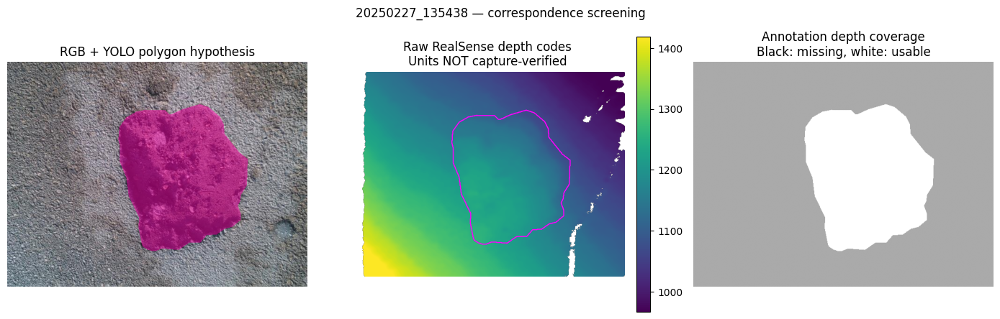


 20250227_135438
Depth dtype: uint16
YOLO class IDs: [0]
Polygons: 1
Valid depth inside annotation: 100.0 %
Raw median: 1169.0
Hypothetical median distance: 1.169 m — NOT CERTIFIED


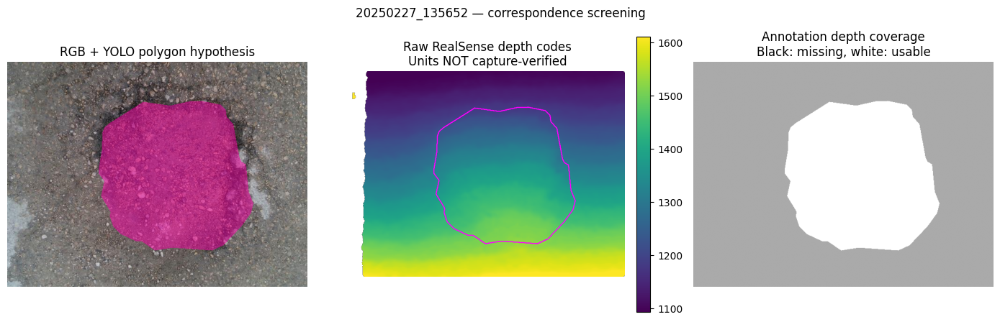


 20250227_135652
Depth dtype: uint16
YOLO class IDs: [0]
Polygons: 1
Valid depth inside annotation: 100.0 %
Raw median: 1335.0
Hypothetical median distance: 1.335 m — NOT CERTIFIED


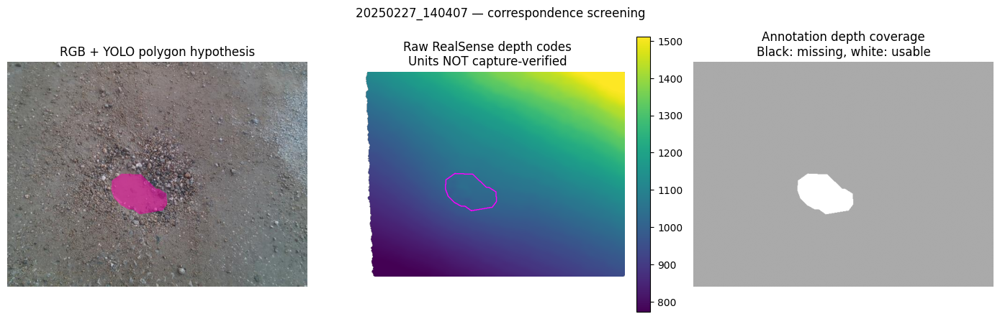


 20250227_140407
Depth dtype: uint16
YOLO class IDs: [0]
Polygons: 1
Valid depth inside annotation: 100.0 %
Raw median: 1055.0
Hypothetical median distance: 1.055 m — NOT CERTIFIED

C3-02 SECTION 10 — POTHRGBD READINESS
Samples inspected: 3
Correspondence status: {'GEOMETRIC_READINESS_INSPECTED': 3}
Physical units certified: NO
Metric CRDL training authorized: NO
Scene-level splits frozen: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-02_section10_PothRGBD_20261020T074328_485180Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SUPPLEMENTARY SECTION 10
# POTHRGBD RGB / POLYGON / DEPTH READINESS
# Version 1.0
#
# 3 PREVIOUSLY INSPECTED DEVELOPMENT EXAMPLES
# NO TRAIN/VAL SPLIT | NO METRIC TARGET GENERATION
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import hashlib
import json

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

PRIOR = PROJECT / (
    "02_dataset_audits/"
    "C3-01_section01_20261020T045938_052906Z"
)

OUT_ROOT = PROJECT / "02_dataset_audits"

for path in [
    ROOT / "images",
    ROOT / "labels",
    ROOT / "depths",
    PRIOR,
    OUT_ROOT
]:
    assert path.is_dir(), str(path)


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


# ------------------------------------------------------------
# 1. VERIFY C3-01 ORIGINAL DEPTH EVIDENCE
# ------------------------------------------------------------

prior_report_path = (
    PRIOR / "pothrgbd_scale_evidence.json"
)

expected = {}

for line in (
    PRIOR / "checksums.sha256"
).read_text().splitlines():

    if not line.strip():
        continue

    digest, name = line.split(None, 1)
    name = name.strip()

    assert Path(name).name == name
    expected[name] = digest

assert sha256(prior_report_path) == expected[
    prior_report_path.name
]

prior_report = json.loads(
    prior_report_path.read_text(encoding="utf-8")
)

assert prior_report["section"] == 1
assert prior_report["metric_training_authorized"] is False

samples = prior_report["raw_depth_samples"]

assert len(samples) == 3

print("C3-01 PothRGBD evidence integrity: PASS")
print("Previously inspected depth samples:", len(samples))


# ------------------------------------------------------------
# 2. YOLO POLYGON READER
# ------------------------------------------------------------

def read_yolo_polygons(path, width, height):

    canvas = Image.new(
        "L", (width, height), 0
    )

    drawer = ImageDraw.Draw(canvas)

    class_ids = []
    polygon_count = 0

    lines = path.read_text(
        encoding="utf-8"
    ).splitlines()

    for line in lines:

        if not line.strip():
            continue

        tokens = line.split()
        values = [float(x) for x in tokens]

        if not np.isfinite(values).all():
            raise ValueError("Nonfinite polygon coordinates")

        cls = values[0]

        if cls != int(cls) or cls < 0:
            raise ValueError("Invalid YOLO class identifier")

        coords = values[1:]

        if len(coords) < 6 or len(coords) % 2:
            raise ValueError("Invalid YOLO polygon length")

        points = np.array(
            coords, dtype=np.float64
        ).reshape(-1, 2)

        if np.any(points < -0.001) or np.any(
            points > 1.001
        ):
            raise ValueError(
                "YOLO polygon is outside normalized range"
            )

        points = np.clip(points, 0, 1)

        pixels = [
            (
                int(round(x * (width - 1))),
                int(round(y * (height - 1)))
            )
            for x, y in points
        ]

        drawer.polygon(pixels, fill=1)

        class_ids.append(int(cls))
        polygon_count += 1

    return (
        np.asarray(canvas, dtype=bool),
        polygon_count,
        sorted(set(class_ids))
    )


# ------------------------------------------------------------
# 3. VERSIONED OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUT_ROOT / (
    f"C3-02_section10_PothRGBD_{stamp}"
)

OUT.mkdir(exist_ok=False)

records = []

# One millimetre per stored unit is the
# DEFAULT REALSENSE HYPOTHESIS only.
# Never apply this factor to create approved labels.
HYPOTHETICAL_M_PER_UNIT = 0.001


# ------------------------------------------------------------
# 4. AUDIT THE PREVIOUSLY VERIFIED EXAMPLES
# ------------------------------------------------------------

for sample in samples:

    sample_id = sample["sample_id"]

    depth_path = (
        ROOT / "depths" / sample["filename"]
    )

    assert depth_path.is_file()
    assert not depth_path.is_symlink()

    assert sha256(depth_path) == sample[
        "source_sha256"
    ], "Depth source checksum mismatch"

    rgb_candidates = sorted(
        (ROOT / "images").glob(
            f"{sample_id}_color_png.rf.*.jpg"
        )
    )

    record = {
        "sample_id": sample_id,
        "source_role": "DEVELOPMENT_AUDIT_ONLY",
        "capture_group": "UNVERIFIED",
        "depth_source_sha256": sample[
            "source_sha256"
        ],
        "status": "PENDING",
        "actual_m_per_unit_verified": False,
        "intrinsics_verified": False,
        "registration_verified": False,
        "metric_training_approved": False,
    }

    if len(rgb_candidates) != 1:

        record["status"] = "RGB_MATCH_AMBIGUOUS"
        record["rgb_candidates"] = len(rgb_candidates)

        records.append(record)

        print(
            sample_id,
            "| RGB candidates:", len(rgb_candidates)
        )
        continue

    rgb_path = rgb_candidates[0]

    # Preserve the exact Roboflow identifier.
    label_path = (
        ROOT / "labels"
        / f"{rgb_path.stem}.txt"
    )

    if not label_path.is_file():

        record["status"] = "LABEL_NOT_FOUND"
        records.append(record)

        print(sample_id, "| label not found")
        continue

    if label_path.is_symlink():
        raise RuntimeError("Unexpected label symlink")

    # No pickle deserialization.
    depth = np.load(
        depth_path,
        allow_pickle=False
    )

    with Image.open(rgb_path) as im:
        rgb = np.asarray(im.convert("RGB"))

    if depth.ndim != 2:
        raise ValueError("Expected single-channel depth")

    h, w = depth.shape

    record["depth_shape"] = list(depth.shape)
    record["rgb_shape"] = list(rgb.shape)

    if rgb.shape[:2] != depth.shape:

        record["status"] = "SPATIAL_DIMENSION_MISMATCH"
        records.append(record)

        print(sample_id, "| RGB/depth shape mismatch")
        continue

    mask, polygons, class_ids = read_yolo_polygons(
        label_path, w, h
    )

    if polygons == 0 or not mask.any():

        record["status"] = "EMPTY_POLYGON_ANNOTATION"
        records.append(record)

        print(sample_id, "| empty annotation")
        continue

    finite = (
        np.isfinite(depth)
        & (depth > 0)
    )

    in_mask = mask & finite

    numeric = depth.astype(np.float64)

    record.update({
        "status": "GEOMETRIC_READINESS_INSPECTED",
        "rgb_filename": rgb_path.name,
        "label_filename": label_path.name,
        "rgb_sha256": sha256(rgb_path),
        "label_sha256": sha256(label_path),
        "depth_dtype": str(depth.dtype),
        "polygon_count": polygons,
        "class_ids": class_ids,
        "mask_fraction": float(mask.mean()),
        "valid_depth_fraction": float(finite.mean()),
        "valid_depth_inside_mask_fraction": float(
            in_mask.sum() / mask.sum()
        ),
        "raw_depth_median": float(
            np.median(numeric[finite])
        ),
        "hypothetical_median_m_if_default_scale": float(
            np.median(numeric[finite])
            * HYPOTHETICAL_M_PER_UNIT
        ),
        "hypothetical_scale_is_verified": False,
    })

    records.append(record)

    # --------------------------------------------------------
    # 5. VISUALIZE ANNOTATION AND DEPTH CORRESPONDENCE
    # --------------------------------------------------------

    overlay = rgb.copy()

    overlay[mask] = (
        0.5 * rgb[mask].astype(np.float32)
        + 0.5 * np.array([255, 0, 170])
    ).astype(np.uint8)

    visible_depth = np.where(
        finite, numeric, np.nan
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(14, 4.5)
    )

    axes[0].imshow(overlay)
    axes[0].set_title(
        "RGB + YOLO polygon hypothesis"
    )

    image = axes[1].imshow(
        np.ma.masked_invalid(visible_depth),
        cmap="viridis",
        vmin=np.percentile(numeric[finite], 1),
        vmax=np.percentile(numeric[finite], 99)
    )

    axes[1].contour(
        mask, levels=[0.5],
        colors=["magenta"],
        linewidths=1
    )

    axes[1].set_title(
        "Raw RealSense depth codes\n"
        "Units NOT capture-verified"
    )

    fig.colorbar(
        image, ax=axes[1],
        fraction=0.046, pad=0.04
    )

    validity = np.zeros(
        depth.shape, dtype=np.uint8
    )

    validity[mask & ~finite] = 1
    validity[in_mask] = 2

    from matplotlib.colors import ListedColormap

    axes[2].imshow(
        validity,
        cmap=ListedColormap([
            "#aaaaaa", "#111111", "#ffffff"
        ]),
        vmin=0,
        vmax=2
    )

    axes[2].set_title(
        "Annotation depth coverage\n"
        "Black: missing, white: usable"
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        sample_id + " — correspondence screening"
    )
    fig.tight_layout()

    fig.savefig(
        OUT / f"{sample_id}_correspondence.png",
        dpi=135,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("\n", sample_id)
    print("Depth dtype:", depth.dtype)
    print("YOLO class IDs:", class_ids)
    print("Polygons:", polygons)
    print(
        "Valid depth inside annotation:",
        round(
            100 * record[
                "valid_depth_inside_mask_fraction"
            ], 2
        ), "%"
    )
    print(
        "Raw median:",
        record["raw_depth_median"]
    )
    print(
        "Hypothetical median distance:",
        round(
            record[
                "hypothetical_median_m_if_default_scale"
            ], 3
        ), "m — NOT CERTIFIED"
    )

# ------------------------------------------------------------
# 6. SAVE EVIDENCE AND TRAINING RESTRICTIONS
# ------------------------------------------------------------

status_counts = {}

for record in records:
    key = record["status"]
    status_counts[key] = status_counts.get(key, 0) + 1

report = {
    "milestone": "C3-02",
    "section": "10_supplementary",
    "version": "1.0",
    "dataset": "PothRGBD",
    "source_c301": PRIOR.name,
    "sample_count": len(records),
    "records": records,
    "status_counts": status_counts,
    "reported_sensor": "Intel RealSense D415",
    "manufacturer_default_scale_hypothesis_m_per_unit":
        HYPOTHETICAL_M_PER_UNIT,
    "actual_capture_depth_scale_m_per_unit": None,
    "camera_intrinsics": None,
    "physical_scale_certified": False,
    "registration_certified": False,
    "road_relative_targets_generated": False,
    "independent_scene_splits_verified": False,
    "metric_training_authorized": False,
    "source_files_modified": False,
    "reference_sources": [
        "https://arxiv.org/abs/2505.04207",
        (
            "https://github.com/realsenseai/"
            "librealsense/wiki/Projection-in-RealSense-SDK-2.0"
        )
    ],
    "decision_note": (
        "Tests whether source RGB, YOLO polygons and "
        "16-bit depth maps can support controlled "
        "future road-relative target construction. "
        "Default sensor scale is a hypothesis, not "
        "dataset-specific calibration evidence."
    )
}

report_path = OUT / "pothrgbd_readiness.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

pd.DataFrame([
    {
        k: json.dumps(v)
        if isinstance(v, (list, dict))
        else v
        for k, v in r.items()
    }
    for r in records
]).to_csv(
    OUT / "pothrgbd_readiness_summary.csv",
    index=False
)

checksums = []

for file in sorted(OUT.iterdir()):

    if file.is_file():

        checksums.append(
            f"{sha256(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(checksums) + "\n",
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("C3-02 SECTION 10 — POTHRGBD READINESS")
print("=" * 65)

print("Samples inspected:", len(records))
print("Correspondence status:", status_counts)
print("Physical units certified: NO")
print("Metric CRDL training authorized: NO")
print("Scene-level splits frozen: NO")
print("Saved:", OUT)

print("=" * 65)


C3-02 Section 10 evidence: PASS


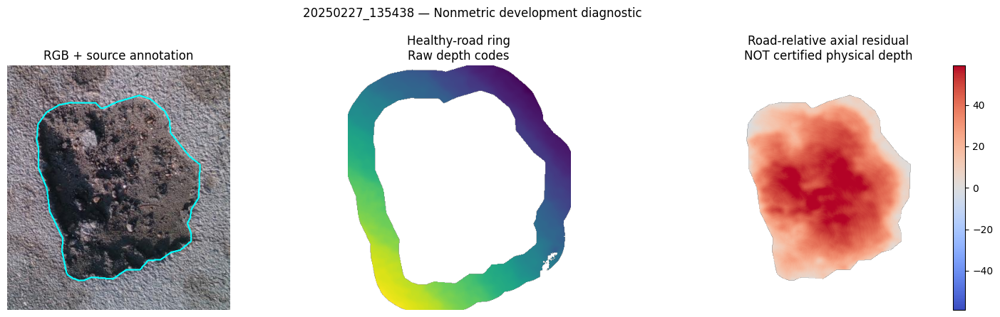


20250227_135438
Valid reference coverage: 100.0 %
Healthy-road absolute P95: 9.084 raw units
Worst spatial holdout P95: 12.366195180626164
Signed axial median: 37.574546813964844 raw units
Positive axial residual fraction: 0.998794408497131
Median absolute signal / road P95: 4.136566638946533


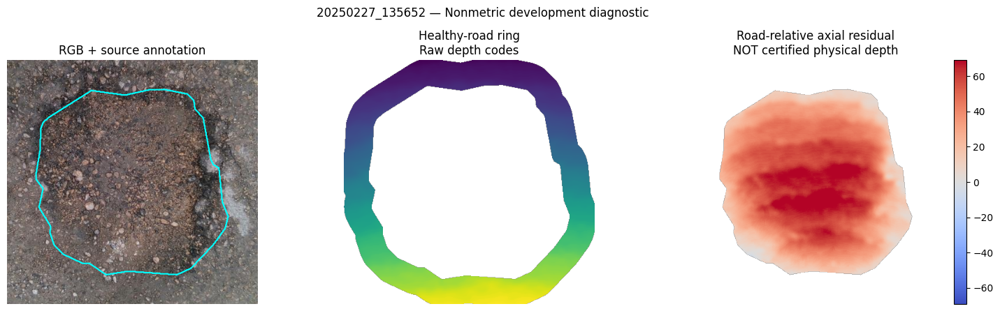


20250227_135652
Valid reference coverage: 100.0 %
Healthy-road absolute P95: 10.816 raw units
Worst spatial holdout P95: 15.040264577206926
Signed axial median: 44.40438461303711 raw units
Positive axial residual fraction: 0.9987111137149218
Median absolute signal / road P95: 4.105490684509277


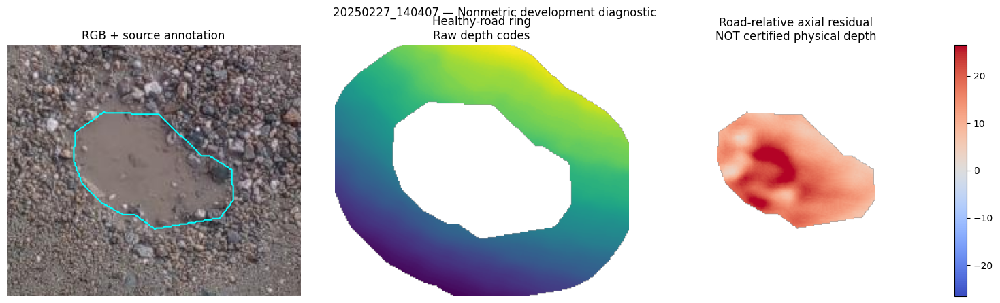


20250227_140407
Valid reference coverage: 100.0 %
Healthy-road absolute P95: 9.322 raw units
Worst spatial holdout P95: 11.699217611029537
Signed axial median: 14.373592376708984 raw units
Positive axial residual fraction: 1.0
Median absolute signal / road P95: 1.5419187545776367

C3-02 SECTION 11 — POTHRGBD ROAD REFERENCE
Samples tested: 3
Physical depth scale certified: NO
Independent evaluation: NO
Targets approved for training: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section11_PothRGBD_ReferenceQA_20261020T075404_802070Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 11
# POTHRGBD ROBUST INVERSE-DEPTH ROAD REFERENCE
# Version 1.0
#
# 3 previously inspected development samples ONLY
# NONMETRIC DIAGNOSTICS | NO ML TRAINING
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import numpy as np
import matplotlib.pyplot as plt
import hashlib
import json

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

PREVIOUS = PROJECT / (
    "02_dataset_audits/"
    "C3-02_section10_PothRGBD_20261020T074328_485180Z"
)

OUTROOT = PROJECT / "04_geometry_targets"

assert PREVIOUS.is_dir()
assert OUTROOT.is_dir()

# ------------------------------------------------------------
# 1. VERIFY PREVIOUS RESEARCH EVIDENCE
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


checks = {}

for line in (
    PREVIOUS / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, filename = line.split(None, 1)
        filename = filename.strip()

        assert Path(filename).name == filename

        checks[filename] = digest


report_file = (
    PREVIOUS / "pothrgbd_readiness.json"
)

assert sha256(report_file) == checks[
    report_file.name
]

prior = json.loads(report_file.read_text())

assert prior["sample_count"] == 3
assert prior["metric_training_authorized"] is False

assert all(
    r["status"] == "GEOMETRIC_READINESS_INSPECTED"
    for r in prior["records"]
)

print("C3-02 Section 10 evidence: PASS")

# ------------------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

CFG = {
    "ring_inner_px": 8,
    "ring_outer_px": 55,
    "max_support": 18000,
    "seed": 20261020,
    "max_iterations": 12,
    "ring_low_quantile": 0.001,
    "ring_high_quantile": 0.999,
}

# No millimetre conversion.
# The inverse-depth factor of 1000 used below
# is numerical conditioning only.

# ------------------------------------------------------------
# 3. RECONSTRUCT ORIGINAL YOLO POLYGON
# ------------------------------------------------------------

def yolo_mask(label_path, size):

    w, h = size

    canvas = Image.new("L", size, 0)
    drawer = ImageDraw.Draw(canvas)

    count = 0

    for line in label_path.read_text().splitlines():

        if not line.strip():
            continue

        values = np.array(
            [float(t) for t in line.split()],
            dtype=np.float64
        )

        assert np.isfinite(values).all()
        assert values[0] == 0

        coordinates = values[1:]

        assert len(coordinates) >= 6
        assert len(coordinates) % 2 == 0

        points = coordinates.reshape(-1, 2)

        assert np.all(
            (points >= -0.001)
            & (points <= 1.001)
        )

        points = np.clip(points, 0, 1)

        pixels = [
            (
                round(x * (w - 1)),
                round(y * (h - 1))
            )
            for x, y in points
        ]

        drawer.polygon(pixels, fill=1)
        count += 1

    assert count > 0

    return np.asarray(
        canvas, dtype=bool
    )

# ------------------------------------------------------------
# 4. NORMALIZED IMAGE-COORDINATE DESIGN MATRIX
# ------------------------------------------------------------

def design_matrix(x, y, w, h):

    return np.column_stack([
        (x - (w - 1) / 2) / w,
        (y - (h - 1) / 2) / h,
        np.ones(len(x))
    ])

# ------------------------------------------------------------
# 5. ROBUST INVERSE-DEPTH SURFACE FIT
# ------------------------------------------------------------

def robust_fit(A, target):

    beta = np.linalg.lstsq(
        A, target, rcond=None
    )[0]

    for _ in range(
        CFG["max_iterations"]
    ):

        error = target - A @ beta

        median = np.median(error)

        mad = (
            1.4826
            * np.median(
                np.abs(error - median)
            )
        )

        cutoff = max(
            1.5 * mad, 1e-6
        )

        weights = np.minimum(
            1.0,
            cutoff / np.maximum(
                np.abs(error - median),
                1e-12
            )
        )

        sqrt_weights = np.sqrt(weights)

        updated = np.linalg.lstsq(
            A * sqrt_weights[:, None],
            target * sqrt_weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(updated - beta)
        ) < 1e-9:
            beta = updated
            break

        beta = updated

    return beta

# ------------------------------------------------------------
# 6. CREATE VERSIONED OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUTROOT / (
    f"C3-02_section11_PothRGBD_ReferenceQA_{stamp}"
)

OUT.mkdir(exist_ok=False)

results = []

# ------------------------------------------------------------
# 7. PROCESS THREE APPROVED DEVELOPMENT SAMPLES
# ------------------------------------------------------------

for item in prior["records"]:

    sid = item["sample_id"]

    depth_path = (
        ROOT / "depths"
        / f"{sid}_depth.npy"
    )

    rgb_path = (
        ROOT / "images"
        / item["rgb_filename"]
    )

    label_path = (
        ROOT / "labels"
        / item["label_filename"]
    )

    for path, key in [
        (depth_path, "depth_source_sha256"),
        (rgb_path, "rgb_sha256"),
        (label_path, "label_sha256")
    ]:

        assert path.is_file()
        assert not path.is_symlink()
        assert sha256(path) == item[key]

    depth = np.load(
        depth_path,
        allow_pickle=False
    )

    with Image.open(rgb_path) as im:
        rgb = np.asarray(
            im.convert("RGB")
        )

    h, w = depth.shape

    assert depth.dtype == np.uint16
    assert rgb.shape[:2] == (h, w)

    mask = yolo_mask(
        label_path, (w, h)
    )

    assert mask.any()

    valid_depth = (
        (depth > 0)
        & np.isfinite(depth)
    )

    # --------------------------------------------------------
    # 8. EXTRACT SURROUNDING ROAD SUPPORT
    # --------------------------------------------------------

    distance = distance_transform_edt(
        ~mask
    )

    ring = (
        valid_depth
        & (distance >= CFG["ring_inner_px"])
        & (distance <= CFG["ring_outer_px"])
    )

    ry, rx = np.where(ring)

    assert len(ry) >= 2500, (
        f"Insufficient road support: {sid}"
    )

    rng = np.random.default_rng(
        CFG["seed"] + int(sid[-6:])
    )

    chosen = rng.choice(
        len(ry),
        min(
            CFG["max_support"],
            len(ry)
        ),
        replace=False
    )

    ry = ry[chosen]
    rx = rx[chosen]

    z_support = depth[
        ry, rx
    ].astype(np.float64)

    low, high = np.quantile(
        z_support,
        [
            CFG["ring_low_quantile"],
            CFG["ring_high_quantile"]
        ]
    )

    accepted = (
        (z_support >= low)
        & (z_support <= high)
    )

    ry = ry[accepted]
    rx = rx[accepted]
    z_support = z_support[accepted]

    A = design_matrix(
        rx, ry, w, h
    )

    inverse_depth = (
        1000.0 / z_support
    )

    beta = robust_fit(
        A, inverse_depth
    )

    fitted_inverse = A @ beta

    assert np.all(fitted_inverse > 0)

    reference_z = (
        1000.0 / fitted_inverse
    )

    road_errors = (
        z_support - reference_z
    )

    road_p95 = float(
        np.percentile(
            np.abs(road_errors), 95
        )
    )

    # --------------------------------------------------------
    # 9. HELD-OUT HEALTHY-ROAD SECTOR TEST
    # --------------------------------------------------------

    cy, cx = np.mean(
        np.where(mask),
        axis=1
    )

    angles = np.mod(
        np.arctan2(
            ry - cy, rx - cx
        ) + 2 * np.pi,
        2 * np.pi
    )

    sectors = np.minimum(
        (
            angles / (np.pi / 2)
        ).astype(int),
        3
    )

    holdout = []

    for sector in range(4):

        train = sectors != sector
        test = ~train

        if (
            train.sum() < 1200
            or test.sum() < 200
        ):
            holdout.append({
                "sector": sector,
                "status": "INSUFFICIENT_SUPPORT"
            })
            continue

        heldout_beta = robust_fit(
            A[train],
            inverse_depth[train]
        )

        q = A[test] @ heldout_beta

        if np.any(q <= 0):

            holdout.append({
                "sector": sector,
                "status": "INVALID_PREDICTED_DEPTH"
            })
            continue

        errors = (
            z_support[test]
            - 1000.0 / q
        )

        holdout.append({
            "sector": sector,
            "status": "TESTED",
            "count": int(test.sum()),
            "abs_p95_raw": float(
                np.percentile(
                    np.abs(errors), 95
                )
            )
        })

    tested_p95s = [
        x["abs_p95_raw"]
        for x in holdout
        if x["status"] == "TESTED"
    ]

    worst_holdout = (
        max(tested_p95s)
        if tested_p95s
        else None
    )

    # --------------------------------------------------------
    # 10. COMPUTE CAMERA-AXIAL ROAD RESIDUALS
    # --------------------------------------------------------

    yy, xx = np.where(
        mask & valid_depth
    )

    inside_A = design_matrix(
        xx, yy, w, h
    )

    predicted_inverse = (
        inside_A @ beta
    )

    usable = predicted_inverse > 0

    residual_map = np.full(
        (h, w),
        np.nan,
        dtype=np.float32
    )

    if usable.any():

        observed = depth[
            yy[usable], xx[usable]
        ].astype(np.float64)

        expected_road = (
            1000.0
            / predicted_inverse[usable]
        )

        residual_map[
            yy[usable], xx[usable]
        ] = (
            observed - expected_road
        ).astype(np.float32)

    valid_target = np.isfinite(
        residual_map
    )

    values = residual_map[
        valid_target
    ]

    median_signed = (
        float(np.median(values))
        if values.size else None
    )

    positive_fraction = (
        float(np.mean(values > 0))
        if values.size else None
    )

    signal_ratio = (
        float(
            np.median(np.abs(values))
            / max(road_p95, 1e-9)
        )
        if values.size else None
    )

    summary = {
        "sample_id": sid,
        "source_group": "UNVERIFIED",
        "valid_target_fraction": float(
            valid_target.sum() / mask.sum()
        ),
        "reference_support_count": int(
            len(z_support)
        ),
        "road_abs_p95_raw": road_p95,
        "heldout_sector_results": holdout,
        "worst_sector_p95_raw": worst_holdout,
        "signed_axial_median_raw": median_signed,
        "positive_residual_fraction": positive_fraction,
        "median_abs_over_road_p95": signal_ratio,
        "depth_scale_certified": False,
        "registration_certified": False,
        "training_approved": False,
    }

    results.append(summary)

    # --------------------------------------------------------
    # 11. SAVE NONMETRIC DIAGNOSTIC ARRAYS
    # --------------------------------------------------------

    npz_path = OUT / (
        f"{sid}_NONMETRIC_DIAGNOSTIC.npz"
    )

    np.savez_compressed(
        npz_path,
        axial_signed_raw=residual_map,
        valid_target_mask=(
            valid_target.astype(np.uint8)
        ),
        damage_mask=mask.astype(np.uint8),
        inverse_depth_plane_coefficients=beta,
    )

    with np.load(
        npz_path,
        allow_pickle=False
    ) as saved:

        assert np.array_equal(
            np.isfinite(
                saved["axial_signed_raw"]
            ),
            saved[
                "valid_target_mask"
            ].astype(bool)
        )

    # --------------------------------------------------------
    # 12. VISUAL QUALITY CHECK
    # --------------------------------------------------------

    ys, xs = np.where(mask)

    pad = 50

    y0 = max(0, int(ys.min()) - pad)
    y1 = min(h, int(ys.max()) + pad + 1)

    x0 = max(0, int(xs.min()) - pad)
    x1 = min(w, int(xs.max()) + pad + 1)

    fig, axes = plt.subplots(
        1, 3,
        figsize=(15, 4.5)
    )

    axes[0].imshow(
        rgb[y0:y1, x0:x1]
    )

    axes[0].contour(
        mask[y0:y1, x0:x1],
        levels=[0.5],
        colors="cyan"
    )

    axes[0].set_title(
        "RGB + source annotation"
    )

    road_view = np.where(
        ring, depth, np.nan
    )

    axes[1].imshow(
        np.ma.masked_invalid(
            road_view[y0:y1, x0:x1]
        ),
        cmap="viridis"
    )

    axes[1].set_title(
        "Healthy-road ring\n"
        "Raw depth codes"
    )

    limit = (
        float(
            np.percentile(
                np.abs(values), 95
            )
        )
        if values.size else 1.0
    )

    im = axes[2].imshow(
        np.ma.masked_invalid(
            residual_map[
                y0:y1, x0:x1
            ]
        ),
        cmap="coolwarm",
        vmin=-max(limit, 1),
        vmax=max(limit, 1)
    )

    axes[2].set_title(
        "Road-relative axial residual\n"
        "NOT certified physical depth"
    )

    fig.colorbar(
        im,
        ax=axes[2],
        fraction=0.046,
        pad=0.04
    )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        sid + " — Nonmetric development diagnostic"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / f"{sid}_road_reference_qa.png",
        dpi=135,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("\n" + sid)
    print(
        "Valid reference coverage:",
        round(
            100 * summary[
                "valid_target_fraction"
            ], 2
        ), "%"
    )
    print(
        "Healthy-road absolute P95:",
        round(road_p95, 3),
        "raw units"
    )
    print(
        "Worst spatial holdout P95:",
        worst_holdout
    )
    print(
        "Signed axial median:",
        median_signed,
        "raw units"
    )
    print(
        "Positive axial residual fraction:",
        positive_fraction
    )
    print(
        "Median absolute signal / road P95:",
        signal_ratio
    )

# ------------------------------------------------------------
# 13. SAVE SCIENTIFIC REPORT
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": "11_supplementary",
    "version": "1.0",
    "method": "robust_inverse_depth_road_reference",
    "source_section10": PREVIOUS.name,
    "config": CFG,
    "records": results,
    "model_assumption": (
        "Locally planar road, pinhole projection, "
        "optical-axis depth; inverse depth approximately "
        "affine in image coordinates"
    ),
    "units": "UNVERIFIED_REALSENSE_RAW",
    "distance_conversion_applied": False,
    "outputs_approved_for_training": False,
    "protected_test_data_read": False,
    "physical_accuracy_evaluated": False,
    "independent_scene_splits_verified": False,
}

report_path = (
    OUT / "road_reference_feasibility_report.json"
)

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

lines = []

for file in sorted(OUT.iterdir()):

    if file.is_file():
        lines.append(
            f"{sha256(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 11 — POTHRGBD ROAD REFERENCE")
print("=" * 65)

print("Samples tested:", len(results))
print("Physical depth scale certified: NO")
print("Independent evaluation: NO")
print("Targets approved for training: NO")
print("Saved:", OUT)

print("=" * 65)


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 12
# POTHRGBD CAPTURE GROUPING & TRAINING-PAIR READINESS
# Version 1.0
#
# FILE NAMES ONLY — NO IMAGE OR DEPTH PAYLOADS
# NO TRAINING | NO TRAIN/VALIDATION SPLIT
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
import hashlib
import json
import csv
import re

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

PRIOR = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section11_PothRGBD_ReferenceQA_"
    "20261020T075404_802070Z"
)

OUT_ROOT = PROJECT / "03_splits_manifests"

for folder in [
    ROOT / "images",
    ROOT / "labels",
    ROOT / "depths",
    PRIOR,
    OUT_ROOT
]:
    assert folder.is_dir(), str(folder)


def sha256(path):
    h = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


# ------------------------------------------------------------
# 1. VERIFY PREVIOUS ROAD-REFERENCE REPORT
# ------------------------------------------------------------

expected = {}

for line in (
    PRIOR / "checksums.sha256"
).read_text(encoding="utf-8").splitlines():

    if not line.strip():
        continue

    digest, filename = line.split(None, 1)
    filename = filename.strip()

    assert Path(filename).name == filename
    expected[filename] = digest

prior_file = (
    PRIOR / "road_reference_feasibility_report.json"
)

assert sha256(prior_file) == expected[
    prior_file.name
]

previous = json.loads(
    prior_file.read_text(encoding="utf-8")
)

assert previous["milestone"] == "C3-02"
assert len(previous["records"]) == 3

assert (
    previous["outputs_approved_for_training"]
    is False
)

print("Section 11 research evidence: PASS")


# ------------------------------------------------------------
# 2. DEFINE EXACT SOURCE FILENAME PATTERNS
# ------------------------------------------------------------

DEPTH_PATTERN = re.compile(
    r"^(\d{8}_\d{6})_depth\.npy$"
)

RGB_PATTERN = re.compile(
    r"^(\d{8}_\d{6})_color_png\.rf\."
    r"[A-Za-z0-9]+\.jpg$"
)

LABEL_PATTERN = re.compile(
    r"^(\d{8}_\d{6})_color_png\.rf\."
    r"[A-Za-z0-9]+\.txt$"
)


def index_files(folder, pattern):

    indexed = defaultdict(list)
    unexpected = []

    for path in folder.iterdir():

        if not path.is_file() or path.is_symlink():
            continue

        match = pattern.fullmatch(path.name)

        if match:
            indexed[match.group(1)].append(
                path.name
            )
        else:
            unexpected.append(path.name)

    return indexed, unexpected


# ------------------------------------------------------------
# 3. INDEX THE THREE MODALITIES
# ------------------------------------------------------------

depths, unexpected_depth = index_files(
    ROOT / "depths",
    DEPTH_PATTERN
)

rgbs, unexpected_rgb = index_files(
    ROOT / "images",
    RGB_PATTERN
)

labels, unexpected_label = index_files(
    ROOT / "labels",
    LABEL_PATTERN
)

all_ids = sorted(
    set(depths) | set(rgbs) | set(labels)
)

rows = []

for sid in all_ids:

    d = sorted(depths.get(sid, []))
    rgb = sorted(rgbs.get(sid, []))
    label = sorted(labels.get(sid, []))

    # RGB and label must share the complete
    # Roboflow stem, not only the timestamp.

    rgb_stems = {
        Path(name).stem for name in rgb
    }

    label_stems = {
        Path(name).stem for name in label
    }

    matched_stems = (
        rgb_stems & label_stems
    )

    strict = (
        len(d) == 1
        and len(rgb) == 1
        and len(label) == 1
        and len(matched_stems) == 1
    )

    timestamp = datetime.strptime(
        sid, "%Y%m%d_%H%M%S"
    )

    rows.append({
        "sample_id": sid,
        "timestamp": timestamp,
        "capture_date": timestamp.strftime("%Y%m%d"),
        "capture_day_group": (
            "POTHRGBD_DAY_"
            + timestamp.strftime("%Y%m%d")
        ),
        "depth_filename": (
            d[0] if len(d) == 1 else ""
        ),
        "rgb_filename": (
            rgb[0] if len(rgb) == 1 else ""
        ),
        "label_filename": (
            label[0] if len(label) == 1 else ""
        ),
        "depth_files": len(d),
        "rgb_files": len(rgb),
        "label_files": len(label),
        "strict_pair_verified": strict,
        "provisional_burst": "",
        "physical_scene_independence_verified": False,
        "split": "UNASSIGNED",
        "metric_supervision_approved": False,
    })


# ------------------------------------------------------------
# 4. GROUP TEMPORAL BURSTS CONSERVATIVELY
# ------------------------------------------------------------

# A 30-minute recording gap defines a candidate
# burst boundary, NOT proven scene independence.

GAP_SECONDS = 30 * 60

previous_time = None
previous_date = None
burst_number = 0
time_gaps = []

for row in rows:

    current_time = row["timestamp"]
    current_date = row["capture_date"]

    if (
        previous_time is None
        or current_date != previous_date
    ):
        burst_number += 1

    else:
        gap = (
            current_time - previous_time
        ).total_seconds()

        time_gaps.append(gap)

        if gap > GAP_SECONDS:
            burst_number += 1

    row["provisional_burst"] = (
        f"POTHRGBD_BURST_{burst_number:04d}"
    )

    previous_time = current_time
    previous_date = current_date


# ------------------------------------------------------------
# 5. SUMMARIZE GROUPING AND PAIRING
# ------------------------------------------------------------

strict_rows = [
    row for row in rows
    if row["strict_pair_verified"]
]

day_counts = Counter(
    row["capture_day_group"]
    for row in strict_rows
)

burst_counts = Counter(
    row["provisional_burst"]
    for row in strict_rows
)

unexpected_counts = {
    "depth": len(unexpected_depth),
    "rgb": len(unexpected_rgb),
    "label": len(unexpected_label),
}

print("\n" + "=" * 65)
print("POTHRGBD FILENAME AND CAPTURE-GROUP AUDIT")
print("=" * 65)

print("Depth timestamp IDs:", len(depths))
print("RGB timestamp IDs:", len(rgbs))
print("Label timestamp IDs:", len(labels))

print("Strict one-to-one triplets:", len(strict_rows))
print("Incomplete/ambiguous IDs:", len(rows)-len(strict_rows))

print(
    "Unexpected filename-pattern counts:",
    unexpected_counts
)

print("\nGROUPING")
print("Capture-day groups:", len(day_counts))
print("Provisional temporal bursts:", len(burst_counts))

print(
    "Largest capture-day group:",
    max(day_counts.values(), default=0)
)

print(
    "Largest burst:",
    max(burst_counts.values(), default=0)
)

print("\nSamples per capture day:")

for day, count in sorted(day_counts.items()):
    print(day, ":", count)

print(
    "\nTemporal bursts are NOT verified "
    "independent pothole groups."
)


# ------------------------------------------------------------
# 6. CREATE VERSIONED PROVISIONAL MANIFEST
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUT_ROOT / (
    f"C3-02_section12_PothRGBD_Groups_{stamp}"
)

OUT.mkdir(exist_ok=False)

manifest_path = (
    OUT / "pothrgbd_filename_capture_manifest.csv"
)

fields = [
    "sample_id",
    "capture_date",
    "capture_day_group",
    "provisional_burst",
    "depth_filename",
    "rgb_filename",
    "label_filename",
    "depth_files",
    "rgb_files",
    "label_files",
    "strict_pair_verified",
    "physical_scene_independence_verified",
    "split",
    "metric_supervision_approved",
]

with manifest_path.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f, fieldnames=fields
    )

    writer.writeheader()

    for row in rows:
        writer.writerow({
            key: row[key]
            for key in fields
        })


# ------------------------------------------------------------
# 7. SAVE RESEARCH READINESS DECISION
# ------------------------------------------------------------

report = {
    "milestone": "C3-02",
    "section": "12_supplementary",
    "version": "1.0",
    "source_section11": PRIOR.name,
    "source_section11_sha256": sha256(prior_file),
    "depth_timestamp_count": len(depths),
    "rgb_timestamp_count": len(rgbs),
    "label_timestamp_count": len(labels),
    "strict_triplet_count": len(strict_rows),
    "incomplete_or_ambiguous_count": (
        len(rows) - len(strict_rows)
    ),
    "unexpected_filename_pattern_counts": (
        unexpected_counts
    ),
    "capture_day_counts": dict(
        sorted(day_counts.items())
    ),
    "provisional_burst_counts": dict(
        sorted(burst_counts.items())
    ),
    "burst_gap_seconds": GAP_SECONDS,
    "max_within_day_gap_seconds": (
        max(time_gaps)
        if time_gaps else None
    ),
    "source_scene_independence_verified": False,
    "temporal_bursts_are_provisional": True,
    "train_validation_test_splits_created": False,
    "metric_units_verified": False,
    "source_image_or_depth_payloads_read": False,
    "protected_benchmark_accessed": False,
    "metric_training_authorized": False,
    "next_decision": (
        "Assess capture grouping before expanding "
        "nonmetric reference-target generation. "
        "No physical-depth or generalization claims "
        "until independent scenes and calibrated "
        "measurements are available."
    ),
}

report_path = OUT / "capture_group_readiness.json"

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)


# ------------------------------------------------------------
# 8. EXPORT CHECKSUMS
# ------------------------------------------------------------

checksum_lines = [
    f"{sha256(p)}  {p.name}"
    for p in [manifest_path, report_path]
]

(OUT / "checksums.sha256").write_text(
    "\n".join(checksum_lines) + "\n",
    encoding="utf-8"
)


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 12 — CAPTURE GROUP READINESS")
print("=" * 65)

print("Strict matched triplets:", len(strict_rows))
print("Capture-day groups:", len(day_counts))
print("Provisional bursts:", len(burst_counts))
print("Independent physical scenes verified: NO")
print("Train/validation split created: NO")
print("Metric training authorized: NO")
print("Saved:", OUT)

print("=" * 65)


Section 11 research evidence: PASS

POTHRGBD FILENAME AND CAPTURE-GROUP AUDIT
Depth timestamp IDs: 998
RGB timestamp IDs: 998
Label timestamp IDs: 998
Strict one-to-one triplets: 996
Incomplete/ambiguous IDs: 2
Unexpected filename-pattern counts: {'depth': 3, 'rgb': 0, 'label': 0}

GROUPING
Capture-day groups: 2
Provisional temporal bursts: 5
Largest capture-day group: 764
Largest burst: 448

Samples per capture day:
POTHRGBD_DAY_20250227 : 232
POTHRGBD_DAY_20250305 : 764

Temporal bursts are NOT verified independent pothole groups.

C3-02 SECTION 12 — CAPTURE GROUP READINESS
Strict matched triplets: 996
Capture-day groups: 2
Provisional bursts: 5
Independent physical scenes verified: NO
Train/validation split created: NO
Metric training authorized: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/03_splits_manifests/C3-02_section12_PothRGBD_Groups_20261020T075921_028539Z


Section 12 evidence integrity: PASS
POTHRGBD_BURST_0001 | total: 13 | selected: 5
POTHRGBD_BURST_0002 | total: 219 | selected: 5
POTHRGBD_BURST_0003 | total: 275 | selected: 5
POTHRGBD_BURST_0004 | total: 41 | selected: 5
POTHRGBD_BURST_0005 | total: 448 | selected: 5


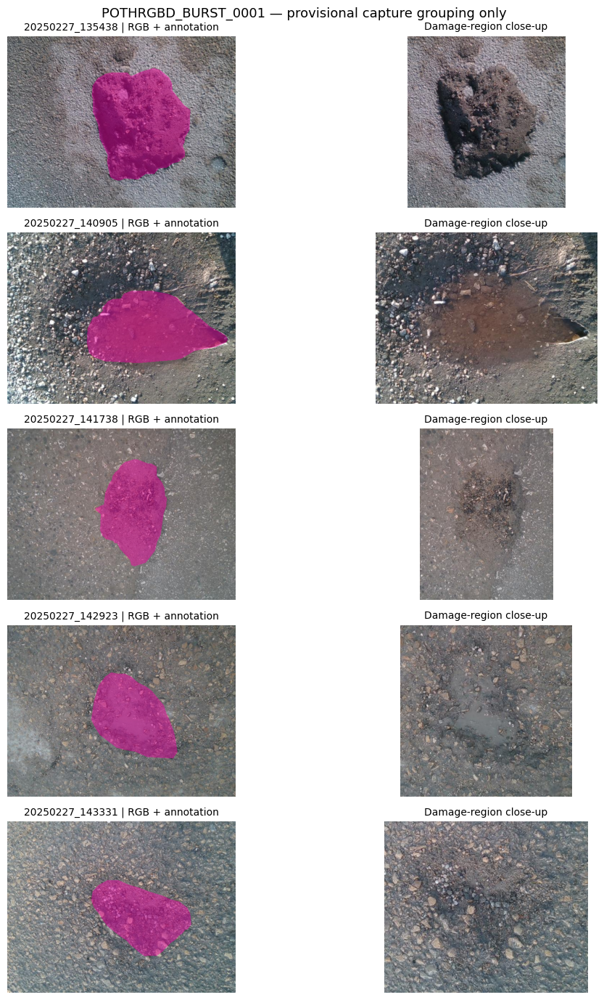

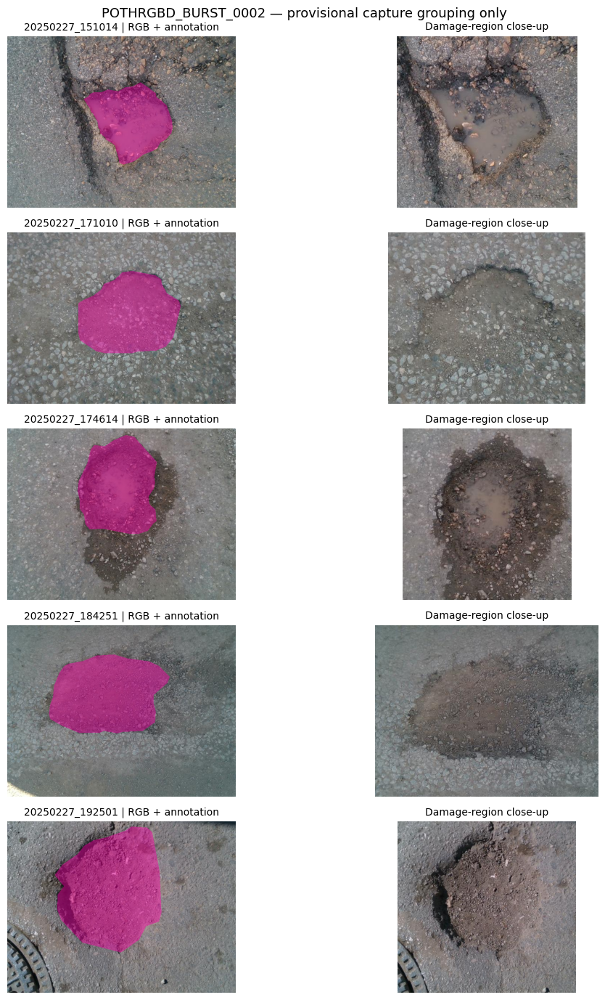

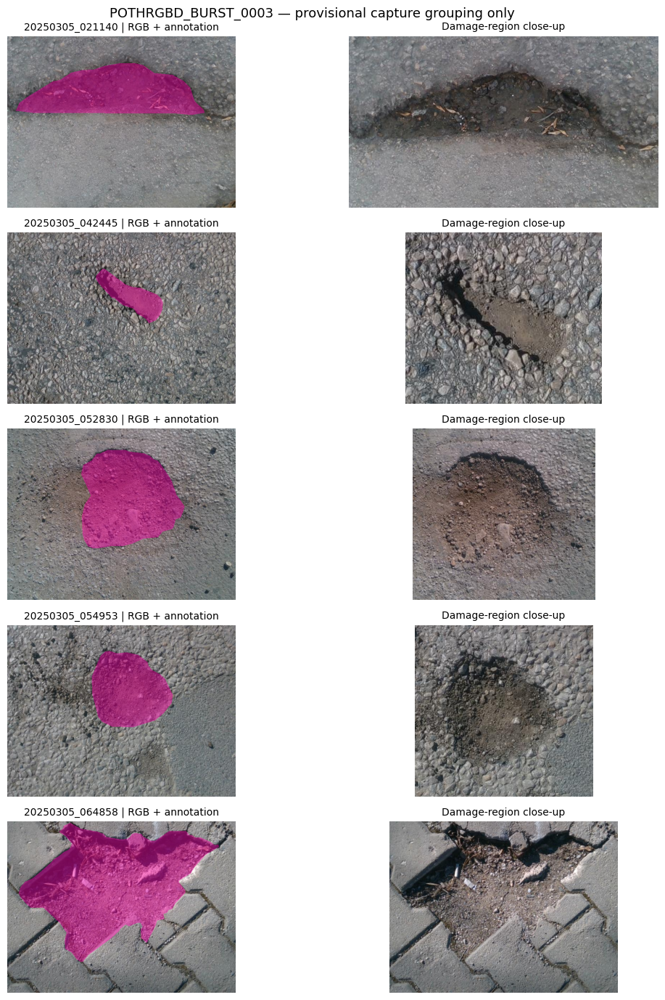

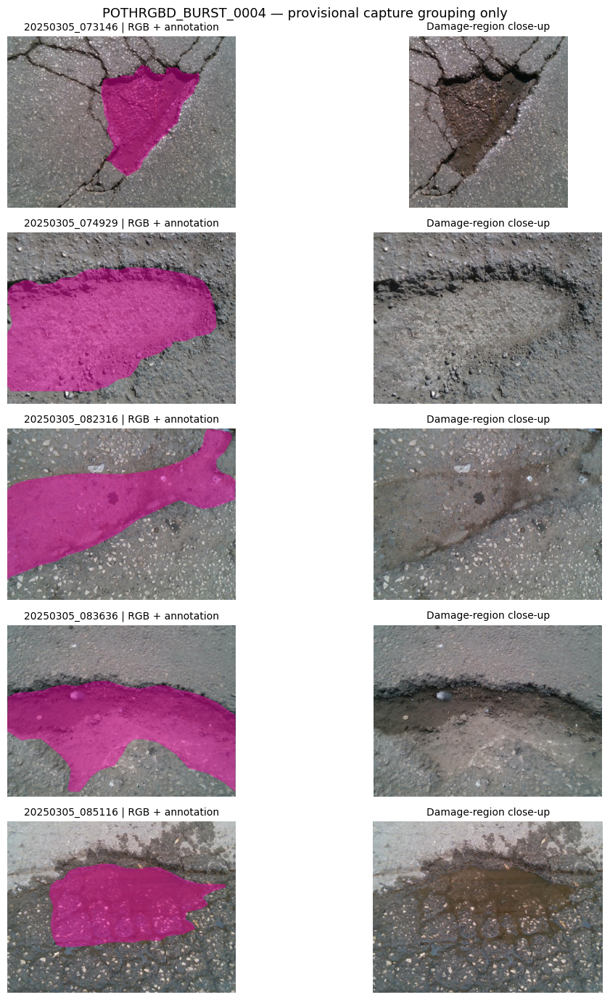

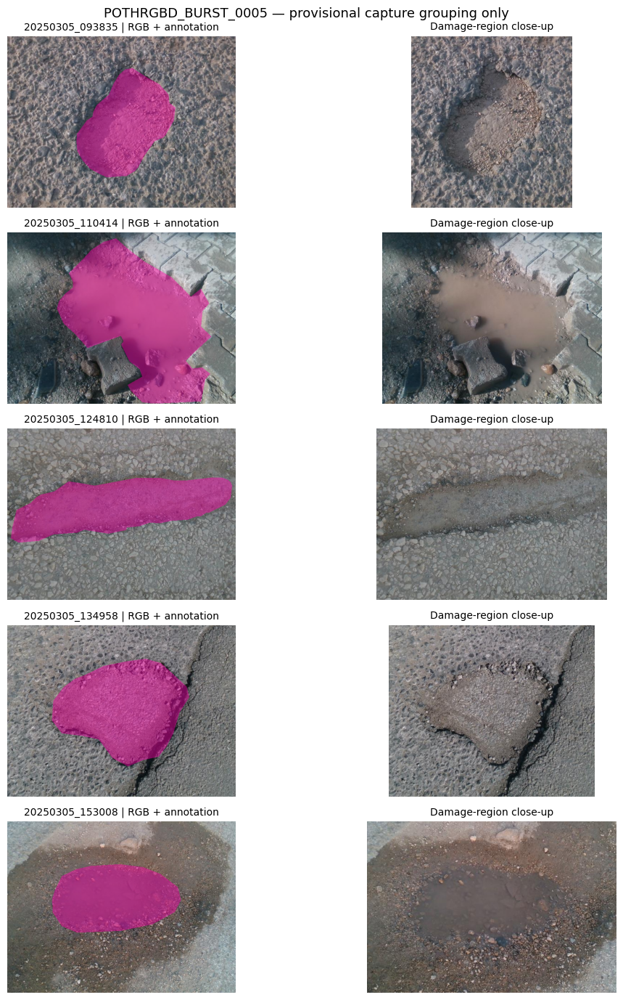


CLOSEST SAMPLED CROSS-BURST PAIRS
20250227_192501 <-> 20250305_064858 | full: 16 | crop: 18
20250227_174614 <-> 20250305_052830 | full: 18 | crop: 32
20250227_171010 <-> 20250305_052830 | full: 20 | crop: 24
20250227_174614 <-> 20250305_085116 | full: 22 | crop: 22
20250305_021140 <-> 20250305_074929 | full: 22 | crop: 34
20250305_042445 <-> 20250305_073146 | full: 24 | crop: 22
20250227_192501 <-> 20250305_085116 | full: 24 | crop: 24
20250305_074929 <-> 20250305_134958 | full: 24 | crop: 26
20250227_171010 <-> 20250305_093835 | full: 24 | crop: 28
20250227_135438 <-> 20250305_110414 | full: 24 | crop: 30
20250227_143331 <-> 20250305_074929 | full: 24 | crop: 30
20250227_141738 <-> 20250305_082316 | full: 24 | crop: 32

Perceptual hashes are only screening aids.
They cannot prove different pothole identities.

C3-02 SECTION 13 — POTHRGBD SCENE DIVERSITY
Strict source triplets: 996
Visualized development samples: 25
Temporal burst contact sheets: 5
Cross-burst image pairs: 250
Indepen

In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 13
# POTHRGBD CAPTURE-DIVERSITY VISUAL SCREENING
# Version 1.0
#
# 5 samples from each of 5 temporal bursts
# No depth arrays | No training | No split assignment
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from PIL import Image, ImageDraw
from scipy.fft import dctn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
import csv

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

PRIOR = PROJECT / (
    "03_splits_manifests/"
    "C3-02_section12_PothRGBD_Groups_"
    "20261020T075921_028539Z"
)

OUT_ROOT = PROJECT / "03_splits_manifests"

SAMPLES_PER_BURST = 5

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

# ------------------------------------------------------------
# 1. VERIFY SECTION 12 MANIFEST AND REPORT
# ------------------------------------------------------------

expected = {}

for line in (
    PRIOR / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, name = line.split(None, 1)
        name = name.strip()
        assert Path(name).name == name
        expected[name] = digest

manifest_path = (
    PRIOR / "pothrgbd_filename_capture_manifest.csv"
)

report_path = PRIOR / "capture_group_readiness.json"

for path in (manifest_path, report_path):
    assert sha256(path) == expected[path.name]

prior = json.loads(
    report_path.read_text(encoding="utf-8")
)

assert prior["strict_triplet_count"] == 996
assert prior["source_scene_independence_verified"] is False
assert prior["train_validation_test_splits_created"] is False

with manifest_path.open(
    newline="", encoding="utf-8"
) as f:
    manifest = list(csv.DictReader(f))

eligible = [
    row for row in manifest
    if row["strict_pair_verified"] == "True"
]

assert len(eligible) == 996

print("Section 12 evidence integrity: PASS")

# ------------------------------------------------------------
# 2. SELECT REPRESENTATIVE IMAGES PER BURST
# ------------------------------------------------------------

groups = defaultdict(list)

for row in eligible:
    groups[row["provisional_burst"]].append(row)

assert len(groups) == 5

selected = []

for burst in sorted(groups):

    candidates = sorted(
        groups[burst],
        key=lambda x: x["sample_id"]
    )

    count = min(
        SAMPLES_PER_BURST,
        len(candidates)
    )

    indices = np.unique(
        np.linspace(
            0, len(candidates)-1,
            count,
            dtype=int
        )
    )

    for index in indices:
        selected.append(
            candidates[int(index)]
        )

    print(
        burst,
        "| total:", len(candidates),
        "| selected:", len(indices)
    )

assert len(selected) == 25

# ------------------------------------------------------------
# 3. SOURCE POLYGON RECONSTRUCTION
# ------------------------------------------------------------

def read_polygon_mask(path, image_size):

    width, height = image_size

    canvas = Image.new(
        "L", image_size, 0
    )

    draw = ImageDraw.Draw(canvas)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        values = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        if not np.isfinite(values).all():
            raise ValueError("Nonfinite annotation")

        coordinates = values[1:]

        if (
            len(coordinates) < 6
            or len(coordinates) % 2 != 0
        ):
            raise ValueError("Unexpected polygon format")

        points = coordinates.reshape(-1, 2)

        if (
            (points < -0.001).any()
            or (points > 1.001).any()
        ):
            raise ValueError("Invalid normalized coordinates")

        points = np.clip(points, 0, 1)

        pixels = [
            (
                round(x * (width-1)),
                round(y * (height-1))
            )
            for x, y in points
        ]

        draw.polygon(pixels, fill=1)
        count += 1

    mask = np.asarray(
        canvas, dtype=bool
    )

    if not mask.any():
        raise ValueError("Empty polygon")

    return mask, count

# ------------------------------------------------------------
# 4. PERCEPTUAL IMAGE HASH FOR SIMILARITY SCREENING
# ------------------------------------------------------------

def phash(array):

    image = Image.fromarray(array).convert("L")

    small = image.resize(
        (64, 64),
        Image.Resampling.LANCZOS
    )

    pixels = np.asarray(
        small, dtype=np.float32
    )

    spectrum = dctn(
        pixels, norm="ortho"
    )[:8, :8].reshape(-1)[1:]

    return spectrum > np.median(spectrum)

# ------------------------------------------------------------
# 5. CREATE VERSIONED OUTPUT DIRECTORY
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = OUT_ROOT / (
    f"C3-02_section13_PothRGBD_SceneQA_{stamp}"
)

OUT.mkdir(exist_ok=False)

records = []
previews = defaultdict(list)
image_hashes = {}

# ------------------------------------------------------------
# 6. INSPECT THE 25 SELECTED RGB + MASK SAMPLES
# ------------------------------------------------------------

for row in selected:

    sid = row["sample_id"]
    burst = row["provisional_burst"]

    rgb_name = row["rgb_filename"]
    label_name = row["label_filename"]

    assert Path(rgb_name).name == rgb_name
    assert Path(label_name).name == label_name
    assert Path(rgb_name).stem == Path(label_name).stem

    rgb_path = DATA / "images" / rgb_name
    label_path = DATA / "labels" / label_name

    assert rgb_path.is_file()
    assert label_path.is_file()

    assert not rgb_path.is_symlink()
    assert not label_path.is_symlink()

    with Image.open(rgb_path) as im:
        rgb = np.asarray(im.convert("RGB"))

    mask, polygon_count = read_polygon_mask(
        label_path,
        (rgb.shape[1], rgb.shape[0])
    )

    ys, xs = np.where(mask)

    x0, x1 = int(xs.min()), int(xs.max()) + 1
    y0, y1 = int(ys.min()), int(ys.max()) + 1

    padding = max(
        35,
        int(
            0.25 * max(
                x1-x0, y1-y0
            )
        )
    )

    xa = max(0, x0-padding)
    xb = min(rgb.shape[1], x1+padding)

    ya = max(0, y0-padding)
    yb = min(rgb.shape[0], y1+padding)

    crop = rgb[ya:yb, xa:xb]

    overlay = rgb.copy()

    overlay[mask] = (
        0.55 * rgb[mask].astype(np.float32)
        + 0.45 * np.array([255, 0, 170])
    ).astype(np.uint8)

    image_hashes[sid] = {
        "full": phash(rgb),
        "crop": phash(crop),
        "burst": burst
    }

    previews[burst].append({
        "sample_id": sid,
        "overlay": overlay,
        "crop": crop
    })

    records.append({
        "sample_id": sid,
        "capture_day": row["capture_day_group"],
        "provisional_burst": burst,
        "rgb_filename": rgb_name,
        "label_filename": label_name,
        "mask_fraction": float(mask.mean()),
        "polygon_count": polygon_count,
        "rgb_sha256": sha256(rgb_path),
        "label_sha256": sha256(label_path),
        "physical_scene_identity": "UNVERIFIED",
        "scientific_training_approved": False,
    })

# ------------------------------------------------------------
# 7. SAVE FIVE CONTACT SHEETS
# ------------------------------------------------------------

for burst, items in sorted(previews.items()):

    fig, axes = plt.subplots(
        len(items), 2,
        figsize=(12, 2.8 * len(items))
    )

    if len(items) == 1:
        axes = axes[None, :]

    for index, item in enumerate(items):

        axes[index, 0].imshow(
            item["overlay"]
        )

        axes[index, 0].set_title(
            item["sample_id"]
            + " | RGB + annotation",
            fontsize=10
        )

        axes[index, 1].imshow(
            item["crop"]
        )

        axes[index, 1].set_title(
            "Damage-region close-up",
            fontsize=10
        )

        axes[index, 0].axis("off")
        axes[index, 1].axis("off")

    fig.suptitle(
        burst
        + " — provisional capture grouping only",
        fontsize=13
    )

    fig.tight_layout()

    fig.savefig(
        OUT / f"{burst}_contact_sheet.png",
        dpi=125,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 8. CROSS-BURST SIMILARITY SCREEN
# ------------------------------------------------------------

ids = sorted(image_hashes)

pairs = []

for i in range(len(ids)):
    for j in range(i+1, len(ids)):

        a = ids[i]
        b = ids[j]

        info_a = image_hashes[a]
        info_b = image_hashes[b]

        if info_a["burst"] == info_b["burst"]:
            continue

        full_distance = int(
            np.count_nonzero(
                info_a["full"] != info_b["full"]
            )
        )

        crop_distance = int(
            np.count_nonzero(
                info_a["crop"] != info_b["crop"]
            )
        )

        pairs.append({
            "sample_a": a,
            "sample_b": b,
            "burst_a": info_a["burst"],
            "burst_b": info_b["burst"],
            "full_phash_distance": full_distance,
            "crop_phash_distance": crop_distance,
        })

pairs.sort(
    key=lambda x: (
        x["full_phash_distance"],
        x["crop_phash_distance"]
    )
)

print("\nCLOSEST SAMPLED CROSS-BURST PAIRS")

for item in pairs[:12]:

    print(
        item["sample_a"],
        "<->",
        item["sample_b"],
        "| full:", item["full_phash_distance"],
        "| crop:", item["crop_phash_distance"]
    )

print(
    "\nPerceptual hashes are only screening aids."
)
print(
    "They cannot prove different pothole identities."
)

# ------------------------------------------------------------
# 9. SAVE PROVENANCE AND GROUP-REVIEW RESULTS
# ------------------------------------------------------------

manifest_output = OUT / "scene_review_samples.csv"

pd.DataFrame(records).to_csv(
    manifest_output, index=False
)

pairs_output = OUT / "cross_burst_similarity.csv"

pd.DataFrame(pairs).to_csv(
    pairs_output, index=False
)

report = {
    "milestone": "C3-02",
    "section": "13_supplementary",
    "version": "1.0",
    "source_section12": PRIOR.name,
    "source_manifest_sha256": sha256(
        manifest_path
    ),
    "sampled_frames": len(records),
    "sampling_per_burst": SAMPLES_PER_BURST,
    "burst_source_counts": prior[
        "provisional_burst_counts"
    ],
    "contact_sheets_saved": len(previews),
    "cross_burst_pairs_screened": len(pairs),
    "group_identity_verified": False,
    "frozen_benchmark_overlap_verified": False,
    "independent_train_validation_groups": False,
    "training_splits_assigned": False,
    "depth_payloads_read": False,
    "metric_depth_units_verified": False,
    "model_training_authorized": False,
    "purpose": (
        "Human visual screening of 25 representative "
        "images across five provisional temporal bursts. "
        "Does not establish physical-scene independence."
    ),
}

report_output = OUT / "scene_diversity_report.json"

report_output.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. EXPORT CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.iterdir()):

    if file.is_file():
        lines.append(
            f"{sha256(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 13 — POTHRGBD SCENE DIVERSITY")
print("=" * 65)

print("Strict source triplets:", len(eligible))
print("Visualized development samples:", len(records))
print("Temporal burst contact sheets:", len(previews))
print("Cross-burst image pairs:", len(pairs))
print("Independent physical scenes verified: NO")
print("Metric training authorized: NO")
print("Saved:", OUT)

print("=" * 65)


Sections 12 and 13 source evidence: PASS
20250227_135438 | POTHRGBD_BURST_0001 | DIAGNOSTIC_PASS | coverage: 1.0 | signal/road: 4.14 | flags: []
20250227_140905 | POTHRGBD_BURST_0001 | DIAGNOSTIC_FAIL | coverage: 1.0 | signal/road: 1.07 | flags: ['LOW_GEOMETRY_SIGNAL', 'WEAK_SPATIAL_HOLDOUT']
20250227_141738 | POTHRGBD_BURST_0001 | DIAGNOSTIC_PASS | coverage: 1.0 | signal/road: 3.56 | flags: []
20250227_142923 | POTHRGBD_BURST_0001 | DIAGNOSTIC_FAIL | coverage: 1.0 | signal/road: 2.22 | flags: ['WEAK_SPATIAL_HOLDOUT']
20250227_143331 | POTHRGBD_BURST_0001 | DIAGNOSTIC_FAIL | coverage: 1.0 | signal/road: 2.42 | flags: ['WEAK_SPATIAL_HOLDOUT']
20250227_151014 | POTHRGBD_BURST_0002 | DIAGNOSTIC_FAIL | coverage: 0.997 | signal/road: 1.49 | flags: ['LOW_GEOMETRY_SIGNAL', 'WEAK_SPATIAL_HOLDOUT']
20250227_171010 | POTHRGBD_BURST_0002 | DIAGNOSTIC_FAIL | coverage: 1.0 | signal/road: 2.21 | flags: ['WEAK_SPATIAL_HOLDOUT']
20250227_174614 | POTHRGBD_BURST_0002 | DIAGNOSTIC_FAIL | coverage: 1.0 |

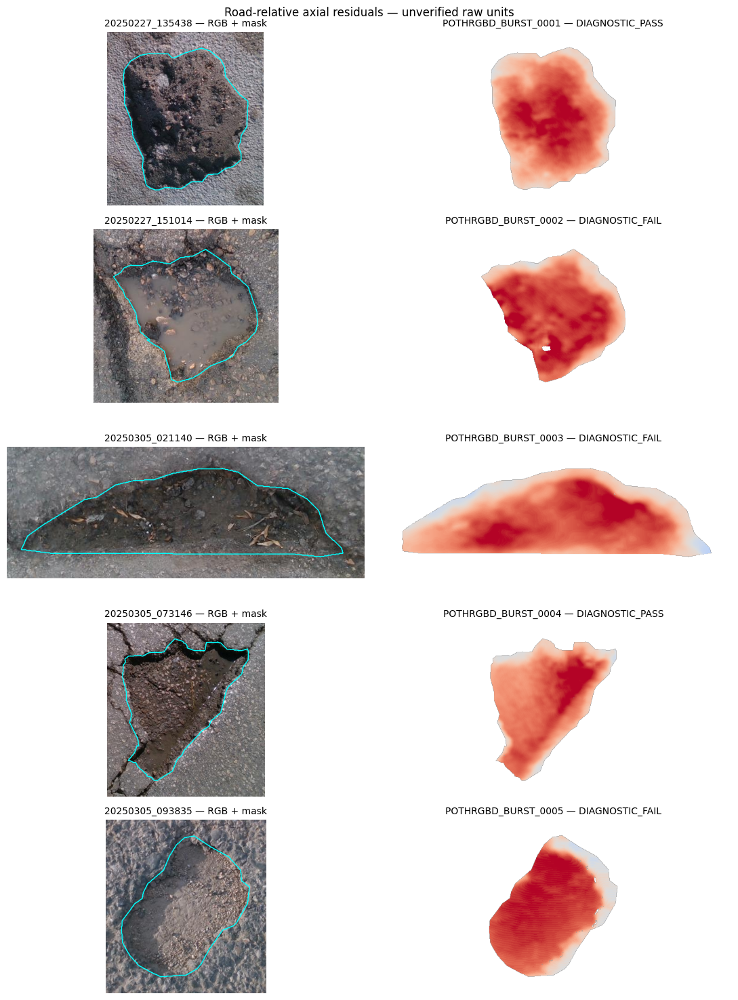

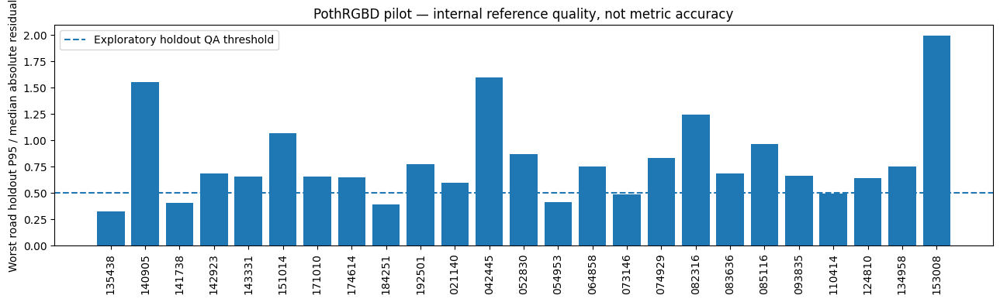


C3-02 SECTION 14 — POTHRGBD TARGET PILOT
Samples attempted: 25
Diagnostic statuses: {'DIAGNOSTIC_PASS': 6, 'DIAGNOSTIC_FAIL': 19}
Saved provisional NPZ files: 6
Independent validation performed: NO
Physical metric targets certified: NO
Full CRDL training performed: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z


In [ ]:

# ============================================================
# CRDL COMPONENT 3 — C3-02 SECTION 14
# 25-SAMPLE POTHRGBD QUALITY-GATED GEOMETRY PILOT
# Version 1.0
#
# NONMETRIC DIAGNOSTICS ONLY
# NO MODEL TRAINING / NO SPLITS / NO MM CONVERSION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, csv

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)
S13 = PROJECT / (
    "03_splits_manifests/"
    "C3-02_section13_PothRGBD_SceneQA_20261020T080428_956126Z"
)
S12 = PROJECT / (
    "03_splits_manifests/"
    "C3-02_section12_PothRGBD_Groups_20261020T075921_028539Z"
)
OUTROOT = PROJECT / "04_geometry_targets"

for d in (S13, S12, OUTROOT):
    assert d.is_dir(), d

# ------------------------------------------------------------
# 1. VERIFY BOTH SOURCE MANIFESTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def verified(folder, names):
    checks = {}
    for line in (folder / "checksums.sha256").read_text().splitlines():
        if line.strip():
            digest, name = line.split(None, 1)
            name = name.strip()
            assert not Path(name).is_absolute()
            assert ".." not in Path(name).parts
            checks[name] = digest

    for name in names:
        assert name in checks
        assert sha(folder / name) == checks[name], (
            f"Source evidence changed: {name}"
        )

verified(S13, [
    "scene_diversity_report.json",
    "scene_review_samples.csv"
])
verified(S12, [
    "capture_group_readiness.json",
    "pothrgbd_filename_capture_manifest.csv"
])

source = json.loads(
    (S13 / "scene_diversity_report.json").read_text()
)
source12 = json.loads(
    (S12 / "capture_group_readiness.json").read_text()
)

assert source["sampled_frames"] == 25
assert source["training_splits_assigned"] is False
assert source12["strict_triplet_count"] == 996
assert source12["train_validation_test_splits_created"] is False

with (S13 / "scene_review_samples.csv").open(newline="") as f:
    selected = list(csv.DictReader(f))

with (
    S12 / "pothrgbd_filename_capture_manifest.csv"
).open(newline="") as f:
    indexed = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

assert len(selected) == 25
assert len({r["sample_id"] for r in selected}) == 25

for item in selected:
    original = indexed[item["sample_id"]]
    assert original["strict_pair_verified"] == "True"
    assert original["rgb_filename"] == item["rgb_filename"]
    assert original["label_filename"] == item["label_filename"]
    assert original["provisional_burst"] == item["provisional_burst"]

print("Sections 12 and 13 source evidence: PASS")

# ------------------------------------------------------------
# 2. FIX EXPLORATORY QA CONFIGURATION
# ------------------------------------------------------------

CFG = {
    "seed": 20261020,
    "ring_min_px": 8,
    "ring_max_px": 55,
    "max_ring_samples": 18000,
    "irls_iterations": 10,
    "min_support_pixels": 2500,
    "min_sector_test_pixels": 200,
    "min_valid_target_fraction": 0.90,
    "min_positive_fraction": 0.75,
    "min_signal_to_road_p95": 1.50,
    "max_worst_holdout_to_signal": 0.50,
    "sensor_ratio_min": 0.40,
    "sensor_ratio_max": 2.50,
}

# Exploratory engineering thresholds only.
# These are not calibrated severity/reliability thresholds.

# ------------------------------------------------------------
# 3. RECONSTRUCT YOLO SEGMENTATION
# ------------------------------------------------------------

def polygon_mask(path, size):
    w, h = size
    canvas = Image.new("L", size, 0)
    draw = ImageDraw.Draw(canvas)
    count = 0

    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue

        values = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        if not np.isfinite(values).all():
            raise ValueError("Invalid polygon values")

        if (
            values[0] != 0
            or len(values) < 7
            or len(values[1:]) % 2
        ):
            raise ValueError("Unexpected YOLO annotation")

        points = values[1:].reshape(-1, 2)

        if (points < -0.001).any() or (points > 1.001).any():
            raise ValueError("Invalid normalized coordinates")

        points = np.clip(points, 0, 1)

        draw.polygon(
            [
                (
                    round(x * (w - 1)),
                    round(y * (h - 1))
                )
                for x, y in points
            ],
            fill=1
        )
        count += 1

    return np.asarray(canvas, dtype=bool), count

# ------------------------------------------------------------
# 4. ROBUST INVERSE-DEPTH REFERENCE FIT
# ------------------------------------------------------------

def design_matrix(xs, ys, w, h):
    return np.column_stack([
        (xs - (w-1)/2) / w,
        (ys - (h-1)/2) / h,
        np.ones(len(xs))
    ])

def robust_fit(A, target):
    beta = np.linalg.lstsq(A, target, rcond=None)[0]

    for _ in range(CFG["irls_iterations"]):
        errors = target - A @ beta
        median = np.median(errors)
        mad = 1.4826 * np.median(
            np.abs(errors - median)
        )

        threshold = max(1.5 * mad, 1e-6)

        weights = np.sqrt(
            np.minimum(
                1.0,
                threshold / np.maximum(
                    np.abs(errors - median),
                    1e-12
                )
            )
        )

        updated = np.linalg.lstsq(
            A * weights[:, None],
            target * weights,
            rcond=None
        )[0]

        if np.max(np.abs(updated - beta)) < 1e-9:
            beta = updated
            break

        beta = updated

    return beta

# ------------------------------------------------------------
# 5. CREATE VERSIONED OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTROOT / f"C3-02_section14_PothRGBD_PILOT_{stamp}"
OUT.mkdir(exist_ok=False)

NPZDIR = OUT / "diagnostic_pass_npz"
NPZDIR.mkdir()

results = []
previews = []

# ------------------------------------------------------------
# 6. PROCESS ALL 25 APPROVED AUDIT EXAMPLES
# ------------------------------------------------------------

for item in selected:

    sid = item["sample_id"]
    burst = item["provisional_burst"]

    result = {
        "sample_id": sid,
        "burst": burst,
        "capture_day": item["capture_day"],
        "status": "ERROR",
        "flags": [],
        "npz": None,
        "training_approved": False,
        "metric_units_verified": False,
    }

    try:
        rgb_path = ROOT / "images" / item["rgb_filename"]
        label_path = ROOT / "labels" / item["label_filename"]
        depth_path = ROOT / "depths" / f"{sid}_depth.npy"

        for path in (rgb_path, label_path, depth_path):
            if not path.is_file() or path.is_symlink():
                raise FileNotFoundError(path)

        if sha(rgb_path) != item["rgb_sha256"]:
            raise RuntimeError("RGB checksum mismatch")

        if sha(label_path) != item["label_sha256"]:
            raise RuntimeError("Label checksum mismatch")

        with Image.open(rgb_path) as im:
            rgb = np.asarray(im.convert("RGB"))

        depth = np.load(
            depth_path,
            allow_pickle=False
        )

        if (
            depth.dtype != np.uint16
            or depth.ndim != 2
            or depth.shape != rgb.shape[:2]
        ):
            raise ValueError("Unexpected RGB/depth dimensions")

        h, w = depth.shape

        mask, polygons = polygon_mask(
            label_path, (w, h)
        )

        if not mask.any():
            raise ValueError("Empty damage mask")

        depth_valid = np.isfinite(depth) & (depth > 0)

        # Healthy-road annulus outside the annotation.
        distance = distance_transform_edt(~mask)

        ring = (
            depth_valid
            & (distance >= CFG["ring_min_px"])
            & (distance <= CFG["ring_max_px"])
        )

        ry, rx = np.nonzero(ring)

        if len(ry) < CFG["min_support_pixels"]:
            raise ValueError("Insufficient surrounding road")

        rng = np.random.default_rng(
            CFG["seed"] + int(sid[-6:])
        )

        choice = rng.choice(
            len(ry),
            size=min(
                CFG["max_ring_samples"], len(ry)
            ),
            replace=False
        )

        ry, rx = ry[choice], rx[choice]

        z = depth[ry, rx].astype(np.float64)

        low, high = np.quantile(z, [0.001, 0.999])

        accepted = (z >= low) & (z <= high)
        ry, rx, z = ry[accepted], rx[accepted], z[accepted]

        A = design_matrix(rx, ry, w, h)

        # 1000 is numerical conditioning, not mm conversion.
        inverse_z = 1000.0 / z

        beta = robust_fit(A, inverse_z)

        fitted = A @ beta

        if (fitted <= 0).any():
            raise ValueError("Invalid reference depth")

        road_p95 = float(
            np.percentile(
                np.abs(z - 1000.0 / fitted),
                95
            )
        )

        # ----------------------------------------------------
        # 7. FOUR-SECTOR ROAD-SURFACE HOLDOUT
        # ----------------------------------------------------

        cy, cx = np.mean(np.nonzero(mask), axis=1)

        angles = np.mod(
            np.arctan2(ry-cy, rx-cx) + 2*np.pi,
            2*np.pi
        )

        sectors = np.minimum(
            (angles / (np.pi / 2)).astype(int), 3
        )

        holdout = []

        for sector in range(4):

            test = sectors == sector
            train = ~test

            if (
                test.sum() < CFG["min_sector_test_pixels"]
                or train.sum() < CFG["min_support_pixels"]
            ):
                holdout.append(None)
                continue

            cv_beta = robust_fit(
                A[train],
                inverse_z[train]
            )

            predicted_inverse = A[test] @ cv_beta

            if (predicted_inverse <= 0).any():
                holdout.append(None)
                continue

            error = (
                z[test] - 1000.0 / predicted_inverse
            )

            holdout.append(
                float(
                    np.percentile(
                        np.abs(error), 95
                    )
                )
            )

        # ----------------------------------------------------
        # 8. GENERATE VALIDITY-AWARE AXIAL RESIDUAL
        # ----------------------------------------------------

        yy, xx = np.nonzero(mask & depth_valid)

        predicted_inverse = (
            design_matrix(xx, yy, w, h) @ beta
        )

        reference = np.full(
            len(predicted_inverse),
            np.nan,
            dtype=np.float64
        )

        okay = predicted_inverse > 0

        reference[okay] = (
            1000.0 / predicted_inverse[okay]
        )

        observed = depth[
            yy, xx
        ].astype(np.float64)

        # Reject grossly implausible raw sensor returns.
        # Ratio limits are provisional, not physical units.
        plausible = (
            okay
            & (observed >= CFG["sensor_ratio_min"] * reference)
            & (observed <= CFG["sensor_ratio_max"] * reference)
        )

        residual = np.full(
            (h, w),
            np.nan,
            dtype=np.float32
        )

        residual[
            yy[plausible],
            xx[plausible]
        ] = (
            observed[plausible]
            - reference[plausible]
        ).astype(np.float32)

        valid = np.isfinite(residual)
        values = residual[valid]

        if values.size < 100:
            raise ValueError("Too few usable target pixels")

        coverage = float(
            valid.sum() / mask.sum()
        )

        signed_median = float(np.median(values))

        magnitude = float(
            np.median(np.abs(values))
        )

        positive_fraction = float(
            np.mean(values > 0)
        )

        signal_ratio = float(
            magnitude / max(road_p95, 1e-9)
        )

        worst_holdout = (
            max(holdout)
            if all(v is not None for v in holdout)
            else None
        )

        holdout_ratio = (
            float(
                worst_holdout / max(magnitude, 1e-9)
            )
            if worst_holdout is not None
            else None
        )

        # ----------------------------------------------------
        # 9. APPLY EXPLORATORY INTERNAL QA
        # ----------------------------------------------------

        flags = []

        if coverage < CFG["min_valid_target_fraction"]:
            flags.append("LOW_VALID_GEOMETRY")

        if positive_fraction < CFG["min_positive_fraction"]:
            flags.append("AMBIGUOUS_RESIDUAL_SIGN")

        if signal_ratio < CFG["min_signal_to_road_p95"]:
            flags.append("LOW_GEOMETRY_SIGNAL")

        if worst_holdout is None:
            flags.append("INCOMPLETE_SPATIAL_HOLDOUT")

        elif holdout_ratio > CFG["max_worst_holdout_to_signal"]:
            flags.append("WEAK_SPATIAL_HOLDOUT")

        status = (
            "DIAGNOSTIC_PASS"
            if not flags
            else "DIAGNOSTIC_FAIL"
        )

        result.update({
            "status": status,
            "flags": flags,
            "annotation_polygons": polygons,
            "mask_pixels": int(mask.sum()),
            "valid_target_pixels": int(valid.sum()),
            "coverage": coverage,
            "road_p95_raw": road_p95,
            "holdout_p95_raw_by_sector": holdout,
            "worst_holdout_raw": worst_holdout,
            "signed_median_raw": signed_median,
            "median_abs_raw": magnitude,
            "positive_fraction": positive_fraction,
            "signal_to_road_p95": signal_ratio,
            "holdout_to_signal": holdout_ratio,
            "rgb_sha256": item["rgb_sha256"],
            "label_sha256": item["label_sha256"],
            "depth_sha256": sha(depth_path),
        })

        # ----------------------------------------------------
        # 10. EXPORT DIAGNOSTIC PASSES
        # ----------------------------------------------------

        if status == "DIAGNOSTIC_PASS":

            output = NPZDIR / f"{sid}_axial_raw.npz"

            np.savez_compressed(
                output,
                signed_axial_raw=residual,
                damage_mask=mask.astype(np.uint8),
                valid_target_mask=valid.astype(np.uint8),
                inv_depth_plane_beta=beta,
            )

            with np.load(
                output, allow_pickle=False
            ) as saved:

                assert np.array_equal(
                    np.isfinite(saved["signed_axial_raw"]),
                    saved["valid_target_mask"].astype(bool)
                )

            result["npz"] = str(
                output.relative_to(OUT)
            )

        # One representative visualization per burst.
        if not any(
            entry["burst"] == burst
            for entry in previews
        ):

            ys, xs = np.where(mask)
            pad = 35

            y0 = max(0, int(ys.min()) - pad)
            y1 = min(h, int(ys.max()) + pad + 1)

            x0 = max(0, int(xs.min()) - pad)
            x1 = min(w, int(xs.max()) + pad + 1)

            previews.append({
                "burst": burst,
                "sample": sid,
                "rgb": rgb[y0:y1, x0:x1],
                "mask": mask[y0:y1, x0:x1],
                "residual": residual[y0:y1, x0:x1],
                "status": status,
            })

    except Exception as exc:

        result["status"] = "ERROR"
        result["flags"] = [
            f"{type(exc).__name__}: {exc}"
        ]

    results.append(result)

    print(
        sid,
        "|", burst,
        "|", result["status"],
        "| coverage:",
        round(result.get("coverage", 0), 3),
        "| signal/road:",
        round(result.get("signal_to_road_p95", 0), 2),
        "| flags:", result["flags"]
    )

# ------------------------------------------------------------
# 11. SAVE COMPLETE MANIFEST AND RESEARCH REPORT
# ------------------------------------------------------------

counts = Counter(
    result["status"] for result in results
)

manifest_file = OUT / "pilot_target_manifest.csv"

fields = [
    "sample_id", "burst", "capture_day",
    "status", "flags", "coverage",
    "road_p95_raw", "worst_holdout_raw",
    "signed_median_raw", "median_abs_raw",
    "positive_fraction", "signal_to_road_p95",
    "holdout_to_signal", "npz",
    "rgb_sha256", "label_sha256", "depth_sha256",
    "training_approved", "metric_units_verified"
]

with manifest_file.open(
    "w", newline="", encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fields,
        extrasaction="ignore"
    )

    writer.writeheader()

    for r in results:
        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in r.items()
        })

report = {
    "milestone": "C3-02",
    "section": 14,
    "version": "1.0",
    "generated_utc": stamp,
    "source_section13_sha256": sha(
        S13 / "scene_diversity_report.json"
    ),
    "source_section12_sha256": sha(
        S12 / "capture_group_readiness.json"
    ),
    "configuration": CFG,
    "status_counts": dict(counts),
    "records": results,
    "independent_physical_scenes_verified": False,
    "train_validation_test_split_created": False,
    "metric_units_verified": False,
    "target_represents_camera_axis_residual": True,
    "perpendicular_road_depth_verified": False,
    "thresholds_are_exploratory": True,
    "diagnostic_npzs_training_approved": False,
    "metric_model_training_authorized": False,
    "independent_model_validation_authorized": False,
}

report_file = OUT / "pilot_quality_report.json"

report_file.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 12. VISUALIZE ONE EXAMPLE PER BURST
# ------------------------------------------------------------

if previews:

    fig, axes = plt.subplots(
        len(previews), 2,
        figsize=(11, 3 * len(previews)),
        squeeze=False
    )

    for i, entry in enumerate(previews):

        axes[i, 0].imshow(entry["rgb"])

        axes[i, 0].contour(
            entry["mask"],
            levels=[0.5],
            colors="cyan",
            linewidths=1
        )

        axes[i, 0].set_title(
            entry["sample"] + " — RGB + mask",
            fontsize=10
        )

        values = entry["residual"][
            np.isfinite(entry["residual"])
        ]

        limit = (
            max(float(np.percentile(np.abs(values), 95)), 1)
            if values.size
            else 1
        )

        axes[i, 1].imshow(
            np.ma.masked_invalid(entry["residual"]),
            cmap="coolwarm",
            vmin=-limit,
            vmax=limit
        )

        axes[i, 1].set_title(
            entry["burst"] + " — " + entry["status"],
            fontsize=10
        )

        for ax in axes[i]:
            ax.axis("off")

    fig.suptitle(
        "Road-relative axial residuals — "
        "unverified raw units"
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "five_burst_target_previews.png",
        dpi=135,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 13. DIAGNOSTIC QUALITY CHART
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 4))

ratios = [
    r.get("holdout_to_signal", np.nan)
    for r in results
]

ratios = [
    np.nan if value is None else value
    for value in ratios
]

ax.bar(
    range(len(results)),
    ratios
)

ax.axhline(
    CFG["max_worst_holdout_to_signal"],
    linestyle="--",
    label="Exploratory holdout QA threshold"
)

ax.set_xticks(
    range(len(results)),
    [
        r["sample_id"][-6:]
        for r in results
    ],
    rotation=90
)

ax.set_ylabel(
    "Worst road holdout P95 / median absolute residual"
)

ax.set_title(
    "PothRGBD pilot — internal reference quality, "
    "not metric accuracy"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "pilot_holdout_ratios.png",
    dpi=135
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. COMPLETE ARTIFACT CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.rglob("*")):

    if file.is_file() and file.name != "checksums.sha256":

        lines.append(
            f"{sha(file)}  "
            f"{file.relative_to(OUT).as_posix()}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 15. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 14 — POTHRGBD TARGET PILOT")
print("=" * 65)

print("Samples attempted:", len(results))
print("Diagnostic statuses:", dict(counts))

print(
    "Saved provisional NPZ files:",
    len(list(NPZDIR.glob("*.npz")))
)

print("Independent validation performed: NO")
print("Physical metric targets certified: NO")
print("Full CRDL training performed: NO")
print("Saved:", OUT)

print("=" * 65)


Section 14 and source selection integrity: PASS
20250227_135438 | COMPARED | curved better: False | reproduction difference: 0.0
20250227_140905 | COMPARED | curved better: True | reproduction difference: 0.0
20250227_141738 | COMPARED | curved better: False | reproduction difference: 0.0
20250227_142923 | COMPARED | curved better: True | reproduction difference: 0.0
20250227_143331 | COMPARED | curved better: False | reproduction difference: 0.0
20250227_151014 | COMPARED | curved better: True | reproduction difference: 0.0
20250227_171010 | COMPARED | curved better: False | reproduction difference: 0.0
20250227_174614 | COMPARED | curved better: False | reproduction difference: 0.0
20250227_184251 | COMPARED | curved better: True | reproduction difference: 0.0
20250227_192501 | COMPARED | curved better: True | reproduction difference: 0.0
20250305_021140 | COMPARED | curved better: False | reproduction difference: 0.0
20250305_042445 | COMPARED | curved better: True | reproduction di

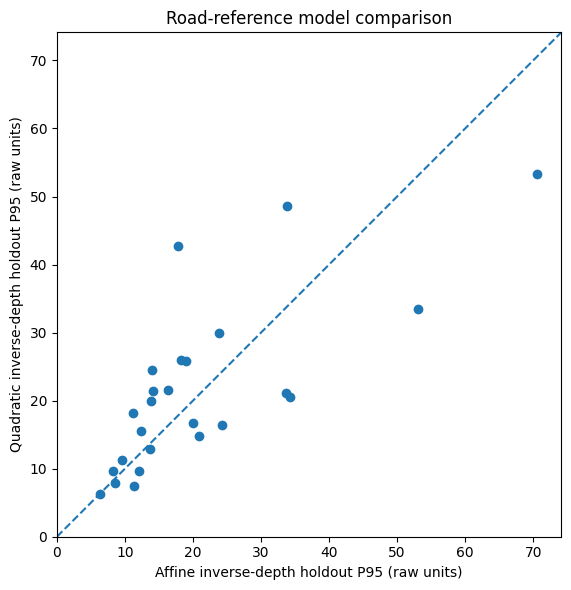


C3-02 SECTION 15 — ROAD REFERENCE MODEL ABLATION
Status: {'COMPARED': 25}
Comparable samples: 25
Quadratic lower worst-sector error: 12
Median relative holdout improvement: -0.17894385535803825
Original quality gates changed: NO
Training targets exported: NO
Metric supervision authorized: NO
Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-02_section15_Reference_Model_Ablation_20261020T082107_871107Z


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import hashlib, json, csv, re

# ============================================================
# C3-02 SECTION 15 — REFERENCE MODEL ADEQUACY
# Read-only inputs | Same 25 development samples
# No metric labels | No splits | No ML training
# ============================================================

PROJECT = Path(
    "/content/drive/MyDrive/crdl_experiments/component3_fresh_v1"
)
ROOT = Path(
    "/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main"
)
S14 = PROJECT / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)
S13 = PROJECT / (
    "03_splits_manifests/"
    "C3-02_section13_PothRGBD_SceneQA_20261020T080428_956126Z"
)
OUTROOT = PROJECT / "02_dataset_audits"

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

# ------------------------------------------------------------
# 1. VERIFY FROZEN SOURCE REPORTS
# ------------------------------------------------------------

def verify(folder, filenames):
    hashes = {}
    for line in (folder / "checksums.sha256").read_text().splitlines():
        if line.strip():
            digest, relative = line.split(None, 1)
            relative = relative.strip()
            p = Path(relative)
            assert not p.is_absolute() and ".." not in p.parts
            hashes[relative] = digest

    for fname in filenames:
        assert fname in hashes
        assert sha(folder / fname) == hashes[fname]

verify(S14, [
    "pilot_quality_report.json",
    "pilot_target_manifest.csv"
])
verify(S13, [
    "scene_review_samples.csv",
    "scene_diversity_report.json"
])

source = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

assert source["section"] == 14
assert len(source["records"]) == 25
assert source["metric_model_training_authorized"] is False
assert source["status_counts"] == {
    "DIAGNOSTIC_PASS": 6,
    "DIAGNOSTIC_FAIL": 19
}

cfg = source["configuration"]

with (S13 / "scene_review_samples.csv").open(
    newline=""
) as f:
    sample = {
        r["sample_id"]: r
        for r in csv.DictReader(f)
    }

assert set(sample) == {
    r["sample_id"] for r in source["records"]
}

print("Section 14 and source selection integrity: PASS")

# ------------------------------------------------------------
# 2. RECREATE EXACT SOURCE POLYGON MASKS
# ------------------------------------------------------------

def mask_from_yolo(path, w, h):
    canvas = Image.new("L", (w, h), 0)
    draw = ImageDraw.Draw(canvas)
    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        vals = np.array([
            float(x) for x in line.split()
        ])

        assert np.isfinite(vals).all()
        assert vals[0] == 0
        assert len(vals) >= 7
        assert (len(vals)-1) % 2 == 0

        points = vals[1:].reshape(-1, 2)

        assert np.all(
            (points >= -0.001) & (points <= 1.001)
        )

        points = np.clip(points, 0, 1)

        draw.polygon([
            (round(x*(w-1)), round(y*(h-1)))
            for x, y in points
        ], fill=1)

        count += 1

    assert count > 0
    return np.asarray(canvas, dtype=bool)

# ------------------------------------------------------------
# 3. DEFINE BOTH ROAD REFERENCE MODELS
# ------------------------------------------------------------

def basis(xx, yy, w, h, quadratic=False):
    x = (xx-(w-1)/2) / w
    y = (yy-(h-1)/2) / h

    if quadratic:
        return np.column_stack([
            x, y, x*x, x*y, y*y,
            np.ones(len(xx))
        ])

    return np.column_stack([
        x, y, np.ones(len(xx))
    ])

# Same robust fitting method and iteration
# configuration as Section 14.

def irls(A, b):
    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for i in range(cfg["irls_iterations"]):
        errors = b - A @ beta
        m = np.median(errors)

        mad = 1.4826 * np.median(
            np.abs(errors-m)
        )

        cutoff = max(1.5*mad, 1e-6)

        s = np.sqrt(np.minimum(
            1.0,
            cutoff / np.maximum(
                np.abs(errors-m), 1e-12
            )
        ))

        next_beta = np.linalg.lstsq(
            A*s[:, None],
            b*s,
            rcond=None
        )[0]

        if np.max(
            np.abs(next_beta-beta)
        ) < 1e-9:
            beta = next_beta
            break

        beta = next_beta

    return beta

# ------------------------------------------------------------
# 4. MODEL ASSESSMENT ON THE SAME ROAD SUPPORT
# ------------------------------------------------------------

def model_quality(A, inv, z, sectors,
                  inside_A, observed):

    coef = irls(A, inv)
    fit = A @ coef

    if np.any(fit <= 0):
        return {"status": "NONPOSITIVE_ROAD_REFERENCE"}

    in_sample_p95 = float(np.percentile(
        np.abs(z-1000.0/fit), 95
    ))

    fold_errors = []

    for k in range(4):
        test = sectors == k
        train = ~test

        if (
            test.sum() < cfg["min_sector_test_pixels"]
            or train.sum() < cfg["min_support_pixels"]
        ):
            return {
                "status": "INCOMPLETE_SECTOR_SUPPORT"
            }

        cv = irls(
            A[train],
            inv[train]
        )

        pred = A[test] @ cv

        if np.any(pred <= 0):
            return {
                "status": "NONPOSITIVE_HOLDOUT_REFERENCE"
            }

        fold_errors.append(float(
            np.percentile(
                np.abs(z[test]-1000.0/pred), 95
            )
        ))

    pred_inside = inside_A @ coef

    if np.any(pred_inside <= 0):
        return {
            "status": "NONPOSITIVE_DAMAGE_REFERENCE"
        }

    expected = 1000.0 / pred_inside
    signed = observed - expected

    return {
        "status": "OK",
        "in_sample_road_p95_raw": in_sample_p95,
        "worst_heldout_road_p95_raw": max(fold_errors),
        "sector_heldout_p95_raw": fold_errors,
        "median_abs_damage_residual_raw":
            float(np.median(np.abs(signed))),
        "median_signed_damage_residual_raw":
            float(np.median(signed)),
        "reference_inside": expected
    }

# ------------------------------------------------------------
# 5. REPROCESS SAME 25 DEVELOPMENT SAMPLES
# ------------------------------------------------------------

results = []

for old in source["records"]:
    sid = old["sample_id"]

    rec = {
        "sample_id": sid,
        "burst": old["burst"],
        "original_status": old["status"],
        "original_flags": old["flags"],
        "status": "ERROR"
    }

    try:
        assert re.fullmatch(r"\d{8}_\d{6}", sid)

        meta = sample[sid]
        label = ROOT / "labels" / meta["label_filename"]
        depth_path = ROOT / "depths" / f"{sid}_depth.npy"

        assert label.is_file()
        assert depth_path.is_file()
        assert not label.is_symlink()
        assert not depth_path.is_symlink()

        assert sha(label) == old["label_sha256"]
        assert sha(depth_path) == old["depth_sha256"]

        depth = np.load(
            depth_path, allow_pickle=False
        )

        assert depth.dtype == np.uint16
        assert depth.ndim == 2

        h, w = depth.shape
        mask = mask_from_yolo(label, w, h)

        valid = depth > 0

        dist = distance_transform_edt(~mask)

        ring = (
            valid
            & (dist >= cfg["ring_min_px"])
            & (dist <= cfg["ring_max_px"])
        )

        ry, rx = np.nonzero(ring)

        assert len(rx) >= cfg["min_support_pixels"]

        # Reuse Section 14's deterministic sampling.
        rng = np.random.default_rng(
            cfg["seed"] + int(sid[-6:])
        )

        choose = rng.choice(
            len(rx),
            size=min(
                cfg["max_ring_samples"], len(rx)
            ),
            replace=False
        )

        ry, rx = ry[choose], rx[choose]

        z = depth[ry, rx].astype(np.float64)

        low, high = np.quantile(z, [0.001, 0.999])

        keep = (z >= low) & (z <= high)

        ry, rx, z = ry[keep], rx[keep], z[keep]

        # Numerical conditioning only, NOT mm.
        inv = 1000.0 / z

        cy, cx = np.mean(
            np.nonzero(mask), axis=1
        )

        angles = np.mod(
            np.arctan2(ry-cy, rx-cx) + 2*np.pi,
            2*np.pi
        )

        sectors = np.minimum(
            (angles/(np.pi/2)).astype(int), 3
        )

        iy, ix = np.nonzero(mask & valid)

        observed = depth[
            iy, ix
        ].astype(np.float64)

        # Affine reference: same method as Section 14.
        affine = model_quality(
            basis(rx, ry, w, h),
            inv, z, sectors,
            basis(ix, iy, w, h),
            observed
        )

        # Curved-road hypothesis: quadratic inverse depth.
        curved = model_quality(
            basis(rx, ry, w, h, True),
            inv, z, sectors,
            basis(ix, iy, w, h, True),
            observed
        )

        rec["affine_status"] = affine["status"]
        rec["quadratic_status"] = curved["status"]

        if (
            affine["status"] == "OK"
            and curved["status"] == "OK"
        ):
            a = affine["worst_heldout_road_p95_raw"]
            q = curved["worst_heldout_road_p95_raw"]

            rec.update({
                "status": "COMPARED",
                "affine_worst_heldout_p95_raw": a,
                "quadratic_worst_heldout_p95_raw": q,
                "affine_road_p95_raw":
                    affine["in_sample_road_p95_raw"],
                "quadratic_road_p95_raw":
                    curved["in_sample_road_p95_raw"],
                "heldout_relative_improvement":
                    float(1-q/max(a, 1e-9)),
                "quadratic_better_heldout": q < a,
                "reference_disagreement_median_abs_raw":
                    float(np.median(np.abs(
                        affine["reference_inside"]
                        - curved["reference_inside"]
                    ))),
                "affine_reproduction_difference_raw":
                    float(abs(
                        a-old["worst_holdout_raw"]
                    )),
                "affine_heldout_sector_p95_raw":
                    affine["sector_heldout_p95_raw"],
                "quadratic_heldout_sector_p95_raw":
                    curved["sector_heldout_p95_raw"]
            })

            # A mismatch is an integrity warning,
            # not an invitation to change thresholds.
            if rec[
                "affine_reproduction_difference_raw"
            ] > 0.1:
                rec["status"] = (
                    "AFFINE_REPRODUCTION_MISMATCH"
                )

        else:
            rec["status"] = "UNCOMPARABLE"

    except Exception as e:
        rec["error"] = (
            f"{type(e).__name__}: {e}"
        )

    results.append(rec)

    print(
        sid,
        "|", rec["status"],
        "| curved better:",
        rec.get("quadratic_better_heldout"),
        "| reproduction difference:",
        rec.get("affine_reproduction_difference_raw")
    )

# ------------------------------------------------------------
# 6. SUMMARIZE EXPERIMENT
# ------------------------------------------------------------

counts = Counter(
    r["status"] for r in results
)

compared = [
    r for r in results
    if r["status"] == "COMPARED"
]

print("\nComparable samples:", len(compared))

if len(compared) < 15:
    print(
        "WARNING: Fewer than 15 comparable cases. "
        "Inspect errors before interpreting."
    )

# ------------------------------------------------------------
# 7. SAVE VERSIONED RESULTS
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = OUTROOT / (
    f"C3-02_section15_Reference_Model_Ablation_{stamp}"
)

OUT.mkdir(exist_ok=False)

improvements = [
    r["heldout_relative_improvement"]
    for r in compared
]

report = {
    "milestone": "C3-02",
    "section": 15,
    "version": "1.0",
    "source_section14": S14.name,
    "section14_sha256": sha(
        S14 / "pilot_quality_report.json"
    ),
    "compared_count": len(compared),
    "status_counts": dict(counts),
    "quadratic_better_holdout_count": sum(
        r["quadratic_better_heldout"]
        for r in compared
    ),
    "median_relative_heldout_improvement": (
        float(np.median(improvements))
        if improvements else None
    ),
    "results": results,
    "original_qa_thresholds_unchanged": True,
    "new_training_targets_exported": False,
    "training_split_created": False,
    "physical_units_verified": False,
    "model_training_authorized": False,
    "conclusion_scope": (
        "Exploratory reference-model comparison "
        "on the same 25 development samples. "
        "Not independent scientific validation."
    )
}

(OUT / "reference_model_ablation.json").write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

columns = [
    "sample_id",
    "burst",
    "original_status",
    "status",
    "affine_worst_heldout_p95_raw",
    "quadratic_worst_heldout_p95_raw",
    "heldout_relative_improvement",
    "quadratic_better_heldout",
    "reference_disagreement_median_abs_raw",
    "affine_reproduction_difference_raw",
    "error"
]

with (OUT / "ablation_summary.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    writer = csv.DictWriter(
        f, fieldnames=columns,
        extrasaction="ignore"
    )
    writer.writeheader()
    writer.writerows(results)

# ------------------------------------------------------------
# 8. VISUALIZE HELD-OUT ROAD ERRORS
# ------------------------------------------------------------

if compared:
    fig, ax = plt.subplots(figsize=(7, 6))

    ax.scatter(
        [
            r["affine_worst_heldout_p95_raw"]
            for r in compared
        ],
        [
            r["quadratic_worst_heldout_p95_raw"]
            for r in compared
        ]
    )

    maxerr = 1.05 * max(
        max(
            r["affine_worst_heldout_p95_raw"],
            r["quadratic_worst_heldout_p95_raw"]
        )
        for r in compared
    )

    ax.plot(
        [0, maxerr],
        [0, maxerr],
        linestyle="--"
    )

    ax.set_xlim(0, maxerr)
    ax.set_ylim(0, maxerr)

    ax.set_xlabel(
        "Affine inverse-depth holdout P95 (raw units)"
    )
    ax.set_ylabel(
        "Quadratic inverse-depth holdout P95 (raw units)"
    )
    ax.set_title(
        "Road-reference model comparison"
    )
    ax.set_aspect(
        "equal", adjustable="box"
    )

    fig.tight_layout()
    fig.savefig(
        OUT / "model_holdout_comparison.png",
        dpi=140
    )
    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 9. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.iterdir()):
    if file.is_file():
        lines.append(
            f"{sha(file)}  {file.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "="*62)
print("C3-02 SECTION 15 — ROAD REFERENCE MODEL ABLATION")
print("="*62)

print("Status:", dict(counts))
print("Comparable samples:", len(compared))

print(
    "Quadratic lower worst-sector error:",
    report["quadratic_better_holdout_count"]
)

print(
    "Median relative holdout improvement:",
    report["median_relative_heldout_improvement"]
)

print("Original quality gates changed: NO")
print("Training targets exported: NO")
print("Metric supervision authorized: NO")
print("Saved:", OUT)

print("="*62)


All previous experiment reports: VERIFIED
Reference method: AFFINE INVERSE DEPTH
Quality threshold changes: NONE
POTHRGBD_BURST_0001 | eligible: 8 | selected: 8
POTHRGBD_BURST_0002 | eligible: 214 | selected: 23
POTHRGBD_BURST_0003 | eligible: 270 | selected: 23
POTHRGBD_BURST_0004 | eligible: 36 | selected: 23
POTHRGBD_BURST_0005 | eligible: 443 | selected: 23

Selected new development examples: 100
Previous 25 development examples: EXCLUDED
1/100 processed | {'DIAGNOSTIC_PASS': 1}
10/100 processed | {'DIAGNOSTIC_PASS': 2, 'DIAGNOSTIC_FAIL': 8}
20/100 processed | {'DIAGNOSTIC_PASS': 3, 'DIAGNOSTIC_FAIL': 16, 'ERROR': 1}
30/100 processed | {'DIAGNOSTIC_PASS': 12, 'DIAGNOSTIC_FAIL': 17, 'ERROR': 1}
40/100 processed | {'DIAGNOSTIC_PASS': 15, 'DIAGNOSTIC_FAIL': 24, 'ERROR': 1}
50/100 processed | {'DIAGNOSTIC_PASS': 18, 'DIAGNOSTIC_FAIL': 31, 'ERROR': 1}
60/100 processed | {'DIAGNOSTIC_PASS': 20, 'DIAGNOSTIC_FAIL': 39, 'ERROR': 1}
70/100 processed | {'DIAGNOSTIC_PASS': 21, 'DIAGNOSTIC_FAIL

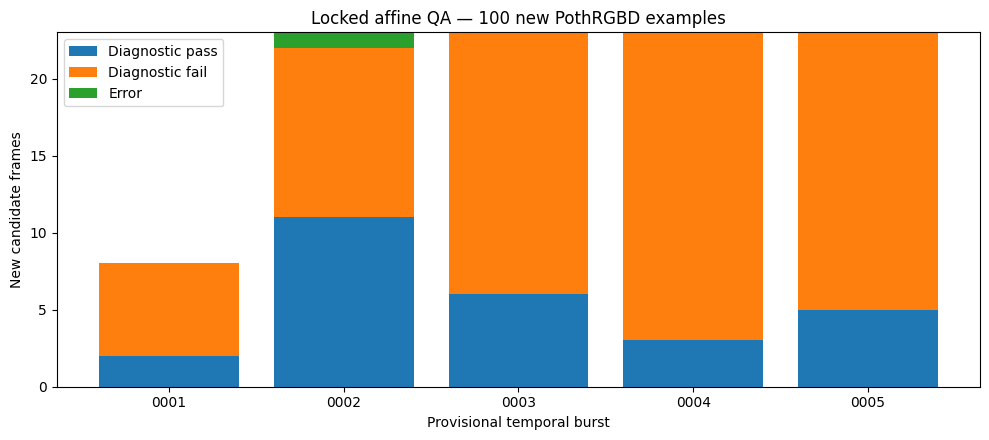


C3-02 SECTION 16 — LOCKED AFFINE TARGET EXPANSION
New development frames attempted: 100
QA statuses: {'DIAGNOSTIC_PASS': 27, 'DIAGNOSTIC_FAIL': 72, 'ERROR': 1}
Saved diagnostic NPZs: 27
Quality threshold changes: NONE
Quadratic fitting used: NO
Train/validation split assigned: NO
Physical metric labels certified: NO
Scientific validation performed: NO
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-02_section16_AFFINE_EXPANSION_20261020T082927_408953Z


In [ ]:

# ============================================================
# CRDL C3-02 SECTION 16 — LOCKED AFFINE TARGET EXPANSION
# 100 NEW DEVELOPMENT SAMPLES
#
# Existing affine method and quality thresholds only.
# No validation/test split, model training or mm conversion.
# All outputs remain NONMETRIC DIAGNOSTICS.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt
import numpy as np
import matplotlib.pyplot as plt
import csv, json, hashlib

BASE = Path(
    "/content/drive/MyDrive/crdl_experiments/"
    "component3_fresh_v1"
)

DATA = Path(
    "/content/drive/MyDrive/manushi_research_data/"
    "pothrgbd/PData-main"
)

S12 = BASE / (
    "03_splits_manifests/"
    "C3-02_section12_PothRGBD_Groups_20261020T075921_028539Z"
)

S13 = BASE / (
    "03_splits_manifests/"
    "C3-02_section13_PothRGBD_SceneQA_20261020T080428_956126Z"
)

S14 = BASE / (
    "04_geometry_targets/"
    "C3-02_section14_PothRGBD_PILOT_20261020T081321_368363Z"
)

S15 = BASE / (
    "02_dataset_audits/"
    "C3-02_section15_Reference_Model_Ablation_20261020T082107_871107Z"
)

for p in (
    DATA / "images",
    DATA / "labels",
    DATA / "depths",
    S12, S13, S14, S15
):
    assert p.is_dir(), str(p)

# ------------------------------------------------------------
# 1. VERIFY ALL PRIOR EXPERIMENT REPORTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, required):
    checks = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, rel = line.split(None, 1)
            rel = rel.strip()
            rp = Path(rel)

            assert not rp.is_absolute()
            assert ".." not in rp.parts
            assert rel not in checks

            checks[rel] = digest

    for name in required:
        assert name in checks
        assert sha(folder / name) == checks[name], name


verify(S12, [
    "capture_group_readiness.json",
    "pothrgbd_filename_capture_manifest.csv"
])

verify(S13, [
    "scene_diversity_report.json",
    "scene_review_samples.csv"
])

verify(S14, ["pilot_quality_report.json"])
verify(S15, ["reference_model_ablation.json"])

q14 = json.loads(
    (S14 / "pilot_quality_report.json").read_text()
)

q15 = json.loads(
    (S15 / "reference_model_ablation.json").read_text()
)

assert q14["status_counts"] == {
    "DIAGNOSTIC_PASS": 6,
    "DIAGNOSTIC_FAIL": 19
}

assert q14["metric_model_training_authorized"] is False
assert q15["compared_count"] == 25
assert q15["quadratic_better_holdout_count"] == 12
assert q15["original_qa_thresholds_unchanged"] is True

# Reuse exact original thresholds.
CFG = dict(q14["configuration"])

print("All previous experiment reports: VERIFIED")
print("Reference method: AFFINE INVERSE DEPTH")
print("Quality threshold changes: NONE")

# ------------------------------------------------------------
# 2. SELECT 100 NEW STRICTLY PAIRED EXAMPLES
# ------------------------------------------------------------

with (
    S12 / "pothrgbd_filename_capture_manifest.csv"
).open(newline="") as f:
    source = list(csv.DictReader(f))

with (
    S13 / "scene_review_samples.csv"
).open(newline="") as f:
    previously = {
        row["sample_id"]
        for row in csv.DictReader(f)
    }

assert len(previously) == 25

assert sum(
    r["strict_pair_verified"] == "True"
    for r in source
) == 996

by_burst = defaultdict(list)

for row in source:

    if (
        row["strict_pair_verified"] == "True"
        and row["sample_id"] not in previously
    ):
        by_burst[
            row["provisional_burst"]
        ].append(row)

selected = []

for j, burst in enumerate(sorted(by_burst)):

    candidates = sorted(
        by_burst[burst],
        key=lambda x: x["sample_id"]
    )

    # Burst 1 has only 8 remaining frames.
    # Other bursts contribute 23 each.
    target_count = 8 if j == 0 else 23

    assert len(candidates) >= target_count

    indices = np.linspace(
        0,
        len(candidates) - 1,
        target_count,
        dtype=int
    )

    assert len(set(indices)) == target_count

    selected.extend(
        candidates[i] for i in indices
    )

    print(
        burst,
        "| eligible:", len(candidates),
        "| selected:", target_count
    )

assert len(selected) == 100

assert len({
    r["sample_id"] for r in selected
}) == 100

print("\nSelected new development examples: 100")
print("Previous 25 development examples: EXCLUDED")

# ------------------------------------------------------------
# 3. ORIGINAL YOLO POLYGON RECONSTRUCTION
# ------------------------------------------------------------

def polygon_mask(path, w, h):

    canvas = Image.new("L", (w, h), 0)
    painter = ImageDraw.Draw(canvas)

    count = 0

    for line in path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        values = np.array(
            [float(v) for v in line.split()],
            dtype=np.float64
        )

        if (
            not np.isfinite(values).all()
            or values[0] != 0
            or len(values) < 7
            or (len(values) - 1) % 2
        ):
            raise ValueError(
                "Unexpected YOLO polygon"
            )

        pts = values[1:].reshape(-1, 2)

        if (
            (pts < -0.001).any()
            or (pts > 1.001).any()
        ):
            raise ValueError(
                "Invalid polygon coordinates"
            )

        pts = np.clip(pts, 0, 1)

        painter.polygon(
            [
                (
                    round(x * (w - 1)),
                    round(y * (h - 1))
                )
                for x, y in pts
            ],
            fill=1
        )

        count += 1

    result = np.asarray(
        canvas, dtype=bool
    )

    if not count or not result.any():
        raise ValueError("Empty annotation")

    return result, count

# ------------------------------------------------------------
# 4. SAME AFFINE REFERENCE MODEL AS SECTION 14
# ------------------------------------------------------------

def basis(xs, ys, w, h):

    return np.column_stack((
        (xs - (w - 1)/2) / w,
        (ys - (h - 1)/2) / h,
        np.ones(len(xs))
    ))


def irls(A, b):

    beta = np.linalg.lstsq(
        A, b, rcond=None
    )[0]

    for _ in range(CFG["irls_iterations"]):

        errors = b - A @ beta
        med = np.median(errors)

        mad = 1.4826 * np.median(
            np.abs(errors - med)
        )

        cutoff = max(
            1.5 * mad, 1e-6
        )

        weights = np.sqrt(
            np.minimum(
                1.0,
                cutoff / np.maximum(
                    np.abs(errors - med),
                    1e-12
                )
            )
        )

        next_beta = np.linalg.lstsq(
            A * weights[:, None],
            b * weights,
            rcond=None
        )[0]

        if np.max(
            np.abs(next_beta - beta)
        ) < 1e-9:
            beta = next_beta
            break

        beta = next_beta

    return beta

# ------------------------------------------------------------
# 5. CREATE VERSIONED DEVELOPMENT OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

OUT = (
    BASE / "04_geometry_targets"
    / f"C3-02_section16_AFFINE_EXPANSION_{stamp}"
)

OUT.mkdir(exist_ok=False)

NPZ = OUT / "diagnostic_pass_npz"
NPZ.mkdir()

results = []

# ------------------------------------------------------------
# 6. APPLY LOCKED REFERENCE METHOD TO 100 EXAMPLES
# ------------------------------------------------------------

for k, row in enumerate(selected, 1):

    sid = row["sample_id"]
    burst = row["provisional_burst"]

    result = {
        "sample_id": sid,
        "burst": burst,
        "capture_day": row["capture_day_group"],
        "status": "ERROR",
        "flags": [],
        "npz": None,
        "metric_training_approved": False,
        "model_training_approved": False,
        "independent_scene_verified": False,
    }

    try:
        paths = {
            "rgb": DATA / "images"
                / row["rgb_filename"],
            "label": DATA / "labels"
                / row["label_filename"],
            "depth": DATA / "depths"
                / row["depth_filename"],
        }

        for path in paths.values():
            assert path.is_file()
            assert not path.is_symlink()

        assert (
            Path(row["rgb_filename"]).stem
            == Path(row["label_filename"]).stem
        )

        with Image.open(paths["rgb"]) as im:
            rgb = np.asarray(im.convert("RGB"))

        depth = np.load(
            paths["depth"],
            allow_pickle=False
        )

        if (
            depth.dtype != np.uint16
            or depth.ndim != 2
            or depth.shape != rgb.shape[:2]
        ):
            raise ValueError(
                "Incompatible RGB/depth shapes or dtype"
            )

        h, w = depth.shape

        mask, n_polygons = polygon_mask(
            paths["label"], w, h
        )

        finite = depth > 0

        dist = distance_transform_edt(~mask)

        ring = (
            finite
            & (dist >= CFG["ring_min_px"])
            & (dist <= CFG["ring_max_px"])
        )

        ry, rx = np.nonzero(ring)

        if len(rx) < CFG["min_support_pixels"]:
            raise ValueError(
                "Insufficient surrounding-road support"
            )

        rng = np.random.default_rng(
            CFG["seed"] + int(sid[-6:])
        )

        pick = rng.choice(
            len(rx),
            size=min(
                CFG["max_ring_samples"],
                len(rx)
            ),
            replace=False
        )

        ry, rx = ry[pick], rx[pick]

        z = depth[ry, rx].astype(
            np.float64
        )

        low, high = np.quantile(
            z, [0.001, 0.999]
        )

        keep = (z >= low) & (z <= high)

        ry, rx, z = (
            ry[keep],
            rx[keep],
            z[keep]
        )

        A = basis(rx, ry, w, h)

        # Numerical conditioning ONLY.
        # This is not a conversion to millimetres.
        inv = 1000.0 / z

        beta = irls(A, inv)

        fitted = A @ beta

        if (fitted <= 0).any():
            raise ValueError(
                "Nonpositive reference depth"
            )

        road_p95 = float(
            np.percentile(
                np.abs(z - 1000.0 / fitted),
                95
            )
        )

        # ----------------------------------------------------
        # 7. FOUR-SECTOR ROAD HOLDOUT CHECK
        # ----------------------------------------------------

        cy, cx = np.mean(
            np.nonzero(mask),
            axis=1
        )

        angles = np.mod(
            np.arctan2(
                ry - cy,
                rx - cx
            ) + 2*np.pi,
            2*np.pi
        )

        sectors = np.minimum(
            (
                angles / (np.pi/2)
            ).astype(int),
            3
        )

        folds = []

        for sector in range(4):

            test = sectors == sector
            train = ~test

            if (
                test.sum()
                < CFG["min_sector_test_pixels"]
                or train.sum()
                < CFG["min_support_pixels"]
            ):
                folds.append(None)
                continue

            cv = irls(
                A[train],
                inv[train]
            )

            pred = A[test] @ cv

            if (pred <= 0).any():
                folds.append(None)
                continue

            folds.append(
                float(
                    np.percentile(
                        np.abs(
                            z[test] - 1000.0/pred
                        ),
                        95
                    )
                )
            )

        # ----------------------------------------------------
        # 8. CAMERA-AXIS RESIDUAL TARGET
        # ----------------------------------------------------

        yy, xx = np.nonzero(
            mask & finite
        )

        pred = (
            basis(xx, yy, w, h) @ beta
        )

        okay = pred > 0

        reference = np.full(
            len(pred),
            np.nan,
            dtype=np.float64
        )

        reference[okay] = (
            1000.0 / pred[okay]
        )

        observed = depth[
            yy, xx
        ].astype(np.float64)

        plausible = (
            okay
            & (
                observed
                >= CFG["sensor_ratio_min"]
                * reference
            )
            & (
                observed
                <= CFG["sensor_ratio_max"]
                * reference
            )
        )

        residual = np.full(
            (h, w),
            np.nan,
            dtype=np.float32
        )

        residual[
            yy[plausible],
            xx[plausible]
        ] = (
            observed[plausible]
            - reference[plausible]
        ).astype(np.float32)

        valid = np.isfinite(residual)

        values = residual[valid]

        if len(values) < 100:
            raise ValueError(
                "Insufficient valid target pixels"
            )

        coverage = float(
            valid.sum() / mask.sum()
        )

        magnitude = float(
            np.median(np.abs(values))
        )

        positive = float(
            np.mean(values > 0)
        )

        signal = float(
            magnitude / max(road_p95, 1e-9)
        )

        worst = (
            float(max(folds))
            if all(v is not None for v in folds)
            else None
        )

        ratio = (
            float(
                worst / max(magnitude, 1e-9)
            )
            if worst is not None
            else None
        )

        # ----------------------------------------------------
        # 9. EXISTING QA THRESHOLDS — UNCHANGED
        # ----------------------------------------------------

        flags = []

        if coverage < CFG[
            "min_valid_target_fraction"
        ]:
            flags.append("LOW_VALID_GEOMETRY")

        if positive < CFG[
            "min_positive_fraction"
        ]:
            flags.append("AMBIGUOUS_RESIDUAL_SIGN")

        if signal < CFG[
            "min_signal_to_road_p95"
        ]:
            flags.append("LOW_GEOMETRY_SIGNAL")

        if worst is None:
            flags.append(
                "INCOMPLETE_SPATIAL_HOLDOUT"
            )

        elif ratio > CFG[
            "max_worst_holdout_to_signal"
        ]:
            flags.append(
                "WEAK_SPATIAL_HOLDOUT"
            )

        status = (
            "DIAGNOSTIC_FAIL"
            if flags
            else "DIAGNOSTIC_PASS"
        )

        result.update({
            "status": status,
            "flags": flags,
            "polygons": n_polygons,
            "mask_pixels": int(mask.sum()),
            "valid_target_pixels": int(
                valid.sum()
            ),
            "coverage": coverage,
            "road_p95_raw": road_p95,
            "holdout_p95_raw_by_sector": folds,
            "worst_holdout_raw": worst,
            "median_signed_raw": float(
                np.median(values)
            ),
            "median_abs_raw": magnitude,
            "positive_fraction": positive,
            "signal_to_road_p95": signal,
            "holdout_to_signal": ratio,
            "rgb_sha256": sha(paths["rgb"]),
            "label_sha256": sha(paths["label"]),
            "depth_sha256": sha(paths["depth"]),
        })

        # ----------------------------------------------------
        # 10. SAVE ONLY DIAGNOSTIC PASSES
        # ----------------------------------------------------

        if status == "DIAGNOSTIC_PASS":

            path = NPZ / (
                f"{sid}_axial_raw.npz"
            )

            np.savez_compressed(
                path,
                signed_axial_raw=residual,
                damage_mask=mask.astype(
                    np.uint8
                ),
                valid_target_mask=valid.astype(
                    np.uint8
                ),
                inv_depth_plane_beta=beta,
                units="UNVERIFIED_RAW_SENSOR",
                source_sample_id=sid
            )

            with np.load(
                path,
                allow_pickle=False
            ) as saved:

                assert np.array_equal(
                    np.isfinite(
                        saved["signed_axial_raw"]
                    ),
                    saved[
                        "valid_target_mask"
                    ].astype(bool)
                )

            result["npz"] = str(
                path.relative_to(OUT)
            )

    except Exception as exc:

        result["status"] = "ERROR"

        result["flags"] = [
            f"{type(exc).__name__}: {exc}"
        ]

    results.append(result)

    if k % 10 == 0 or k == 1:

        print(
            f"{k}/100 processed |",
            dict(
                Counter(
                    r["status"]
                    for r in results
                )
            )
        )

# ------------------------------------------------------------
# 11. SAVE COMPLETE VERSIONED RESEARCH REPORT
# ------------------------------------------------------------

counts = Counter(
    r["status"] for r in results
)

assert len(results) == 100

report = {
    "milestone": "C3-02",
    "section": 16,
    "version": "1.0",
    "source_12_sha": sha(
        S12 / "capture_group_readiness.json"
    ),
    "source_13_sha": sha(
        S13 / "scene_diversity_report.json"
    ),
    "source_14_sha": sha(
        S14 / "pilot_quality_report.json"
    ),
    "source_15_sha": sha(
        S15 / "reference_model_ablation.json"
    ),
    "source_rule": "UNCHANGED_SECTION14_AFFINE",
    "new_examples_not_in_section13_review": True,
    "quadratic_fit_used": False,
    "config": CFG,
    "counts": dict(counts),
    "records": results,
    "capture_bursts_prove_independence": False,
    "training_split_created": False,
    "metric_scale_certified": False,
    "metric_supervision_authorized": False,
    "npz_are_diagnostic_only": True,
    "protected_benchmark_directly_read": False,
}

(OUT / "expansion_quality_report.json").write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

columns = [
    "sample_id",
    "burst",
    "capture_day",
    "status",
    "flags",
    "coverage",
    "road_p95_raw",
    "worst_holdout_raw",
    "median_signed_raw",
    "signal_to_road_p95",
    "holdout_to_signal",
    "npz",
    "rgb_sha256",
    "label_sha256",
    "depth_sha256",
    "metric_training_approved",
    "model_training_approved",
]

with (
    OUT / "expansion_manifest.csv"
).open("w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=columns,
        extrasaction="ignore"
    )

    writer.writeheader()

    for row in results:
        writer.writerow({
            key: (
                json.dumps(value)
                if isinstance(value, (list, dict))
                else value
            )
            for key, value in row.items()
        })

# ------------------------------------------------------------
# 12. VISUALIZE ACCEPTANCE BY CAPTURE BURST
# ------------------------------------------------------------

by = defaultdict(Counter)

for row in results:
    by[row["burst"]][row["status"]] += 1

burst_names = sorted(by)

passes = [
    by[b]["DIAGNOSTIC_PASS"]
    for b in burst_names
]

fails = [
    by[b]["DIAGNOSTIC_FAIL"]
    for b in burst_names
]

errors = [
    by[b]["ERROR"]
    for b in burst_names
]

fig, ax = plt.subplots(
    figsize=(10, 4.5)
)

x = np.arange(len(burst_names))

ax.bar(
    x, passes,
    label="Diagnostic pass"
)

ax.bar(
    x, fails,
    bottom=passes,
    label="Diagnostic fail"
)

ax.bar(
    x, errors,
    bottom=np.array(passes) + np.array(fails),
    label="Error"
)

ax.set_xticks(
    x,
    [
        n.split("_")[-1]
        for n in burst_names
    ]
)

ax.set_xlabel(
    "Provisional temporal burst"
)

ax.set_ylabel(
    "New candidate frames"
)

ax.set_title(
    "Locked affine QA — "
    "100 new PothRGBD examples"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    OUT / "acceptance_by_burst.png",
    dpi=140
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 13. EXPORT CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(
    OUT.rglob("*")
):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-02 SECTION 16 — LOCKED AFFINE TARGET EXPANSION")
print("=" * 65)

print("New development frames attempted: 100")
print("QA statuses:", dict(counts))

print(
    "Saved diagnostic NPZs:",
    len(list(NPZ.glob("*.npz")))
)

print("Quality threshold changes: NONE")
print("Quadratic fitting used: NO")
print("Train/validation split assigned: NO")
print("Physical metric labels certified: NO")
print("Scientific validation performed: NO")
print("Output:", OUT)

print("=" * 65)
